<a href="https://colab.research.google.com/github/surigisrividya-code/Drug-Synergy-Prediction/blob/main/drug_synergy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import os
import pandas as pd
import numpy as np
import gc

BASE_DIR = "/content/drive/MyDrive/drug_synergy_project"

DATA_DIR = os.path.join(BASE_DIR, "data")
PROCESSED_DIR = os.path.join(BASE_DIR, "processed")
MODEL_DIR = os.path.join(BASE_DIR, "models")

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print("Project folders ready")
print("Data folder:", DATA_DIR)
print("Processed folder:", PROCESSED_DIR)
print("Model folder:", MODEL_DIR)

Project folders ready
Data folder: /content/drive/MyDrive/drug_synergy_project/data
Processed folder: /content/drive/MyDrive/drug_synergy_project/processed
Model folder: /content/drive/MyDrive/drug_synergy_project/models


In [ ]:
import os

print("Files in MyDrive:")
print(os.listdir("/content/drive/MyDrive"))

Files in MyDrive:
['Classroom', 'Colab Notebooks', 'drug_synergy_project']


In [ ]:
# ============================================================
# CELL 2: FIND AND SET ALL DATASET PATHS
# ============================================================

import os
import pandas as pd
import numpy as np
import gc

DRIVE = "/content/drive/MyDrive"

target_files = [
    "drugcombs_scored.csv",
    "cell_Line.csv",
    "drug_chemical_info.csv",
    "Expression_(Short-read)_Public_26Q1_subsetted.csv",
    "summary_gdsc_integrated.csv",
    "drugcombs_response.csv"
]

found_files = {}

for root, dirs, files in os.walk(DRIVE):
    for file in files:
        if file in target_files:
            found_files[file] = os.path.join(root, file)

print("Files found:")
print("=" * 70)

for name in target_files:
    print(name)
    print(" ->", found_files[name])
    print()

# ------------------------------------------------------------
# Assign exact paths automatically
# ------------------------------------------------------------

scored_path = found_files["drugcombs_scored.csv"]

cell_path = found_files["cell_Line.csv"]

chemical_path = found_files["drug_chemical_info.csv"]

expression_path = found_files[
    "Expression_(Short-read)_Public_26Q1_subsetted.csv"
]

gdsc_path = found_files["summary_gdsc_integrated.csv"]

response_path = found_files["drugcombs_response.csv"]

# ------------------------------------------------------------
# Create processed/model folders beside your datasets
# ------------------------------------------------------------

BASE_DIR = os.path.dirname(scored_path)

PROCESSED_DIR = os.path.join(BASE_DIR, "processed")
MODEL_DIR = os.path.join(BASE_DIR, "models")

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print("=" * 70)
print("All paths configured successfully.")
print("BASE_DIR:", BASE_DIR)
print("PROCESSED_DIR:", PROCESSED_DIR)
print("MODEL_DIR:", MODEL_DIR)

Files found:
drugcombs_scored.csv
 -> /content/drive/MyDrive/drug_synergy_project/drugcombs_scored.csv

cell_Line.csv
 -> /content/drive/MyDrive/drug_synergy_project/cell_Line.csv

drug_chemical_info.csv
 -> /content/drive/MyDrive/drug_synergy_project/drug_chemical_info.csv

Expression_(Short-read)_Public_26Q1_subsetted.csv
 -> /content/drive/MyDrive/drug_synergy_project/Expression_(Short-read)_Public_26Q1_subsetted.csv

summary_gdsc_integrated.csv
 -> /content/drive/MyDrive/drug_synergy_project/summary_gdsc_integrated.csv

drugcombs_response.csv
 -> /content/drive/MyDrive/drug_synergy_project/drugcombs_response.csv

All paths configured successfully.
BASE_DIR: /content/drive/MyDrive/drug_synergy_project
PROCESSED_DIR: /content/drive/MyDrive/drug_synergy_project/processed
MODEL_DIR: /content/drive/MyDrive/drug_synergy_project/models


In [ ]:
# ============================================================
# CELL 3: LOAD SMALLER DATASETS
# ============================================================

print("Loading drug synergy scored data...")
scored_df = pd.read_csv(
    scored_path,
    encoding="latin1",
    low_memory=False
)

print("Loading cell-line data...")
cell_df = pd.read_csv(
    cell_path,
    encoding="latin1",
    low_memory=False
)

print("Loading drug chemical information...")
chemical_df = pd.read_csv(
    chemical_path,
    encoding="latin1",
    low_memory=False
)

print("Loading integrated GDSC data...")
gdsc_df = pd.read_csv(
    gdsc_path,
    encoding="latin1",
    low_memory=False
)

print("\n" + "=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("drugcombs_scored:", scored_df.shape)
print("cell_Line:", cell_df.shape)
print("drug_chemical_info:", chemical_df.shape)
print("summary_gdsc_integrated:", gdsc_df.shape)

Loading drug synergy scored data...
Loading cell-line data...
Loading drug chemical information...
Loading integrated GDSC data...

DATASET INFORMATION
drugcombs_scored: (498865, 8)
cell_Line: (104, 3)
drug_chemical_info: (3059, 5)
summary_gdsc_integrated: (18200, 30)


In [ ]:
# ============================================================
# CELL 4: CHECK COLUMN NAMES
# ============================================================

print("\n===== DRUGCOMBS SCORED =====")
print(scored_df.columns.tolist())

print("\n===== CELL LINE =====")
print(cell_df.columns.tolist())

print("\n===== DRUG CHEMICAL INFO =====")
print(chemical_df.columns.tolist())

print("\n===== GDSC INTEGRATED =====")
print(gdsc_df.columns.tolist())


===== DRUGCOMBS SCORED =====
['ID', 'Drug1', 'Drug2', 'Cell line', 'ZIP', 'Bliss', 'Loewe', 'HSA']

===== CELL LINE =====
['ï»¿"cellName"', 'cosmicId', 'tag']

===== DRUG CHEMICAL INFO =====
['drugName', 'cIds', 'drugNameOfficial', 'molecularWeight', 'smilesString']

===== GDSC INTEGRATED =====
['block_id', 'drug_row', 'drug_col', 'cell_line_name', 'conc_r_unit', 'conc_c_unit', 'css', 'synergy_zip', 'synergy_bliss', 'synergy_loewe', 'synergy_hsa', 'ic50_row', 'ic50_col', 'ri_row', 'ri_col', 'css_row', 'css_col', 'S', 'GDSC1_ROW_LN_IC50', 'GDSC1_ROW_AUC', 'GDSC1_ROW_Z_SCORE', 'GDSC2_ROW_LN_IC50', 'GDSC2_ROW_AUC', 'GDSC2_ROW_Z_SCORE', 'GDSC1_COL_LN_IC50', 'GDSC1_COL_AUC', 'GDSC1_COL_Z_SCORE', 'GDSC2_COL_LN_IC50', 'GDSC2_COL_AUC', 'GDSC2_COL_Z_SCORE']


In [ ]:
# ============================================================
# CELL 5: PREVIEW DATA
# ============================================================

print("===== SCORED DATA =====")
display(scored_df.head())

print("\n===== CELL LINE DATA =====")
display(cell_df.head())

print("\n===== CHEMICAL DATA =====")
display(chemical_df.head())

print("\n===== GDSC DATA =====")
display(gdsc_df.head())

===== SCORED DATA =====


,ID,Drug1,Drug2,Cell line,ZIP,Bliss,Loewe,HSA
0,1,5-FU,ABT-888,A2058,1.72,6.26,-2.75,5.54
1,2,5-FU,ABT-888,A2058,5.88,12.33,3.33,11.61
2,3,5-FU,ABT-888,A2058,3.59,11.66,2.65,10.94
3,4,5-FU,ABT-888,A2058,-0.85,5.15,-3.86,4.43
4,5,5-FU,AZD1775,A2058,12.29,15.77,10.40,18.66



===== CELL LINE DATA =====


,"ï»¿""cellName""",cosmicId,tag
0,786-0,905947.0,NaN
1,A498,905948.0,NaN
2,A549/ATCC,905949.0,NaN
3,ACHN,905950.0,NaN
4,CCRF-CEM,905952.0,NaN



===== CHEMICAL DATA =====


,drugName,cIds,drugNameOfficial,molecularWeight,smilesString
0,Bendamustine,CIDs00065628,bendamustine,358.26284,CN1C2=C(C=C(C=C2)N(CCCl)CCCl)N=C1CCCC(=O)O
1,Lonidamine,CIDs00039562,lonidamine,321.15810,C1=CC=C2C(=C1)C(=NN2CC3=C(C=C(C=C3)Cl)Cl)C(=O)O
2,Lenalidomide,CIDs00216326,lenalidomide,259.26062,C1CC(=O)NC(=O)C1N2CC3=C(C2=O)C=CC=C3N
3,Cladribine,CIDs00020279,cladribine,285.68698,C1C(C(OC1N2C=NC3=C2N=C(N=C3N)Cl)CO)O
4,Pentostatin,CIDs00439693,pentostatin,268.26914,C1C(C(OC1N2C=NC3=C2NC=NCC3O)CO)O



===== GDSC DATA =====


,block_id,drug_row,drug_col,cell_line_name,conc_r_unit,conc_c_unit,css,synergy_zip,synergy_bliss,synergy_loewe,...,GDSC1_ROW_Z_SCORE,GDSC2_ROW_LN_IC50,GDSC2_ROW_AUC,GDSC2_ROW_Z_SCORE,GDSC1_COL_LN_IC50,GDSC1_COL_AUC,GDSC1_COL_Z_SCORE,GDSC2_COL_LN_IC50,GDSC2_COL_AUC,GDSC2_COL_Z_SCORE
0,217,BORTEZOMIB,DASATINIB,A2058,uM,uM,74.7920,6.401539,7.889876,3.040005,...,NaN,-5.761897,0.708442,-0.95733,NaN,NaN,NaN,3.347652,0.988830,0.886553
1,218,BORTEZOMIB,DASATINIB,A2058,uM,uM,58.1720,0.400155,-0.324311,-5.174182,...,NaN,-5.761897,0.708442,-0.95733,NaN,NaN,NaN,3.347652,0.988830,0.886553
2,219,BORTEZOMIB,DASATINIB,A2058,uM,uM,66.5320,-1.609176,3.329001,-1.520870,...,NaN,-5.761897,0.708442,-0.95733,NaN,NaN,NaN,3.347652,0.988830,0.886553
3,220,BORTEZOMIB,DASATINIB,A2058,uM,uM,60.0390,3.526737,4.822939,-0.026932,...,NaN,-5.761897,0.708442,-0.95733,NaN,NaN,NaN,3.347652,0.988830,0.886553
4,221,BORTEZOMIB,DINACICLIB,A2058,uM,uM,73.1595,2.327725,3.383266,-0.987575,...,NaN,-5.761897,0.708442,-0.95733,NaN,NaN,NaN,-2.927546,0.570207,-0.185347


In [ ]:
# ============================================================
# CELL 7: CLEAN COLUMN NAMES
# ============================================================

def clean_columns(df):
    df.columns = (
        df.columns
        .astype(str)
        .str.replace("\ufeff", "", regex=False)
        .str.replace("ï»¿", "", regex=False)
        .str.replace('"', "", regex=False)
        .str.strip()
    )
    return df


scored_df = clean_columns(scored_df)
cell_df = clean_columns(cell_df)
chemical_df = clean_columns(chemical_df)
gdsc_df = clean_columns(gdsc_df)

print("SCORED:")
print(scored_df.columns.tolist())

print("\nCELL:")
print(cell_df.columns.tolist())

print("\nCHEMICAL:")
print(chemical_df.columns.tolist())

print("\nGDSC:")
print(gdsc_df.columns.tolist())

SCORED:
['ID', 'Drug1', 'Drug2', 'Cell line', 'ZIP', 'Bliss', 'Loewe', 'HSA']

CELL:
['cellName', 'cosmicId', 'tag']

CHEMICAL:
['drugName', 'cIds', 'drugNameOfficial', 'molecularWeight', 'smilesString']

GDSC:
['block_id', 'drug_row', 'drug_col', 'cell_line_name', 'conc_r_unit', 'conc_c_unit', 'css', 'synergy_zip', 'synergy_bliss', 'synergy_loewe', 'synergy_hsa', 'ic50_row', 'ic50_col', 'ri_row', 'ri_col', 'css_row', 'css_col', 'S', 'GDSC1_ROW_LN_IC50', 'GDSC1_ROW_AUC', 'GDSC1_ROW_Z_SCORE', 'GDSC2_ROW_LN_IC50', 'GDSC2_ROW_AUC', 'GDSC2_ROW_Z_SCORE', 'GDSC1_COL_LN_IC50', 'GDSC1_COL_AUC', 'GDSC1_COL_Z_SCORE', 'GDSC2_COL_LN_IC50', 'GDSC2_COL_AUC', 'GDSC2_COL_Z_SCORE']


In [ ]:
# ============================================================
# CELL 8: CLEAN MAIN SYNERGY DATA
# ============================================================

# Standardize text columns
for col in ["Drug1", "Drug2", "Cell line"]:
    scored_df[col] = (
        scored_df[col]
        .astype(str)
        .str.strip()
    )

# Standardize drug names
scored_df["Drug1"] = scored_df["Drug1"].str.upper()
scored_df["Drug2"] = scored_df["Drug2"].str.upper()

# Standardize cell-line names
scored_df["Cell line"] = scored_df["Cell line"].str.upper()

# Convert target columns to numeric
for col in ["ZIP", "Bliss", "Loewe", "HSA"]:
    scored_df[col] = pd.to_numeric(
        scored_df[col],
        errors="coerce"
    )

# Remove rows without the main information
scored_df = scored_df.dropna(
    subset=["Drug1", "Drug2", "Cell line", "ZIP"]
).copy()

print("Final scored dataset shape:")
print(scored_df.shape)

print("\nMissing values:")
print(
    scored_df[
        ["Drug1", "Drug2", "Cell line",
         "ZIP", "Bliss", "Loewe", "HSA"]
    ].isna().sum()
)

display(scored_df.head())

Final scored dataset shape:
(498865, 8)

Missing values:
Drug1        0
Drug2        0
Cell line    0
ZIP          0
Bliss        0
Loewe        1
HSA          0
dtype: int64


,ID,Drug1,Drug2,Cell line,ZIP,Bliss,Loewe,HSA
0,1,5-FU,ABT-888,A2058,1.72,6.26,-2.75,5.54
1,2,5-FU,ABT-888,A2058,5.88,12.33,3.33,11.61
2,3,5-FU,ABT-888,A2058,3.59,11.66,2.65,10.94
3,4,5-FU,ABT-888,A2058,-0.85,5.15,-3.86,4.43
4,5,5-FU,AZD1775,A2058,12.29,15.77,10.40,18.66


In [ ]:
# ============================================================
# CELL 9: CLEAN CHEMICAL DATA
# ============================================================

chemical_df["drugName"] = (
    chemical_df["drugName"]
    .astype(str)
    .str.strip()
)

chemical_df["drugNameOfficial"] = (
    chemical_df["drugNameOfficial"]
    .astype(str)
    .str.strip()
)

chemical_df["drugName_clean"] = (
    chemical_df["drugName"]
    .str.upper()
)

chemical_df["drugNameOfficial_clean"] = (
    chemical_df["drugNameOfficial"]
    .str.upper()
)

# Keep only useful columns
chemical_features = chemical_df[
    [
        "drugName",
        "drugNameOfficial",
        "cIds",
        "molecularWeight",
        "smilesString",
        "drugName_clean",
        "drugNameOfficial_clean"
    ]
].copy()

# Remove duplicate drug names
chemical_features = chemical_features.drop_duplicates(
    subset=["drugName_clean"]
)

print("Chemical dataset shape:")
print(chemical_features.shape)

display(chemical_features.head())

Chemical dataset shape:
(3058, 7)


,drugName,drugNameOfficial,cIds,molecularWeight,smilesString,drugName_clean,drugNameOfficial_clean
0,Bendamustine,bendamustine,CIDs00065628,358.26284,CN1C2=C(C=C(C=C2)N(CCCl)CCCl)N=C1CCCC(=O)O,BENDAMUSTINE,BENDAMUSTINE
1,Lonidamine,lonidamine,CIDs00039562,321.15810,C1=CC=C2C(=C1)C(=NN2CC3=C(C=C(C=C3)Cl)Cl)C(=O)O,LONIDAMINE,LONIDAMINE
2,Lenalidomide,lenalidomide,CIDs00216326,259.26062,C1CC(=O)NC(=O)C1N2CC3=C(C2=O)C=CC=C3N,LENALIDOMIDE,LENALIDOMIDE
3,Cladribine,cladribine,CIDs00020279,285.68698,C1C(C(OC1N2C=NC3=C2N=C(N=C3N)Cl)CO)O,CLADRIBINE,CLADRIBINE
4,Pentostatin,pentostatin,CIDs00439693,268.26914,C1C(C(OC1N2C=NC3=C2NC=NCC3O)CO)O,PENTOSTATIN,PENTOSTATIN


In [ ]:
# ============================================================
# CELL 10: CHECK CHEMICAL COVERAGE
# ============================================================

main_drugs = set(
    pd.concat([
        scored_df["Drug1"],
        scored_df["Drug2"]
    ])
    .dropna()
    .unique()
)

chemical_drugs = set(
    chemical_features["drugName_clean"]
    .dropna()
    .unique()
)

common_drugs = main_drugs.intersection(
    chemical_drugs
)

print("Unique drugs in main synergy dataset:",
      len(main_drugs))

print("Unique drugs in chemical dataset:",
      len(chemical_drugs))

print("Directly matched drugs:",
      len(common_drugs))

print(
    "Chemical coverage:",
    round(
        len(common_drugs) /
        len(main_drugs) * 100,
        2
    ),
    "%"
)

print("\nFirst 30 unmatched drugs:")

unmatched = sorted(main_drugs - chemical_drugs)

for drug in unmatched[:30]:
    print(drug)

Unique drugs in main synergy dataset: 5351
Unique drugs in chemical dataset: 3058
Directly matched drugs: 3039
Chemical coverage: 56.79 %

First 30 unmatched drugs:
(+)-BICUCULLINE
(+)-BLEBBISTATIN
(+)-MATRINE
(+\\/-)-SULFINPYRAZONE
(-)-CHLORPHENIRAMINE
(-)-EPIGALLOCATECHIN GALLATE
(-)-ETHYL APOVINCAMINATE
(-)-HUPERZINE A (HUPA)
(-)-MK 801 MALEATE
(-)-PARTHENOLIDE
(13S)-3-HYDROXY-13-METHYL-7,8,9,11,12,14,15,16-OCTAHYDRO-6H-CYCLOPENTA[A]PHENANTHREN-17-ONE
(2R,3R,4S,5R,6S)-2-(HYDROXYMETHYL)-6-(4-HYDROXYPHENOXY)OXANE-3,4,5-TRIOL
(2Z,4E,6E,8E)-N-(4-HYDROXYPHENYL)-3,7-DIMETHYL-9-(2,6,6-TRIMETHYL-1-CYCLOHEXENYL)NONA-2,4,6,8-TETRAENAMIDE
(3ALPHA,5BETA,7ALPHA)-3,7-DIHYDROXYCHOLAN-24-OIC ACID
(3S,4R)-TOFACITINIB
(6-)E-<U+200B>AMINOCAPROIC ACID
(6R)-5,10-METHYLENETETRAHYDROFOLATE
(8R,9S,10R,13S,14R,17R)-17-HYDROXY-10,13-DIMETHYL-1,2,6,7,8,9,11,12,14,15,16,17-DODECAHYDROCYCLOPENTA[A]PHENANTHREN-3-ONE
(E)-1-(4-((6-AMINO-5-((METHOXYIMINO)METHYL)PYRIMIDIN-4-YL)OXY)-2-CHLOROPHENYL)-3-ETHYLUREA
(E)-N-

In [ ]:
# ============================================================
# CELL 11: CLEAN CELL-LINE DATASET
# ============================================================

import pandas as pd

# Load using utf-8-sig because the file contains a BOM
cell_df = pd.read_csv(
    cell_path,
    encoding="utf-8-sig",
    quotechar='"',
    low_memory=False
)

# Clean column names
cell_df.columns = (
    cell_df.columns
    .astype(str)
    .str.strip()
    .str.strip('"')
)

print("Cell-line columns:")
print(cell_df.columns.tolist())

# Verify the required column exists
if "cellName" not in cell_df.columns:
    raise ValueError(
        f"'cellName' column not found. Actual columns: {cell_df.columns.tolist()}"
    )

# Clean cell names
cell_df["cellName"] = (
    cell_df["cellName"]
    .astype(str)
    .str.strip()
)

# Clean other columns if present
if "cosmicId" in cell_df.columns:
    cell_df["cosmicId"] = pd.to_numeric(
        cell_df["cosmicId"],
        errors="coerce"
    )

if "tag" in cell_df.columns:
    cell_df["tag"] = (
        cell_df["tag"]
        .astype(str)
        .str.strip()
    )

print("\nCell-line dataset shape:")
print(cell_df.shape)

print("\nFirst 5 rows:")
display(cell_df.head())

Cell-line columns:
['cellName', 'cosmicId', 'tag']

Cell-line dataset shape:
(104, 3)

First 5 rows:


,cellName,cosmicId,tag
0,786-0,905947.0,nan
1,A498,905948.0,nan
2,A549/ATCC,905949.0,nan
3,ACHN,905950.0,nan
4,CCRF-CEM,905952.0,nan


In [ ]:
# ============================================================
# CELL 12: CHECK CELL-LINE MATCHING
# ============================================================

# Make sure both datasets have clean cell-line names
scored_df["Cell line"] = (
    scored_df["Cell line"]
    .astype(str)
    .str.strip()
)

cell_df["cellName"] = (
    cell_df["cellName"]
    .astype(str)
    .str.strip()
)

# Get unique cell lines
scored_cell_lines = set(scored_df["Cell line"].dropna().unique())
cell_file_lines = set(cell_df["cellName"].dropna().unique())

# Find matching and non-matching cell lines
matching_cell_lines = scored_cell_lines.intersection(cell_file_lines)
missing_cell_lines = scored_cell_lines.difference(cell_file_lines)

print("============================================================")
print("CELL-LINE MATCHING RESULTS")
print("============================================================")

print("Unique cell lines in drugcombs_scored.csv :", len(scored_cell_lines))
print("Unique cell lines in cell_Line.csv        :", len(cell_file_lines))
print("Matching cell lines                      :", len(matching_cell_lines))
print("Non-matching cell lines                   :", len(missing_cell_lines))

if len(scored_cell_lines) > 0:
    coverage = (
        len(matching_cell_lines) /
        len(scored_cell_lines)
    ) * 100

    print(f"Cell-line coverage                       : {coverage:.2f}%")

print("\nMatching cell lines:")
print(sorted(list(matching_cell_lines))[:30])

print("\nNon-matching cell lines:")
print(sorted(list(missing_cell_lines))[:30])

CELL-LINE MATCHING RESULTS
Unique cell lines in drugcombs_scored.csv : 123
Unique cell lines in cell_Line.csv        : 104
Matching cell lines                      : 91
Non-matching cell lines                   : 32
Cell-line coverage                       : 73.98%

Matching cell lines:
['786-0', 'A-375', 'A2058', 'A2780', 'A375', 'A427', 'A498', 'ACHN', 'BT-549', 'CAKI-1', 'CAOV3', 'CCRF-CEM', 'COLO 205', 'COLO 858', 'COLO320DM', 'DLD1', 'DU-145', 'EFM192B', 'EKVX', 'ES2', 'HCC-2998', 'HCT-15', 'HCT116', 'HL-60(TB)', 'HOP-62', 'HOP-92', 'HS 578T', 'HT144', 'HT29', 'IGROV1']

Non-matching cell lines:
['3D7', 'A-673', 'A549', 'CTR', 'DD2', 'DIPG25', 'ED-40515', 'EW-8', 'HB3', 'HDLM-2', 'HUH-7', 'JHH-136', 'JHH-520', 'KB-3-1', 'KB-CHR-8-5-11', 'KBM-7', 'L-1236', 'L-428', 'MAK', 'MDA-MB-231', 'MZ7-MEL', 'NCI\\\\/ADR-RES', 'PANC-1', 'RD', 'RH36', 'SMS-CTR', 'SU-DIPG-XIII', 'T98G', 'TC-32', 'TC-71']


In [ ]:
# ============================================================
# CELL 13: MERGE CELL-LINE INFORMATION
# ============================================================

# Keep only the columns we need from cell_Line.csv
cell_features = cell_df[
    ["cellName", "cosmicId", "tag"]
].copy()

# Remove duplicate cell names if any
cell_features = cell_features.drop_duplicates(
    subset=["cellName"]
)

# Merge using EXACT cell-line names
merged_df = scored_df.merge(
    cell_features,
    left_on="Cell line",
    right_on="cellName",
    how="left"
)

print("============================================================")
print("CELL-LINE MERGE RESULTS")
print("============================================================")

print("Original scored dataset shape :", scored_df.shape)
print("After cell-line merge         :", merged_df.shape)

# Check how many rows received a cosmic ID
matched_rows = merged_df["cosmicId"].notna().sum()
total_rows = len(merged_df)

print("\nRows with cell-line information :", matched_rows)
print("Rows without cell-line info     :", total_rows - matched_rows)

if total_rows > 0:
    row_coverage = matched_rows / total_rows * 100
    print(f"Row-level cell-line coverage    : {row_coverage:.2f}%")

print("\nFirst 5 merged rows:")
display(
    merged_df[
        [
            "Drug1",
            "Drug2",
            "Cell line",
            "ZIP",
            "Bliss",
            "Loewe",
            "HSA",
            "cosmicId",
            "tag"
        ]
    ].head()
)

CELL-LINE MERGE RESULTS
Original scored dataset shape : (498865, 8)
After cell-line merge         : (498865, 11)

Rows with cell-line information : 373823
Rows without cell-line info     : 125042
Row-level cell-line coverage    : 74.93%

First 5 merged rows:


,Drug1,Drug2,Cell line,ZIP,Bliss,Loewe,HSA,cosmicId,tag
0,5-FU,ABT-888,A2058,1.72,6.26,-2.75,5.54,906792.0,nan
1,5-FU,ABT-888,A2058,5.88,12.33,3.33,11.61,906792.0,nan
2,5-FU,ABT-888,A2058,3.59,11.66,2.65,10.94,906792.0,nan
3,5-FU,ABT-888,A2058,-0.85,5.15,-3.86,4.43,906792.0,nan
4,5-FU,AZD1775,A2058,12.29,15.77,10.40,18.66,906792.0,nan


In [ ]:
# ============================================================
# CELL 14: CHECK DRUG CHEMICAL INFORMATION COVERAGE
# ============================================================

# Clean chemical dataset columns
chemical_df.columns = (
    chemical_df.columns
    .astype(str)
    .str.replace("\ufeff", "", regex=False)
    .str.replace("ï»¿", "", regex=False)
    .str.strip()
    .str.strip('"')
)

print("Chemical dataset columns:")
print(chemical_df.columns.tolist())

# Check required column
if "drugName" not in chemical_df.columns:
    raise ValueError(
        f"'drugName' column not found. Actual columns: {chemical_df.columns.tolist()}"
    )

# Create clean drug names
chemical_df["drugName_clean"] = (
    chemical_df["drugName"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Clean official name if available
if "drugNameOfficial" in chemical_df.columns:
    chemical_df["drugNameOfficial_clean"] = (
        chemical_df["drugNameOfficial"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

# Clean Drug1 and Drug2 in main dataset
merged_df["Drug1"] = (
    merged_df["Drug1"]
    .astype(str)
    .str.strip()
    .str.upper()
)

merged_df["Drug2"] = (
    merged_df["Drug2"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Unique drugs in synergy dataset
synergy_drugs = set(
    pd.concat([
        merged_df["Drug1"],
        merged_df["Drug2"]
    ]).dropna().unique()
)

chemical_drugs = set(
    chemical_df["drugName_clean"].dropna().unique()
)

# Find matches
matching_drugs = synergy_drugs.intersection(chemical_drugs)
missing_drugs = synergy_drugs.difference(chemical_drugs)

print("\n============================================================")
print("DRUG CHEMICAL INFORMATION COVERAGE")
print("============================================================")

print("Unique drugs in synergy dataset :", len(synergy_drugs))
print("Unique drugs in chemical file   :", len(chemical_drugs))
print("Matching drugs                  :", len(matching_drugs))
print("Missing drugs                   :", len(missing_drugs))

drug_coverage = (
    len(matching_drugs) / len(synergy_drugs) * 100
    if len(synergy_drugs) > 0 else 0
)

print(f"Drug-name coverage              : {drug_coverage:.2f}%")

print("\nFirst 30 matching drugs:")
print(sorted(list(matching_drugs))[:30])

print("\nFirst 30 missing drugs:")
print(sorted(list(missing_drugs))[:30])

Chemical dataset columns:
['drugName', 'cIds', 'drugNameOfficial', 'molecularWeight', 'smilesString', 'drugName_clean', 'drugNameOfficial_clean']

DRUG CHEMICAL INFORMATION COVERAGE
Unique drugs in synergy dataset : 5351
Unique drugs in chemical file   : 3058
Matching drugs                  : 3039
Missing drugs                   : 2312
Drug-name coverage              : 56.79%

First 30 matching drugs:
['(+)-JQ1', '(+)-USNIACIN', '(-)-BLEBBISTATIN', '(-)-GOSSYPOL', '(-)-INDOLACTAM V', '(R)-PFI-2', '(S)-(+)-NIGULDIPINE', '1-(5-DEOXYPENTOFURANOSYL)-5-FLUORO-4-{[(PENTYLOXY)CARBONYL]AMINO}PYRIMIDIN-2(1H)-ONE', '10-DEACETYLBACCATIN', '10-HYDROXYCAMPTOTHECIN', '10058-F4', '10074-G5', '17 ALPHA-PROPIONATE', '17-HYDROXY WORTMANNIN', '17-METHYLTESTOSTERONE', '17_-HYDROXY WORTMANNIN', '2-DEOXYGLUCOSE', '2-FLUORO ARA-A', '2-FLUOROADENOSINE', '2-IMINOBIOTIN', '2-METHOXYESTRADIOL', '2-METHOXYESTRADIOL (2-MEOE2)', '20-HYDROXYECDYSONE', '3-AMINO-2-OXAZOLIDINONE', '3-BDO', '3-BROMOPYRUVATE', '3-DEAZANE

In [ ]:
# ============================================================
# CELL 15: ROW-LEVEL DRUG CHEMICAL COVERAGE
# ============================================================

# Create lookup set
chemical_drug_set = set(
    chemical_df["drugName_clean"].dropna()
)

# Check Drug1
merged_df["Drug1_chemical_match"] = (
    merged_df["Drug1"].isin(chemical_drug_set)
)

# Check Drug2
merged_df["Drug2_chemical_match"] = (
    merged_df["Drug2"].isin(chemical_drug_set)
)

# Both drugs must have chemical information
merged_df["Both_drugs_chemical_match"] = (
    merged_df["Drug1_chemical_match"] &
    merged_df["Drug2_chemical_match"]
)

total_rows = len(merged_df)

drug1_rows = merged_df["Drug1_chemical_match"].sum()
drug2_rows = merged_df["Drug2_chemical_match"].sum()
both_rows = merged_df["Both_drugs_chemical_match"].sum()

print("============================================================")
print("ROW-LEVEL CHEMICAL COVERAGE")
print("============================================================")

print("Total synergy rows       :", total_rows)
print("Drug1 chemical matches   :", drug1_rows)
print("Drug2 chemical matches   :", drug2_rows)
print("Both drugs matched       :", both_rows)

print(
    f"\nDrug1 row coverage       : {drug1_rows / total_rows * 100:.2f}%"
)

print(
    f"Drug2 row coverage       : {drug2_rows / total_rows * 100:.2f}%"
)

print(
    f"Both-drug row coverage   : {both_rows / total_rows * 100:.2f}%"
)

ROW-LEVEL CHEMICAL COVERAGE
Total synergy rows       : 498865
Drug1 chemical matches   : 482140
Drug2 chemical matches   : 488472
Both drugs matched       : 476656

Drug1 row coverage       : 96.65%
Drug2 row coverage       : 97.92%
Both-drug row coverage   : 95.55%


In [ ]:
# ============================================================
# CELL 16: PREPARE DRUG CHEMICAL FEATURE LOOKUP
# ============================================================

# Select available chemical columns
chemical_columns = ["drugName_clean"]

for col in [
    "drugNameOfficial",
    "cIds",
    "molecularWeight",
    "smilesString"
]:
    if col in chemical_df.columns:
        chemical_columns.append(col)

chemical_features = chemical_df[chemical_columns].copy()

# Remove duplicate drug names
chemical_features = chemical_features.drop_duplicates(
    subset=["drugName_clean"]
)

print("Chemical feature columns:")
print(chemical_features.columns.tolist())

print("\nChemical feature dataset shape:")
print(chemical_features.shape)

display(chemical_features.head())

Chemical feature columns:
['drugName_clean', 'drugNameOfficial', 'cIds', 'molecularWeight', 'smilesString']

Chemical feature dataset shape:
(3058, 5)


,drugName_clean,drugNameOfficial,cIds,molecularWeight,smilesString
0,BENDAMUSTINE,bendamustine,CIDs00065628,358.26284,CN1C2=C(C=C(C=C2)N(CCCl)CCCl)N=C1CCCC(=O)O
1,LONIDAMINE,lonidamine,CIDs00039562,321.15810,C1=CC=C2C(=C1)C(=NN2CC3=C(C=C(C=C3)Cl)Cl)C(=O)O
2,LENALIDOMIDE,lenalidomide,CIDs00216326,259.26062,C1CC(=O)NC(=O)C1N2CC3=C(C2=O)C=CC=C3N
3,CLADRIBINE,cladribine,CIDs00020279,285.68698,C1C(C(OC1N2C=NC3=C2N=C(N=C3N)Cl)CO)O
4,PENTOSTATIN,pentostatin,CIDs00439693,268.26914,C1C(C(OC1N2C=NC3=C2NC=NCC3O)CO)O


In [ ]:
# ============================================================
# CELL 17: MERGE CHEMICAL INFORMATION FOR DRUG1 AND DRUG2
# ============================================================

# -------------------------
# Drug 1 lookup
# -------------------------

drug1_features = chemical_features.copy()

drug1_features = drug1_features.rename(
    columns={
        "drugName_clean": "Drug1"
    }
)

drug1_features = drug1_features.rename(
    columns={
        col: f"Drug1_{col}"
        for col in drug1_features.columns
        if col != "Drug1"
    }
)

# -------------------------
# Drug 2 lookup
# -------------------------

drug2_features = chemical_features.copy()

drug2_features = drug2_features.rename(
    columns={
        "drugName_clean": "Drug2"
    }
)

drug2_features = drug2_features.rename(
    columns={
        col: f"Drug2_{col}"
        for col in drug2_features.columns
        if col != "Drug2"
    }
)

# -------------------------
# Merge Drug1
# -------------------------

merged_df = merged_df.merge(
    drug1_features,
    on="Drug1",
    how="left"
)

# -------------------------
# Merge Drug2
# -------------------------

merged_df = merged_df.merge(
    drug2_features,
    on="Drug2",
    how="left"
)

print("============================================================")
print("CHEMICAL INFORMATION MERGE")
print("============================================================")

print("Dataset shape after chemical merge:")
print(merged_df.shape)

print("\nChemical-related columns:")

chemical_result_columns = [
    col for col in merged_df.columns
    if col.startswith("Drug1_") or col.startswith("Drug2_")
]

print(chemical_result_columns)

print("\nPreview:")
display(
    merged_df[
        [
            "Drug1",
            "Drug2",
            "Cell line"
        ] + chemical_result_columns
    ].head()
)

CHEMICAL INFORMATION MERGE
Dataset shape after chemical merge:
(498865, 22)

Chemical-related columns:
['Drug1_chemical_match', 'Drug2_chemical_match', 'Drug1_drugNameOfficial', 'Drug1_cIds', 'Drug1_molecularWeight', 'Drug1_smilesString', 'Drug2_drugNameOfficial', 'Drug2_cIds', 'Drug2_molecularWeight', 'Drug2_smilesString']

Preview:


,Drug1,Drug2,Cell line,Drug1_chemical_match,Drug2_chemical_match,Drug1_drugNameOfficial,Drug1_cIds,Drug1_molecularWeight,Drug1_smilesString,Drug2_drugNameOfficial,Drug2_cIds,Drug2_molecularWeight,Drug2_smilesString
0,5-FU,ABT-888,A2058,True,True,5-fluorouracil,CIDs00003385,130.077223,C1=C(C(=O)NC(=O)N1)F,veliparib,CIDs11960529,244.29234,CC1(CCCN1)C2=NC3=C(C=CC=C3N2)C(=O)N
1,5-FU,ABT-888,A2058,True,True,5-fluorouracil,CIDs00003385,130.077223,C1=C(C(=O)NC(=O)N1)F,veliparib,CIDs11960529,244.29234,CC1(CCCN1)C2=NC3=C(C=CC=C3N2)C(=O)N
2,5-FU,ABT-888,A2058,True,True,5-fluorouracil,CIDs00003385,130.077223,C1=C(C(=O)NC(=O)N1)F,veliparib,CIDs11960529,244.29234,CC1(CCCN1)C2=NC3=C(C=CC=C3N2)C(=O)N
3,5-FU,ABT-888,A2058,True,True,5-fluorouracil,CIDs00003385,130.077223,C1=C(C(=O)NC(=O)N1)F,veliparib,CIDs11960529,244.29234,CC1(CCCN1)C2=NC3=C(C=CC=C3N2)C(=O)N
4,5-FU,AZD1775,A2058,True,True,5-fluorouracil,CIDs00003385,130.077223,C1=C(C(=O)NC(=O)N1)F,MK-1775,CIDs24856436,500.59538,CC(C)(C1=NC(=CC=C1)N2C3=NC(=NC=C3C(=O)N2CC=C)N...


In [ ]:
# ============================================================
# CELL 18: INSPECT GENE EXPRESSION FILE
# ============================================================

import pandas as pd

print("Expression file:")
print(expression_path)

# Read ONLY the header
expression_header = pd.read_csv(
    expression_path,
    encoding="latin1",
    nrows=0
)

print("\n============================================================")
print("GENE EXPRESSION FILE INFORMATION")
print("============================================================")

print("Number of columns:", len(expression_header.columns))

print("\nFirst 50 columns:")
print(expression_header.columns.tolist()[:50])

print("\nLast 20 columns:")
print(expression_header.columns.tolist()[-20:])

Expression file:
/content/drive/MyDrive/drug_synergy_project/Expression_(Short-read)_Public_26Q1_subsetted.csv

GENE EXPRESSION FILE INFORMATION
Number of columns: 19222

First 50 columns:
['depmap_id', 'cell_line_display_name', 'lineage_1', 'lineage_2', 'lineage_3', 'lineage_6', 'lineage_4', 'RBM5', 'RBM6', 'SLC25A13', 'CACNG3', 'ZNF263', 'CCL26', 'USH1C', 'AASS', 'TENM1', 'MASP2', 'RANBP9', 'LRRC23', 'MAMLD1', 'TACC3', 'SLC30A9', 'YAF2', 'ZMYND11', 'NR1H3', 'ABCF2', 'CDH10', 'PARP3', 'CELF2', 'LAMC3', 'POLQ', 'MPHOSPH9', 'ATP9A', 'TRAF3IP2', 'PTPRU', 'TNK2', 'CDH3', 'APPBP2', 'TSPAN32', 'ST3GAL6', 'SUGP2', 'ABCA7', 'HMG20B', 'CALCRL', 'ARFGEF1', 'STAG3', 'RASGRP2', 'DNAJA2', 'ABCC9', 'GNB5']

Last 20 columns:
['HELZ', 'TLK1', 'LRBA', 'LRIG2', 'ARHGAP11A', 'DENND4B', 'RUSC2', 'KIAA0753', 'DCLRE1A', 'MFAP3L', 'PJA2', 'MAFB', 'CRYZL1', 'PLEKHM1', 'CD302', 'AP5Z1', 'CDK11B', 'TRIL', 'RBM8A', 'SCO2']


In [ ]:
# ============================================================
# CELL 19: PREVIEW GENE EXPRESSION DATA
# ============================================================

expression_preview = pd.read_csv(
    expression_path,
    encoding="latin1",
    nrows=5,
    low_memory=False
)

print("Expression preview shape:")
print(expression_preview.shape)

print("\nColumns:")
print(expression_preview.columns.tolist())

print("\nFirst 5 rows:")
display(expression_preview)

Expression preview shape:
(5, 19222)

Columns:
['depmap_id', 'cell_line_display_name', 'lineage_1', 'lineage_2', 'lineage_3', 'lineage_6', 'lineage_4', 'RBM5', 'RBM6', 'SLC25A13', 'CACNG3', 'ZNF263', 'CCL26', 'USH1C', 'AASS', 'TENM1', 'MASP2', 'RANBP9', 'LRRC23', 'MAMLD1', 'TACC3', 'SLC30A9', 'YAF2', 'ZMYND11', 'NR1H3', 'ABCF2', 'CDH10', 'PARP3', 'CELF2', 'LAMC3', 'POLQ', 'MPHOSPH9', 'ATP9A', 'TRAF3IP2', 'PTPRU', 'TNK2', 'CDH3', 'APPBP2', 'TSPAN32', 'ST3GAL6', 'SUGP2', 'ABCA7', 'HMG20B', 'CALCRL', 'ARFGEF1', 'STAG3', 'RASGRP2', 'DNAJA2', 'ABCC9', 'GNB5', 'EXOC5', 'FSTL3', 'ST6GALNAC2', 'TESK2', 'SPEG', 'IRAG1', 'DHRS9', 'IGF2BP2', 'FRY', 'SEMA3A', 'SEMA3C', 'RBM7', 'SPAG5', 'POLD3', 'NAALAD2', 'NEBL', 'CDH17', 'RAPGEF3', 'SCGN', 'NDC80', 'CDH7', 'PIBF1', 'RRAGB', 'PPIE', 'ZMPSTE24', 'AK6', 'CHERP', 'MRPL28', 'HUWE1', 'CETP', 'DNM1L', 'RBBP9', 'SPTLC1', 'NUDC', 'MAEA', 'PDCD7', 'DLL3', 'CEBPE', 'NUP50', 'HDAC6', 'SH2D3C', 'SORBS1', 'NUBP2', 'CRISP3', 'DDTL', 'SF3A1', 'DDX17', 'DNAL4', '

,depmap_id,cell_line_display_name,lineage_1,lineage_2,lineage_3,lineage_6,lineage_4,RBM5,RBM6,SLC25A13,...,PJA2,MAFB,CRYZL1,PLEKHM1,CD302,AP5Z1,CDK11B,TRIL,RBM8A,SCO2
0,ACH-001270,127399,Soft Tissue,Synovial Sarcoma,Synovial Sarcoma,NaN,NaN,5.684171,5.186893,5.131622,...,6.058816,0.550521,5.633155,2.730410,1.287390,4.385086,4.874187,0.446706,7.752254,5.104039
1,ACH-002680,170MGBA,CNS/Brain,Adult-Type Diffuse Glioma,"Glioblastoma, IDH-Wildtype",NaN,NaN,5.427033,4.554712,4.666847,...,7.023677,6.166147,4.868707,3.500904,4.479929,4.296993,4.225553,3.378266,7.515889,4.795980
2,ACH-001438,1777NRPMET,Testis,Non-Seminomatous Germ Cell Tumor,Embryonal Carcinoma,NaN,NaN,4.903670,4.859214,6.552578,...,4.976652,0.000000,5.293661,2.364808,2.991468,4.301595,4.388892,0.768864,7.984219,4.568287
3,ACH-002400,21MT1,Breast,Invasive Breast Carcinoma,Breast Invasive Ductal Carcinoma,HER2+,NaN,4.163016,4.823551,4.746871,...,5.466539,4.665751,4.348707,2.760600,2.481710,2.745397,3.801655,1.626173,6.751290,5.178021
4,ACH-002401,21MT2,Breast,Invasive Breast Carcinoma,Breast Invasive Ductal Carcinoma,HER2+,NaN,4.442658,4.936294,4.888373,...,5.220767,2.001222,3.351960,3.090869,1.066158,3.337601,3.884520,1.275978,6.004820,4.991536


In [ ]:
# ============================================================
# CELL 20: CHECK EXPRESSION FILE SIZE
# ============================================================

import os

file_size_gb = os.path.getsize(expression_path) / (1024 ** 3)

print("Expression file size:")
print(f"{file_size_gb:.2f} GB")

Expression file size:
0.35 GB


In [ ]:
# ============================================================
# CELL 21: CHECK GENE-EXPRESSION CELL-LINE MATCHING
# ============================================================

# Load only the two identification columns
expression_cells = pd.read_csv(
    expression_path,
    usecols=["depmap_id", "cell_line_display_name"],
    encoding="latin1",
    low_memory=False
)

# Clean expression cell-line names
expression_cells["cell_line_display_name"] = (
    expression_cells["cell_line_display_name"]
    .astype(str)
    .str.strip()
)

# Clean main dataset cell-line names
merged_df["Cell line"] = (
    merged_df["Cell line"]
    .astype(str)
    .str.strip()
)

# Get unique cell lines
synergy_cells = set(
    merged_df["Cell line"].dropna().unique()
)

expression_cell_names = set(
    expression_cells["cell_line_display_name"].dropna().unique()
)

# Exact matching only
expression_matches = (
    synergy_cells.intersection(expression_cell_names)
)

expression_missing = (
    synergy_cells.difference(expression_cell_names)
)

print("============================================================")
print("GENE-EXPRESSION CELL-LINE MATCHING")
print("============================================================")

print(
    "Unique cell lines in synergy dataset :",
    len(synergy_cells)
)

print(
    "Unique cell lines in expression file :",
    len(expression_cell_names)
)

print(
    "Matching cell lines                 :",
    len(expression_matches)
)

print(
    "Non-matching cell lines             :",
    len(expression_missing)
)

coverage = (
    len(expression_matches) /
    len(synergy_cells) * 100
    if len(synergy_cells) > 0 else 0
)

print(
    f"Cell-line expression coverage       : {coverage:.2f}%"
)

print("\nMatching cell lines:")
print(sorted(expression_matches)[:50])

print("\nNon-matching cell lines:")
print(sorted(expression_missing)[:50])

GENE-EXPRESSION CELL-LINE MATCHING
Unique cell lines in synergy dataset : 123
Unique cell lines in expression file : 1719
Matching cell lines                 : 38
Non-matching cell lines             : 85
Cell-line expression coverage       : 30.89%

Matching cell lines:
['A2058', 'A2780', 'A375', 'A427', 'A498', 'A549', 'ACHN', 'CAOV3', 'DLD1', 'EKVX', 'ES2', 'HCT116', 'HT144', 'HT29', 'IGROV1', 'KM12', 'KPL1', 'LOVO', 'MCF7', 'MDAMB436', 'NCIH1650', 'NCIH2122', 'NCIH23', 'NCIH520', 'OV90', 'PA1', 'RD', 'RH36', 'RKO', 'RPMI7951', 'SKMEL30', 'SKMES1', 'SW837', 'T98G', 'UACC62', 'UWB1289', 'VCAP', 'ZR751']

Non-matching cell lines:
['3D7', '786-0', 'A-375', 'A-673', 'BT-549', 'CAKI-1', 'CCRF-CEM', 'COLO 205', 'COLO 858', 'COLO320DM', 'CTR', 'DD2', 'DIPG25', 'DU-145', 'ED-40515', 'EFM192B', 'EW-8', 'HB3', 'HCC-2998', 'HCT-15', 'HDLM-2', 'HL-60(TB)', 'HOP-62', 'HOP-92', 'HS 578T', 'HUH-7', 'JHH-136', 'JHH-520', 'K-562', 'KB-3-1', 'KB-CHR-8-5-11', 'KBM-7', 'L-1236', 'L-428', 'LNCAP', 'LOX I

In [ ]:
# ============================================================
# CELL 22: LOAD ONLY MATCHING EXPRESSION ROWS
# ============================================================

import gc

# Exact cell lines that occur in both datasets
target_expression_cells = set(expression_matches)

# All expression columns
expression_columns = expression_header.columns.tolist()

print("Total expression columns:", len(expression_columns))

# Store only matching rows
matched_expression_chunks = []

# Process file in small chunks
for chunk_number, chunk in enumerate(
    pd.read_csv(
        expression_path,
        encoding="latin1",
        chunksize=100,
        low_memory=False
    )
):

    # Clean cell-line names in current chunk
    chunk["cell_line_display_name"] = (
        chunk["cell_line_display_name"]
        .astype(str)
        .str.strip()
    )

    # Keep only required cell lines
    matched_chunk = chunk[
        chunk["cell_line_display_name"].isin(
            target_expression_cells
        )
    ].copy()

    if len(matched_chunk) > 0:
        matched_expression_chunks.append(
            matched_chunk
        )

    # Progress
    if (chunk_number + 1) % 10 == 0:
        print(
            f"Processed chunks: {chunk_number + 1}"
        )

# Combine matching rows
expression_matched = pd.concat(
    matched_expression_chunks,
    ignore_index=True
)

print("\n============================================================")
print("MATCHED EXPRESSION DATA")
print("============================================================")

print(
    "Matched expression shape:",
    expression_matched.shape
)

print(
    "Unique matched cell lines:",
    expression_matched[
        "cell_line_display_name"
    ].nunique()
)

print("\nFirst 5 rows:")
display(
    expression_matched[
        ["depmap_id", "cell_line_display_name"]
    ].head()
)

Total expression columns: 19222
Processed chunks: 10

MATCHED EXPRESSION DATA
Matched expression shape: (38, 19222)
Unique matched cell lines: 38

First 5 rows:


,depmap_id,cell_line_display_name
0,ACH-000757,A427
1,ACH-000706,EKVX
2,ACH-000966,IGROV1
3,ACH-000969,KM12
4,ACH-000028,KPL1


In [ ]:
# ============================================================
# CELL 23: IDENTIFY GENE-EXPRESSION COLUMNS
# ============================================================

# Metadata columns that are NOT gene-expression features
metadata_columns = [
    "depmap_id",
    "cell_line_display_name",
    "lineage_1",
    "lineage_2",
    "lineage_3",
    "lineage_4",
    "lineage_5",
    "lineage_6"
]

# Keep only metadata columns that actually exist
metadata_columns = [
    col for col in metadata_columns
    if col in expression_matched.columns
]

# Everything else is treated as a candidate gene column
gene_columns = [
    col for col in expression_matched.columns
    if col not in metadata_columns
]

print("============================================================")
print("GENE COLUMN IDENTIFICATION")
print("============================================================")

print("Metadata columns:")
print(metadata_columns)

print(
    "\nNumber of candidate gene columns:",
    len(gene_columns)
)

print("\nFirst 30 gene columns:")
print(gene_columns[:30])

GENE COLUMN IDENTIFICATION
Metadata columns:
['depmap_id', 'cell_line_display_name', 'lineage_1', 'lineage_2', 'lineage_3', 'lineage_4', 'lineage_6']

Number of candidate gene columns: 19215

First 30 gene columns:
['RBM5', 'RBM6', 'SLC25A13', 'CACNG3', 'ZNF263', 'CCL26', 'USH1C', 'AASS', 'TENM1', 'MASP2', 'RANBP9', 'LRRC23', 'MAMLD1', 'TACC3', 'SLC30A9', 'YAF2', 'ZMYND11', 'NR1H3', 'ABCF2', 'CDH10', 'PARP3', 'CELF2', 'LAMC3', 'POLQ', 'MPHOSPH9', 'ATP9A', 'TRAF3IP2', 'PTPRU', 'TNK2', 'CDH3']


In [ ]:
# ============================================================
# CELL 24: CONVERT GENE EXPRESSION TO NUMERIC
# ============================================================

# Convert only gene columns to numeric
expression_gene_data = expression_matched[
    gene_columns
].apply(
    pd.to_numeric,
    errors="coerce"
)

print("Gene-expression matrix shape:")
print(expression_gene_data.shape)

print("\nNumeric data type check:")
print(
    expression_gene_data.dtypes.value_counts()
)

print("\nMissing-value percentage:")
missing_percentage = (
    expression_gene_data.isna().mean().mean() * 100
)

print(
    f"{missing_percentage:.2f}%"
)

Gene-expression matrix shape:
(38, 19215)

Numeric data type check:
float64    19215
Name: count, dtype: int64

Missing-value percentage:
0.00%


In [ ]:
# ============================================================
# CELL 25: SELECT TOP 50 GENES BY VARIANCE
# ============================================================

TOP_GENES = 50

# Calculate variance for every gene
gene_variance = (
    expression_gene_data
    .var(axis=0, skipna=True)
)

# Remove genes where variance could not be calculated
gene_variance = gene_variance.dropna()

# Sort from highest variance to lowest
gene_variance = gene_variance.sort_values(
    ascending=False
)

# Select top 50 genes
selected_genes = (
    gene_variance
    .head(TOP_GENES)
    .index
    .tolist()
)

print("============================================================")
print("TOP GENE SELECTION")
print("============================================================")

print(
    "Requested number of genes:",
    TOP_GENES
)

print(
    "Selected number of genes:",
    len(selected_genes)
)

print("\nTOP 50 GENES:")
for i, gene in enumerate(selected_genes, start=1):
    print(
        f"{i:02d}. {gene} "
        f"(variance = {gene_variance[gene]:.6f})"
    )

TOP GENE SELECTION
Requested number of genes: 50
Selected number of genes: 50

TOP 50 GENES:
01. AGR2 (variance = 17.639579)
02. SPARC (variance = 17.140462)
03. ALDH1A1 (variance = 15.902357)
04. KRT19 (variance = 15.615306)
05. VIM (variance = 15.200648)
06. SPP1 (variance = 15.169158)
07. AKR1C2 (variance = 15.029506)
08. MT1E (variance = 14.720207)
09. S100A14 (variance = 14.269996)
10. EPCAM (variance = 14.051880)
11. SPINT2 (variance = 13.826580)
12. UCHL1 (variance = 13.762781)
13. TFF1 (variance = 13.681368)
14. S100P (variance = 13.356080)
15. AKR1C1 (variance = 13.108412)
16. C19orf33 (variance = 13.021190)
17. RPS4Y1 (variance = 12.934478)
18. MAL2 (variance = 12.763284)
19. AKR1B10 (variance = 12.433323)
20. KRT81 (variance = 12.422743)
21. MAGEA4 (variance = 12.175724)
22. CD24 (variance = 12.115041)
23. FN1 (variance = 11.890307)
24. TFPI2 (variance = 11.868600)
25. TSPAN8 (variance = 11.649792)
26. KRT7 (variance = 11.578205)
27. GPX2 (variance = 11.503928)
28. CRIP1 (va

In [ ]:
# ============================================================
# CELL 26: CREATE TOP-50 GENE EXPRESSION DATASET
# ============================================================

expression_small = expression_matched[
    ["cell_line_display_name"] + selected_genes
].copy()

# Remove duplicate cell-line rows if present
expression_small = (
    expression_small
    .drop_duplicates(
        subset=["cell_line_display_name"]
    )
)

print("============================================================")
print("TOP-50 EXPRESSION DATASET")
print("============================================================")

print(
    "Expression dataset shape:",
    expression_small.shape
)

print(
    "Expected columns:",
    TOP_GENES + 1
)

print("\nColumns:")
print(expression_small.columns.tolist())

print("\nFirst 5 rows:")
display(expression_small.head())

TOP-50 EXPRESSION DATASET
Expression dataset shape: (38, 51)
Expected columns: 51

Columns:
['cell_line_display_name', 'AGR2', 'SPARC', 'ALDH1A1', 'KRT19', 'VIM', 'SPP1', 'AKR1C2', 'MT1E', 'S100A14', 'EPCAM', 'SPINT2', 'UCHL1', 'TFF1', 'S100P', 'AKR1C1', 'C19orf33', 'RPS4Y1', 'MAL2', 'AKR1B10', 'KRT81', 'MAGEA4', 'CD24', 'FN1', 'TFPI2', 'TSPAN8', 'KRT7', 'GPX2', 'CRIP1', 'SERPINE2', 'KRT8', 'SLPI', 'S100A6', 'AKR1B1', 'AKR1C3', 'ANXA3', 'BST2', 'CLDN7', 'TACSTD2', 'IFI27', 'GSTP1', 'RAB25', 'XAGE1A', 'CDH1', 'MMP2', 'NNMT', 'EREG', 'BASP1', 'TIMP3', 'MAGEA3', 'FXYD3']

First 5 rows:


,cell_line_display_name,AGR2,SPARC,ALDH1A1,KRT19,VIM,SPP1,AKR1C2,MT1E,S100A14,...,RAB25,XAGE1A,CDH1,MMP2,NNMT,EREG,BASP1,TIMP3,MAGEA3,FXYD3
0,A427,0.549371,1.429664,11.938976,0.616502,11.292149,0.800274,0.272833,0.514856,0.297947,...,0.226428,0.085562,1.236750,0.331763,5.418821,1.737466,6.735712,0.476852,7.421324,0.150522
1,EKVX,8.629294,3.561167,8.847095,6.996581,8.750576,2.620582,11.098309,7.290516,1.037642,...,1.119848,0.586098,7.713696,1.990991,7.435645,4.640621,7.705080,4.068327,6.772928,4.317514
2,IGROV1,1.291049,5.001622,7.623589,9.096636,9.144439,12.351339,1.718596,0.372148,1.800351,...,0.395074,1.739239,2.877124,1.901301,0.976633,4.980715,0.465200,1.226213,0.982871,0.822830
3,KM12,13.234005,1.937499,7.072834,7.913763,3.929299,1.296868,0.635310,3.050779,8.581189,...,6.980597,0.412301,4.954252,0.132756,0.548874,7.931181,0.153486,0.176435,0.107115,8.084978
4,KPL1,7.756550,1.470485,0.570554,10.509201,2.237365,0.832431,1.505058,0.263807,9.059117,...,7.873586,0.098875,8.369205,0.534067,0.288917,0.524130,6.604755,3.083065,0.125186,8.374726


In [ ]:
# ============================================================
# CELL 27: FREE UNUSED EXPRESSION DATA
# ============================================================

del expression_matched
del expression_gene_data
del gene_variance
del matched_expression_chunks
del expression_cells

gc.collect()

print("Unused expression data cleared from memory.")

print("\nTOP-50 expression dataset remains:")
print(expression_small.shape)

Unused expression data cleared from memory.

TOP-50 expression dataset remains:
(38, 51)


In [ ]:
# ============================================================
# CELL 28: SAVE TOP 50 GENE LIST
# ============================================================

TOP_GENES = selected_genes.copy()

print("=" * 60)
print("FINAL TOP GENE LIST")
print("=" * 60)

print("Number of genes:", len(TOP_GENES))

for i, gene in enumerate(TOP_GENES, start=1):
    print(f"{i:02d}. {gene}")

# Save gene list
top_genes_df = pd.DataFrame({
    "Gene": TOP_GENES
})

top_genes_path = os.path.join(
    PROCESSED_DIR,
    "top_50_genes.csv"
)

top_genes_df.to_csv(top_genes_path, index=False)

print("\n✓ Top gene list saved:")
print(top_genes_path)

FINAL TOP GENE LIST
Number of genes: 50
01. AGR2
02. SPARC
03. ALDH1A1
04. KRT19
05. VIM
06. SPP1
07. AKR1C2
08. MT1E
09. S100A14
10. EPCAM
11. SPINT2
12. UCHL1
13. TFF1
14. S100P
15. AKR1C1
16. C19orf33
17. RPS4Y1
18. MAL2
19. AKR1B10
20. KRT81
21. MAGEA4
22. CD24
23. FN1
24. TFPI2
25. TSPAN8
26. KRT7
27. GPX2
28. CRIP1
29. SERPINE2
30. KRT8
31. SLPI
32. S100A6
33. AKR1B1
34. AKR1C3
35. ANXA3
36. BST2
37. CLDN7
38. TACSTD2
39. IFI27
40. GSTP1
41. RAB25
42. XAGE1A
43. CDH1
44. MMP2
45. NNMT
46. EREG
47. BASP1
48. TIMP3
49. MAGEA3
50. FXYD3

✓ Top gene list saved:
/content/drive/MyDrive/drug_synergy_project/processed/top_50_genes.csv


In [ ]:
# ============================================================
# CELL 29: FINAL EXPRESSION FEATURE TABLE
# ============================================================

expression_small = expression_small.copy()

# Keep only cell line + selected genes
expression_small = expression_small[
    ["cell_line_display_name"] + TOP_GENES
].copy()

# Remove duplicate cell lines
expression_small = expression_small.drop_duplicates(
    subset=["cell_line_display_name"]
)

print("=" * 60)
print("FINAL EXPRESSION FEATURE TABLE")
print("=" * 60)

print("Shape:", expression_small.shape)
print("Expected columns:", 51)
print("Expected cell lines:", 38)

print("\nFirst 5 rows:")
display(expression_small.head())

print("\nNumber of unique cell lines:",
      expression_small["cell_line_display_name"].nunique())

print("\nMissing values:")
print(expression_small[TOP_GENES].isna().sum().sum())

FINAL EXPRESSION FEATURE TABLE
Shape: (38, 51)
Expected columns: 51
Expected cell lines: 38

First 5 rows:


,cell_line_display_name,AGR2,SPARC,ALDH1A1,KRT19,VIM,SPP1,AKR1C2,MT1E,S100A14,...,RAB25,XAGE1A,CDH1,MMP2,NNMT,EREG,BASP1,TIMP3,MAGEA3,FXYD3
0,A427,0.549371,1.429664,11.938976,0.616502,11.292149,0.800274,0.272833,0.514856,0.297947,...,0.226428,0.085562,1.236750,0.331763,5.418821,1.737466,6.735712,0.476852,7.421324,0.150522
1,EKVX,8.629294,3.561167,8.847095,6.996581,8.750576,2.620582,11.098309,7.290516,1.037642,...,1.119848,0.586098,7.713696,1.990991,7.435645,4.640621,7.705080,4.068327,6.772928,4.317514
2,IGROV1,1.291049,5.001622,7.623589,9.096636,9.144439,12.351339,1.718596,0.372148,1.800351,...,0.395074,1.739239,2.877124,1.901301,0.976633,4.980715,0.465200,1.226213,0.982871,0.822830
3,KM12,13.234005,1.937499,7.072834,7.913763,3.929299,1.296868,0.635310,3.050779,8.581189,...,6.980597,0.412301,4.954252,0.132756,0.548874,7.931181,0.153486,0.176435,0.107115,8.084978
4,KPL1,7.756550,1.470485,0.570554,10.509201,2.237365,0.832431,1.505058,0.263807,9.059117,...,7.873586,0.098875,8.369205,0.534067,0.288917,0.524130,6.604755,3.083065,0.125186,8.374726



Number of unique cell lines: 38

Missing values:
0


In [ ]:
# ============================================================
# CELL 30: VERIFY EXPRESSION FEATURES
# ============================================================

print("=" * 60)
print("EXPRESSION FEATURE VERIFICATION")
print("=" * 60)

# Check data types
non_numeric_genes = []

for gene in TOP_GENES:
    if not pd.api.types.is_numeric_dtype(expression_small[gene]):
        non_numeric_genes.append(gene)

print("Total genes:", len(TOP_GENES))
print("Numeric genes:",
      len(TOP_GENES) - len(non_numeric_genes))
print("Non-numeric genes:",
      len(non_numeric_genes))

if non_numeric_genes:
    print("\nNon-numeric genes:")
    print(non_numeric_genes)
else:
    print("\n✓ All 50 genes are numeric")

print("\nExpression statistics:")
display(expression_small[TOP_GENES].describe().T.head(10))

EXPRESSION FEATURE VERIFICATION
Total genes: 50
Numeric genes: 50
Non-numeric genes: 0

✓ All 50 genes are numeric

Expression statistics:


,count,mean,std,min,25%,50%,75%,max
AGR2,38.0,3.843639,4.199950,0.000000,0.756146,1.176528,8.292214,13.234005
SPARC,38.0,5.863238,4.140104,0.518007,1.698852,5.049539,9.829880,12.189970
ALDH1A1,38.0,3.959032,3.987776,0.149491,0.580349,2.077222,7.003334,12.548468
KRT19,38.0,5.596185,3.951621,0.370199,1.472119,6.428602,9.256184,11.178559
VIM,38.0,7.469293,3.898801,1.115499,3.932586,9.308825,10.896135,12.390137
SPP1,38.0,4.295024,3.894760,0.307326,1.062256,2.454648,8.034828,12.351339
AKR1C2,38.0,3.671745,3.876791,0.242032,0.816145,1.720315,5.083891,11.900886
MT1E,38.0,4.514267,3.836692,0.108563,0.469981,4.808441,7.904203,11.010752
S100A14,38.0,3.476711,3.777565,0.297947,0.585087,0.915618,7.586637,10.682178
EPCAM,38.0,5.169232,3.748584,0.000000,1.014221,5.956640,8.743883,10.012541


In [ ]:
# ============================================================
# CELL 31: CHECK SYNERGY + EXPRESSION MERGE COVERAGE
# ============================================================

print("=" * 60)
print("SYNERGY + GENE EXPRESSION MERGE CHECK")
print("=" * 60)

synergy_cell_lines = set(
    merged_df["Cell line"].dropna().astype(str).str.strip()
)

expression_cell_lines = set(
    expression_small["cell_line_display_name"]
    .dropna()
    .astype(str)
    .str.strip()
)

matching_cells = synergy_cell_lines.intersection(
    expression_cell_lines
)

print("Unique synergy cell lines:",
      len(synergy_cell_lines))

print("Unique expression cell lines:",
      len(expression_cell_lines))

print("Matching cell lines:",
      len(matching_cells))

print("\nMatching cell lines:")
print(sorted(matching_cells))

# Row-level coverage
row_match_mask = merged_df["Cell line"].astype(str).isin(
    expression_cell_lines
)

matched_rows = row_match_mask.sum()
unmatched_rows = (~row_match_mask).sum()

print("\nRow-level coverage:")
print("Rows with expression:", matched_rows)
print("Rows without expression:", unmatched_rows)

print(
    "Row coverage percentage:",
    round(matched_rows / len(merged_df) * 100, 2),
    "%"
)

SYNERGY + GENE EXPRESSION MERGE CHECK
Unique synergy cell lines: 123
Unique expression cell lines: 38
Matching cell lines: 38

Matching cell lines:
['A2058', 'A2780', 'A375', 'A427', 'A498', 'A549', 'ACHN', 'CAOV3', 'DLD1', 'EKVX', 'ES2', 'HCT116', 'HT144', 'HT29', 'IGROV1', 'KM12', 'KPL1', 'LOVO', 'MCF7', 'MDAMB436', 'NCIH1650', 'NCIH2122', 'NCIH23', 'NCIH520', 'OV90', 'PA1', 'RD', 'RH36', 'RKO', 'RPMI7951', 'SKMEL30', 'SKMES1', 'SW837', 'T98G', 'UACC62', 'UWB1289', 'VCAP', 'ZR751']

Row-level coverage:
Rows with expression: 126364
Rows without expression: 372501
Row coverage percentage: 25.33 %


In [ ]:
# ============================================================
# CELL 32: MERGE SYNERGY DATA + TOP 50 GENE EXPRESSION
# ============================================================

print("=" * 60)
print("MERGING SYNERGY DATA + GENE EXPRESSION")
print("=" * 60)

# Make a clean copy
synergy_gene_df = merged_df.copy()

# Clean cell-line names
synergy_gene_df["Cell line"] = (
    synergy_gene_df["Cell line"]
    .astype(str)
    .str.strip()
)

expression_merge = expression_small.copy()

expression_merge["cell_line_display_name"] = (
    expression_merge["cell_line_display_name"]
    .astype(str)
    .str.strip()
)

# Merge using cell-line name
synergy_gene_df = synergy_gene_df.merge(
    expression_merge,
    left_on="Cell line",
    right_on="cell_line_display_name",
    how="inner"
)

# Remove duplicate cell-line column
synergy_gene_df = synergy_gene_df.drop(
    columns=["cell_line_display_name"]
)

print("\n✓ Merge completed")

print("\nMerged dataset shape:")
print(synergy_gene_df.shape)

print("\nUnique cell lines:")
print(synergy_gene_df["Cell line"].nunique())

print("\nNumber of rows:")
print(len(synergy_gene_df))

print("\nFirst 5 rows:")
display(synergy_gene_df.head())

MERGING SYNERGY DATA + GENE EXPRESSION

✓ Merge completed

Merged dataset shape:
(126364, 72)

Unique cell lines:
38

Number of rows:
126364

First 5 rows:


,ID,Drug1,Drug2,Cell line,ZIP,Bliss,Loewe,HSA,cellName,cosmicId,...,RAB25,XAGE1A,CDH1,MMP2,NNMT,EREG,BASP1,TIMP3,MAGEA3,FXYD3
0,1,5-FU,ABT-888,A2058,1.72,6.26,-2.75,5.54,A2058,906792.0,...,0.578705,3.738098,0.264312,6.663003,6.243808,0.06386,0.331315,7.083809,7.343683,2.563629
1,2,5-FU,ABT-888,A2058,5.88,12.33,3.33,11.61,A2058,906792.0,...,0.578705,3.738098,0.264312,6.663003,6.243808,0.06386,0.331315,7.083809,7.343683,2.563629
2,3,5-FU,ABT-888,A2058,3.59,11.66,2.65,10.94,A2058,906792.0,...,0.578705,3.738098,0.264312,6.663003,6.243808,0.06386,0.331315,7.083809,7.343683,2.563629
3,4,5-FU,ABT-888,A2058,-0.85,5.15,-3.86,4.43,A2058,906792.0,...,0.578705,3.738098,0.264312,6.663003,6.243808,0.06386,0.331315,7.083809,7.343683,2.563629
4,5,5-FU,AZD1775,A2058,12.29,15.77,10.40,18.66,A2058,906792.0,...,0.578705,3.738098,0.264312,6.663003,6.243808,0.06386,0.331315,7.083809,7.343683,2.563629


In [ ]:
# ============================================================
# CELL 33: VERIFY MERGED GENE FEATURES
# ============================================================

print("=" * 60)
print("VERIFYING MERGED GENE FEATURES")
print("=" * 60)

print("Dataset shape:", synergy_gene_df.shape)

print("Number of TOP_GENES:", len(TOP_GENES))

# Check that every selected gene exists
missing_genes = [
    gene for gene in TOP_GENES
    if gene not in synergy_gene_df.columns
]

print("\nMissing selected genes:", len(missing_genes))

if missing_genes:
    print(missing_genes)
else:
    print("✓ All 50 selected genes are present")

# Check missing values
total_missing = synergy_gene_df[TOP_GENES].isna().sum().sum()

print("\nTotal missing values in 50 genes:", total_missing)

if total_missing == 0:
    print("✓ No missing gene-expression values")
else:
    print("⚠ Missing gene-expression values detected")

# Check unique cell lines
print("\nUnique cell lines:",
      synergy_gene_df["Cell line"].nunique())

VERIFYING MERGED GENE FEATURES
Dataset shape: (126364, 72)
Number of TOP_GENES: 50

Missing selected genes: 0
✓ All 50 selected genes are present

Total missing values in 50 genes: 0
✓ No missing gene-expression values

Unique cell lines: 38


In [ ]:
# ============================================================
# CELL 34: SAVE SYNERGY + GENE EXPRESSION DATASET
# ============================================================

integrated_gene_path = os.path.join(
    PROCESSED_DIR,
    "synergy_gene_expression_50.csv"
)

synergy_gene_df.to_csv(
    integrated_gene_path,
    index=False
)

print("=" * 60)
print("DATASET SAVED")
print("=" * 60)

print("File:")
print(integrated_gene_path)

print("\nShape:")
print(synergy_gene_df.shape)

DATASET SAVED
File:
/content/drive/MyDrive/drug_synergy_project/processed/synergy_gene_expression_50.csv

Shape:
(126364, 72)


In [ ]:
# ============================================================
# CELL 35: INSPECT GDSC / IC50 DATASET
# ============================================================

print("=" * 60)
print("GDSC / IC50 DATASET INSPECTION")
print("=" * 60)

print("GDSC dataset shape:")
print(gdsc_df.shape)

print("\nGDSC columns:")
for i, col in enumerate(gdsc_df.columns, start=1):
    print(f"{i:03d}. {col}")

print("\nFirst 5 rows:")
display(gdsc_df.head())

GDSC / IC50 DATASET INSPECTION
GDSC dataset shape:
(18200, 30)

GDSC columns:
001. block_id
002. drug_row
003. drug_col
004. cell_line_name
005. conc_r_unit
006. conc_c_unit
007. css
008. synergy_zip
009. synergy_bliss
010. synergy_loewe
011. synergy_hsa
012. ic50_row
013. ic50_col
014. ri_row
015. ri_col
016. css_row
017. css_col
018. S
019. GDSC1_ROW_LN_IC50
020. GDSC1_ROW_AUC
021. GDSC1_ROW_Z_SCORE
022. GDSC2_ROW_LN_IC50
023. GDSC2_ROW_AUC
024. GDSC2_ROW_Z_SCORE
025. GDSC1_COL_LN_IC50
026. GDSC1_COL_AUC
027. GDSC1_COL_Z_SCORE
028. GDSC2_COL_LN_IC50
029. GDSC2_COL_AUC
030. GDSC2_COL_Z_SCORE

First 5 rows:


,block_id,drug_row,drug_col,cell_line_name,conc_r_unit,conc_c_unit,css,synergy_zip,synergy_bliss,synergy_loewe,...,GDSC1_ROW_Z_SCORE,GDSC2_ROW_LN_IC50,GDSC2_ROW_AUC,GDSC2_ROW_Z_SCORE,GDSC1_COL_LN_IC50,GDSC1_COL_AUC,GDSC1_COL_Z_SCORE,GDSC2_COL_LN_IC50,GDSC2_COL_AUC,GDSC2_COL_Z_SCORE
0,217,BORTEZOMIB,DASATINIB,A2058,uM,uM,74.7920,6.401539,7.889876,3.040005,...,NaN,-5.761897,0.708442,-0.95733,NaN,NaN,NaN,3.347652,0.988830,0.886553
1,218,BORTEZOMIB,DASATINIB,A2058,uM,uM,58.1720,0.400155,-0.324311,-5.174182,...,NaN,-5.761897,0.708442,-0.95733,NaN,NaN,NaN,3.347652,0.988830,0.886553
2,219,BORTEZOMIB,DASATINIB,A2058,uM,uM,66.5320,-1.609176,3.329001,-1.520870,...,NaN,-5.761897,0.708442,-0.95733,NaN,NaN,NaN,3.347652,0.988830,0.886553
3,220,BORTEZOMIB,DASATINIB,A2058,uM,uM,60.0390,3.526737,4.822939,-0.026932,...,NaN,-5.761897,0.708442,-0.95733,NaN,NaN,NaN,3.347652,0.988830,0.886553
4,221,BORTEZOMIB,DINACICLIB,A2058,uM,uM,73.1595,2.327725,3.383266,-0.987575,...,NaN,-5.761897,0.708442,-0.95733,NaN,NaN,NaN,-2.927546,0.570207,-0.185347


In [ ]:
# ============================================================
# CELL 36: FIND DRUG / CELL-LINE / IC50 COLUMNS
# ============================================================

print("=" * 60)
print("SEARCHING FOR GDSC DRUG / CELL-LINE / IC50 COLUMNS")
print("=" * 60)

for col in gdsc_df.columns:
    col_lower = str(col).lower()

    if any(keyword in col_lower for keyword in [
        "drug",
        "cell",
        "ic50",
        "auc",
        "z_score",
        "zscore",
        "ln_ic50"
    ]):
        print(col)

SEARCHING FOR GDSC DRUG / CELL-LINE / IC50 COLUMNS
drug_row
drug_col
cell_line_name
ic50_row
ic50_col
GDSC1_ROW_LN_IC50
GDSC1_ROW_AUC
GDSC1_ROW_Z_SCORE
GDSC2_ROW_LN_IC50
GDSC2_ROW_AUC
GDSC2_ROW_Z_SCORE
GDSC1_COL_LN_IC50
GDSC1_COL_AUC
GDSC1_COL_Z_SCORE
GDSC2_COL_LN_IC50
GDSC2_COL_AUC
GDSC2_COL_Z_SCORE


In [ ]:
# ============================================================
# CELL 37: GDSC DATA QUALITY CHECK
# ============================================================

print("=" * 60)
print("GDSC DATA QUALITY")
print("=" * 60)

print("Total GDSC rows:", len(gdsc_df))

print("\nMissing values in important columns:")

important_cols = [
    col for col in gdsc_df.columns
    if any(keyword in str(col).lower() for keyword in [
        "drug",
        "cell",
        "ic50",
        "auc",
        "z_score",
        "ln_ic50"
    ])
]

for col in important_cols:
    missing = gdsc_df[col].isna().sum()
    percentage = missing / len(gdsc_df) * 100

    print(
        f"{col}: "
        f"{missing} missing "
        f"({percentage:.2f}%)"
    )

GDSC DATA QUALITY
Total GDSC rows: 18200

Missing values in important columns:
drug_row: 0 missing (0.00%)
drug_col: 0 missing (0.00%)
cell_line_name: 0 missing (0.00%)
ic50_row: 0 missing (0.00%)
ic50_col: 0 missing (0.00%)
GDSC1_ROW_LN_IC50: 5833 missing (32.05%)
GDSC1_ROW_AUC: 5833 missing (32.05%)
GDSC1_ROW_Z_SCORE: 5833 missing (32.05%)
GDSC2_ROW_LN_IC50: 2597 missing (14.27%)
GDSC2_ROW_AUC: 2597 missing (14.27%)
GDSC2_ROW_Z_SCORE: 2597 missing (14.27%)
GDSC1_COL_LN_IC50: 9559 missing (52.52%)
GDSC1_COL_AUC: 9559 missing (52.52%)
GDSC1_COL_Z_SCORE: 9559 missing (52.52%)
GDSC2_COL_LN_IC50: 2238 missing (12.30%)
GDSC2_COL_AUC: 2238 missing (12.30%)
GDSC2_COL_Z_SCORE: 2238 missing (12.30%)


In [ ]:
# ============================================================
# CELL 38: CREATE MATCH KEY FOR SYNERGY DATA
# ============================================================

print("=" * 60)
print("CREATING SYNERGY MATCH KEY")
print("=" * 60)

# Clean names
synergy_gene_df["Drug1_clean"] = (
    synergy_gene_df["Drug1"]
    .astype(str)
    .str.strip()
    .str.upper()
)

synergy_gene_df["Drug2_clean"] = (
    synergy_gene_df["Drug2"]
    .astype(str)
    .str.strip()
    .str.upper()
)

synergy_gene_df["Cell_line_clean"] = (
    synergy_gene_df["Cell line"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Create exactly the same format as GDSC
synergy_gene_df["match_key"] = (
    synergy_gene_df["Drug1_clean"]
    + "||"
    + synergy_gene_df["Drug2_clean"]
    + "||"
    + synergy_gene_df["Cell_line_clean"]
)

print("✓ Match key created")

print("\nExample keys:")
display(
    synergy_gene_df[
        ["Drug1", "Drug2", "Cell line", "match_key"]
    ].head()
)

CREATING SYNERGY MATCH KEY
✓ Match key created

Example keys:


,Drug1,Drug2,Cell line,match_key
0,5-FU,ABT-888,A2058,5-FU||ABT-888||A2058
1,5-FU,ABT-888,A2058,5-FU||ABT-888||A2058
2,5-FU,ABT-888,A2058,5-FU||ABT-888||A2058
3,5-FU,ABT-888,A2058,5-FU||ABT-888||A2058
4,5-FU,AZD1775,A2058,5-FU||AZD1775||A2058


In [ ]:
# ============================================================
# CELL 39: CLEAN GDSC MATCH KEY
# ============================================================

gdsc_match = gdsc_df.copy()

gdsc_match["drug_row_clean"] = (
    gdsc_match["drug_row"]
    .astype(str)
    .str.strip()
    .str.upper()
)

gdsc_match["drug_col_clean"] = (
    gdsc_match["drug_col"]
    .astype(str)
    .str.strip()
    .str.upper()
)

gdsc_match["cell_line_clean"] = (
    gdsc_match["cell_line_name"]
    .astype(str)
    .str.strip()
    .str.upper()
)

gdsc_match["match_key"] = (
    gdsc_match["drug_row_clean"]
    + "||"
    + gdsc_match["drug_col_clean"]
    + "||"
    + gdsc_match["cell_line_clean"]
)

print("=" * 60)
print("GDSC MATCH KEY")
print("=" * 60)

print("Total GDSC rows:", len(gdsc_match))

print("\nUnique GDSC match keys:",
      gdsc_match["match_key"].nunique())

print("\nExample:")
display(
    gdsc_match[
        ["drug_row", "drug_col", "cell_line_name", "match_key"]
    ].head()
)

GDSC MATCH KEY
Total GDSC rows: 18200

Unique GDSC match keys: 13724

Example:


,drug_row,drug_col,cell_line_name,match_key
0,BORTEZOMIB,DASATINIB,A2058,BORTEZOMIB||DASATINIB||A2058
1,BORTEZOMIB,DASATINIB,A2058,BORTEZOMIB||DASATINIB||A2058
2,BORTEZOMIB,DASATINIB,A2058,BORTEZOMIB||DASATINIB||A2058
3,BORTEZOMIB,DASATINIB,A2058,BORTEZOMIB||DASATINIB||A2058
4,BORTEZOMIB,DINACICLIB,A2058,BORTEZOMIB||DINACICLIB||A2058


In [ ]:
# ============================================================
# CELL 40: CHECK EXACT GDSC MATCHING
# ============================================================

print("=" * 60)
print("EXACT SYNERGY ↔ GDSC MATCHING")
print("=" * 60)

gdsc_keys = set(
    gdsc_match["match_key"].dropna().unique()
)

synergy_keys = synergy_gene_df["match_key"]

matched_mask = synergy_keys.isin(gdsc_keys)

matched_rows = matched_mask.sum()
unmatched_rows = (~matched_mask).sum()

print("Synergy + gene-expression rows:",
      len(synergy_gene_df))

print("Rows with exact GDSC match:",
      matched_rows)

print("Rows without GDSC match:",
      unmatched_rows)

print(
    "GDSC row coverage:",
    round(
        matched_rows / len(synergy_gene_df) * 100,
        2
    ),
    "%"
)

EXACT SYNERGY ↔ GDSC MATCHING
Synergy + gene-expression rows: 126364
Rows with exact GDSC match: 6968
Rows without GDSC match: 119396
GDSC row coverage: 5.51 %


In [ ]:
# ============================================================
# CELL 41: CHECK GDSC MATCH-KEY DUPLICATES
# ============================================================

print("=" * 60)
print("CHECKING GDSC MATCH-KEY DUPLICATES")
print("=" * 60)

key_counts = gdsc_match["match_key"].value_counts()

print("Total unique GDSC keys:", len(key_counts))

print("Keys appearing once:",
      (key_counts == 1).sum())

print("Keys appearing multiple times:",
      (key_counts > 1).sum())

print("\nMaximum records for one match key:",
      key_counts.max())

print("\nMost repeated keys:")
display(key_counts.head(10))

CHECKING GDSC MATCH-KEY DUPLICATES
Total unique GDSC keys: 13724
Keys appearing once: 12268
Keys appearing multiple times: 1456

Maximum records for one match key: 8

Most repeated keys:


,count
match_key,
GEMCITABINE||MK-8776||A2058,8
MK-2206||ERLOTINIB||LOVO,8
LAPATINIB||MK-2206||A427,8
DASATINIB||MK-8776||A427,8
TEMOZOLOMIDE||MK-8776||LOVO,8
DASATINIB||MK-8776||A375,8
LAPATINIB||MK-2206||A2058,8
GEMCITABINE||MK-8776||A375,8
GEMCITABINE||MK-8776||A427,8


In [ ]:
# ============================================================
# CELL 42: AGGREGATE GDSC TO ONE ROW PER MATCH KEY
# ============================================================

print("=" * 60)
print("AGGREGATING GDSC DATA")
print("=" * 60)

# Features that can be used from GDSC
gdsc_feature_cols = [
    "ic50_row",
    "ic50_col",
    "ri_row",
    "ri_col",
    "css_row",
    "css_col",
    "GDSC1_ROW_LN_IC50",
    "GDSC1_ROW_AUC",
    "GDSC1_ROW_Z_SCORE",
    "GDSC2_ROW_LN_IC50",
    "GDSC2_ROW_AUC",
    "GDSC2_ROW_Z_SCORE",
    "GDSC1_COL_LN_IC50",
    "GDSC1_COL_AUC",
    "GDSC1_COL_Z_SCORE",
    "GDSC2_COL_LN_IC50",
    "GDSC2_COL_AUC",
    "GDSC2_COL_Z_SCORE"
]

# Keep only columns that actually exist
gdsc_feature_cols = [
    col for col in gdsc_feature_cols
    if col in gdsc_match.columns
]

# Convert feature columns to numeric
for col in gdsc_feature_cols:
    gdsc_match[col] = pd.to_numeric(
        gdsc_match[col],
        errors="coerce"
    )

# Aggregate duplicate match keys
gdsc_aggregated = (
    gdsc_match
    .groupby("match_key", as_index=False)[gdsc_feature_cols]
    .mean()
)

print("Original GDSC rows:",
      len(gdsc_match))

print("Original unique match keys:",
      gdsc_match["match_key"].nunique())

print("Aggregated GDSC rows:",
      len(gdsc_aggregated))

print("Aggregated unique match keys:",
      gdsc_aggregated["match_key"].nunique())

print("\nExpected:")
print("One row per match_key")

print("\nFirst 5 rows:")
display(gdsc_aggregated.head())

AGGREGATING GDSC DATA
Original GDSC rows: 18200
Original unique match keys: 13724
Aggregated GDSC rows: 13724
Aggregated unique match keys: 13724

Expected:
One row per match_key

First 5 rows:


,match_key,ic50_row,ic50_col,ri_row,ri_col,css_row,css_col,GDSC1_ROW_LN_IC50,GDSC1_ROW_AUC,GDSC1_ROW_Z_SCORE,GDSC2_ROW_LN_IC50,GDSC2_ROW_AUC,GDSC2_ROW_Z_SCORE,GDSC1_COL_LN_IC50,GDSC1_COL_AUC,GDSC1_COL_Z_SCORE,GDSC2_COL_LN_IC50,GDSC2_COL_AUC,GDSC2_COL_Z_SCORE
0,A-443654||RUXOLITINIB||L-1236,0.807477,0.127880,13.468000,40.601000,48.212000,56.854000,-1.199734,0.751626,-0.359396,NaN,NaN,NaN,-0.094134,0.670187,-4.414179,-1.701002,0.427084,-5.590801
1,A-770041||RUXOLITINIB||L-1236,0.081793,0.045762,23.437000,56.548000,53.535000,60.794000,2.654718,0.964439,0.308259,NaN,NaN,NaN,-0.094134,0.670187,-4.414179,-1.701002,0.427084,-5.590801
2,AGI-5198||RUXOLITINIB||L-1236,4.000000,0.132281,-12.061000,32.825000,54.746000,23.901000,NaN,NaN,NaN,4.496021,0.980134,-0.229270,-0.094134,0.670187,-4.414179,-1.701002,0.427084,-5.590801
3,AGI-5198||TEMOZOLOMIDE||T98G,0.000022,0.000200,-7.925378,17.392589,19.304587,19.304587,NaN,NaN,NaN,4.991230,0.978498,0.316364,5.294475,0.984960,-0.312725,6.289036,0.981437,0.018930
4,AGI-6780||RUXOLITINIB||L-1236,0.054994,0.129135,8.233000,38.696000,68.912000,47.487000,-0.037967,0.945915,-2.370005,2.322218,0.892110,-1.862479,-0.094134,0.670187,-4.414179,-1.701002,0.427084,-5.590801


In [ ]:
# ============================================================
# CELL 43: CHECK AGGREGATED GDSC FEATURES
# ============================================================

print("=" * 60)
print("AGGREGATED GDSC FEATURE CHECK")
print("=" * 60)

print("Shape:", gdsc_aggregated.shape)

print("\nMissing values:")

for col in gdsc_feature_cols:
    missing = gdsc_aggregated[col].isna().sum()
    available = len(gdsc_aggregated) - missing

    print(
        f"{col}: "
        f"{available} available / "
        f"{missing} missing"
    )

AGGREGATED GDSC FEATURE CHECK
Shape: (13724, 19)

Missing values:
ic50_row: 13724 available / 0 missing
ic50_col: 13724 available / 0 missing
ri_row: 13724 available / 0 missing
ri_col: 13724 available / 0 missing
css_row: 13724 available / 0 missing
css_col: 13724 available / 0 missing
GDSC1_ROW_LN_IC50: 9571 available / 4153 missing
GDSC1_ROW_AUC: 9571 available / 4153 missing
GDSC1_ROW_Z_SCORE: 9571 available / 4153 missing
GDSC2_ROW_LN_IC50: 11891 available / 1833 missing
GDSC2_ROW_AUC: 11891 available / 1833 missing
GDSC2_ROW_Z_SCORE: 11891 available / 1833 missing
GDSC1_COL_LN_IC50: 7512 available / 6212 missing
GDSC1_COL_AUC: 7512 available / 6212 missing
GDSC1_COL_Z_SCORE: 7512 available / 6212 missing
GDSC2_COL_LN_IC50: 11750 available / 1974 missing
GDSC2_COL_AUC: 11750 available / 1974 missing
GDSC2_COL_Z_SCORE: 11750 available / 1974 missing


In [ ]:
# ============================================================
# CELL 44: MERGE GDSC FEATURES
# ============================================================

print("=" * 60)
print("MERGING GDSC FEATURES")
print("=" * 60)

before_rows = len(synergy_gene_df)

# Merge using exact drug1 + drug2 + cell-line key
synergy_gene_gdsc_df = synergy_gene_df.merge(
    gdsc_aggregated,
    on="match_key",
    how="left",
    suffixes=("", "_gdsc")
)

after_rows = len(synergy_gene_gdsc_df)

print("Rows before merge:", before_rows)
print("Rows after merge:", after_rows)

if before_rows == after_rows:
    print("✓ No row duplication occurred")
else:
    print("⚠ WARNING: Row count changed!")

# Count rows with at least one GDSC feature
gdsc_available_mask = (
    synergy_gene_gdsc_df[gdsc_feature_cols]
    .notna()
    .any(axis=1)
)

print("\nRows with GDSC information:",
      gdsc_available_mask.sum())

print("Rows without GDSC information:",
      (~gdsc_available_mask).sum())

print(
    "GDSC feature coverage:",
    round(
        gdsc_available_mask.mean() * 100,
        2
    ),
    "%"
)

MERGING GDSC FEATURES
Rows before merge: 126364
Rows after merge: 126364
✓ No row duplication occurred

Rows with GDSC information: 6968
Rows without GDSC information: 119396
GDSC feature coverage: 5.51 %


In [ ]:
# ============================================================
# CELL 45: INSPECT GDSC IC50 / RESISTANCE FEATURES
# ============================================================

print("=" * 60)
print("GDSC IC50 / RESISTANCE FEATURE INSPECTION")
print("=" * 60)

inspect_cols = [
    "ic50_row",
    "ic50_col",
    "ri_row",
    "ri_col",
    "css_row",
    "css_col"
]

print("\nBasic statistics:")
display(
    synergy_gene_gdsc_df[inspect_cols].describe().T
)

print("\nUnique values:")
for col in inspect_cols:
    print(
        f"{col}: "
        f"{synergy_gene_gdsc_df[col].nunique(dropna=True)} unique values"
    )

print("\nSample values:")
display(
    synergy_gene_gdsc_df[
        ["Drug1", "Drug2", "Cell line"] + inspect_cols
    ].head(10)
)

GDSC IC50 / RESISTANCE FEATURE INSPECTION

Basic statistics:


,count,mean,std,min,25%,50%,75%,max
ic50_row,6968.0,4.413324,12.935354,8.210000e-09,0.007254,0.180592,2.597597,101.853649
ic50_col,6968.0,4.546057,13.135943,6.750000e-09,0.015629,0.351873,3.232072,102.552535
ri_row,6968.0,27.173539,26.626886,-3.885700e+01,3.273000,21.759000,46.022000,99.209001
ri_col,6968.0,23.399099,20.078785,-1.489100e+01,6.981000,18.586000,36.979000,79.618000
css_row,6968.0,49.376247,28.274921,-3.150700e+01,26.243750,52.444500,73.345944,99.675250
css_col,6968.0,46.718153,26.473826,-1.772600e+01,25.829250,48.980000,68.080750,99.619656



Unique values:
ic50_row: 865 unique values
ic50_col: 466 unique values
ri_row: 1168 unique values
ri_col: 438 unique values
css_row: 3347 unique values
css_col: 3345 unique values

Sample values:


,Drug1,Drug2,Cell line,ic50_row,ic50_col,ri_row,ri_col,css_row,css_col
0,5-FU,ABT-888,A2058,NaN,NaN,NaN,NaN,NaN,NaN
1,5-FU,ABT-888,A2058,NaN,NaN,NaN,NaN,NaN,NaN
2,5-FU,ABT-888,A2058,NaN,NaN,NaN,NaN,NaN,NaN
3,5-FU,ABT-888,A2058,NaN,NaN,NaN,NaN,NaN,NaN
4,5-FU,AZD1775,A2058,NaN,NaN,NaN,NaN,NaN,NaN
5,5-FU,AZD1775,A2058,NaN,NaN,NaN,NaN,NaN,NaN
6,5-FU,AZD1775,A2058,NaN,NaN,NaN,NaN,NaN,NaN
7,5-FU,AZD1775,A2058,NaN,NaN,NaN,NaN,NaN,NaN
8,5-FU,BEZ-235,A2058,NaN,NaN,NaN,NaN,NaN,NaN
9,5-FU,BEZ-235,A2058,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# ============================================================
# CELL 46: CREATE DRUG SENSITIVITY / RESISTANCE FEATURES
# ============================================================

print("=" * 60)
print("CREATING DRUG SENSITIVITY / RESISTANCE FEATURES")
print("=" * 60)

# ------------------------------------------------------------
# Define the main DS/DRS features
# ------------------------------------------------------------

drs_feature_cols = [
    "ic50_row",
    "ic50_col",
    "ri_row",
    "ri_col",
    "css_row",
    "css_col"
]

# Make sure all features are numeric
for col in drs_feature_cols:
    synergy_gene_gdsc_df[col] = pd.to_numeric(
        synergy_gene_gdsc_df[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# Create a mask showing whether DRS information exists
# ------------------------------------------------------------

synergy_gene_gdsc_df["DRS_available"] = (
    synergy_gene_gdsc_df[drs_feature_cols]
    .notna()
    .any(axis=1)
)

# ------------------------------------------------------------
# Check coverage
# ------------------------------------------------------------

total_rows = len(synergy_gene_gdsc_df)
drs_rows = synergy_gene_gdsc_df["DRS_available"].sum()
missing_rows = total_rows - drs_rows

print("\nTotal rows:", total_rows)
print("Rows with DRS information:", drs_rows)
print("Rows without DRS information:", missing_rows)

print(
    "DRS coverage:",
    round((drs_rows / total_rows) * 100, 2),
    "%"
)

# ------------------------------------------------------------
# Display the features
# ------------------------------------------------------------

print("\nDRS feature statistics:")

display(
    synergy_gene_gdsc_df[drs_feature_cols].describe().T
)

print("\nSample DRS records:")

display(
    synergy_gene_gdsc_df[
        ["Drug1", "Drug2", "Cell line"] +
        drs_feature_cols +
        ["DRS_available"]
    ]
    .loc[synergy_gene_gdsc_df["DRS_available"]]
    .head(10)
)

CREATING DRUG SENSITIVITY / RESISTANCE FEATURES

Total rows: 126364
Rows with DRS information: 6968
Rows without DRS information: 119396
DRS coverage: 5.51 %

DRS feature statistics:


,count,mean,std,min,25%,50%,75%,max
ic50_row,6968.0,4.413324,12.935354,8.210000e-09,0.007254,0.180592,2.597597,101.853649
ic50_col,6968.0,4.546057,13.135943,6.750000e-09,0.015629,0.351873,3.232072,102.552535
ri_row,6968.0,27.173539,26.626886,-3.885700e+01,3.273000,21.759000,46.022000,99.209001
ri_col,6968.0,23.399099,20.078785,-1.489100e+01,6.981000,18.586000,36.979000,79.618000
css_row,6968.0,49.376247,28.274921,-3.150700e+01,26.243750,52.444500,73.345944,99.675250
css_col,6968.0,46.718153,26.473826,-1.772600e+01,25.829250,48.980000,68.080750,99.619656



Sample DRS records:


,Drug1,Drug2,Cell line,ic50_row,ic50_col,ri_row,ri_col,css_row,css_col,DRS_available
216,BORTEZOMIB,DASATINIB,A2058,0.007149,0.281609,38.123,14.650,52.03275,77.73475,True
217,BORTEZOMIB,DASATINIB,A2058,0.007149,0.281609,38.123,14.650,52.03275,77.73475,True
218,BORTEZOMIB,DASATINIB,A2058,0.007149,0.281609,38.123,14.650,52.03275,77.73475,True
219,BORTEZOMIB,DASATINIB,A2058,0.007149,0.281609,38.123,14.650,52.03275,77.73475,True
220,BORTEZOMIB,DINACICLIB,A2058,0.007149,0.011096,38.123,32.187,63.88875,75.26050,True
221,BORTEZOMIB,DINACICLIB,A2058,0.007149,0.011096,38.123,32.187,63.88875,75.26050,True
222,BORTEZOMIB,DINACICLIB,A2058,0.007149,0.011096,38.123,32.187,63.88875,75.26050,True
223,BORTEZOMIB,DINACICLIB,A2058,0.007149,0.011096,38.123,32.187,63.88875,75.26050,True
232,BORTEZOMIB,MK-8776,A2058,0.007149,0.329646,38.123,27.547,60.43650,82.94975,True
233,BORTEZOMIB,MK-8776,A2058,0.007149,0.329646,38.123,27.547,60.43650,82.94975,True


In [ ]:
# ============================================================
# CELL 47: CREATE ADDITIONAL GDSC SENSITIVITY FEATURES
# ============================================================

print("=" * 60)
print("CREATING ADDITIONAL GDSC SENSITIVITY FEATURES")
print("=" * 60)

gdsc_sensitivity_cols = [
    "GDSC1_ROW_LN_IC50",
    "GDSC1_ROW_AUC",
    "GDSC1_ROW_Z_SCORE",

    "GDSC2_ROW_LN_IC50",
    "GDSC2_ROW_AUC",
    "GDSC2_ROW_Z_SCORE",

    "GDSC1_COL_LN_IC50",
    "GDSC1_COL_AUC",
    "GDSC1_COL_Z_SCORE",

    "GDSC2_COL_LN_IC50",
    "GDSC2_COL_AUC",
    "GDSC2_COL_Z_SCORE"
]

# Make sure all columns are numeric
for col in gdsc_sensitivity_cols:
    synergy_gene_gdsc_df[col] = pd.to_numeric(
        synergy_gene_gdsc_df[col],
        errors="coerce"
    )

print("\nNumber of features:", len(gdsc_sensitivity_cols))

print("\nFeature coverage:")

for col in gdsc_sensitivity_cols:
    available = synergy_gene_gdsc_df[col].notna().sum()
    missing = synergy_gene_gdsc_df[col].isna().sum()

    print(
        f"{col}: "
        f"{available} available / "
        f"{missing} missing"
    )

print("\nStatistics:")

display(
    synergy_gene_gdsc_df[gdsc_sensitivity_cols].describe().T
)

CREATING ADDITIONAL GDSC SENSITIVITY FEATURES

Number of features: 12

Feature coverage:
GDSC1_ROW_LN_IC50: 4625 available / 121739 missing
GDSC1_ROW_AUC: 4625 available / 121739 missing
GDSC1_ROW_Z_SCORE: 4625 available / 121739 missing
GDSC2_ROW_LN_IC50: 5851 available / 120513 missing
GDSC2_ROW_AUC: 5851 available / 120513 missing
GDSC2_ROW_Z_SCORE: 5851 available / 120513 missing
GDSC1_COL_LN_IC50: 2667 available / 123697 missing
GDSC1_COL_AUC: 2667 available / 123697 missing
GDSC1_COL_Z_SCORE: 2667 available / 123697 missing
GDSC2_COL_LN_IC50: 6427 available / 119937 missing
GDSC2_COL_AUC: 6427 available / 119937 missing
GDSC2_COL_Z_SCORE: 6427 available / 119937 missing

Statistics:


,count,mean,std,min,25%,50%,75%,max
GDSC1_ROW_LN_IC50,4625.0,0.198171,3.894289,-7.920860,-3.177810,0.631477,3.562592,6.961134
GDSC1_ROW_AUC,4625.0,0.765713,0.237335,0.172094,0.576592,0.875219,0.971505,0.991202
GDSC1_ROW_Z_SCORE,4625.0,-0.061058,0.998683,-3.301750,-0.751138,-0.034370,0.587280,2.746576
GDSC2_ROW_LN_IC50,5851.0,1.274599,3.934579,-6.719461,-2.231634,2.311933,4.575754,7.725885
GDSC2_ROW_AUC,5851.0,0.851115,0.155720,0.351792,0.779047,0.921153,0.966457,0.992594
GDSC2_ROW_Z_SCORE,5851.0,-0.018771,0.821866,-2.477847,-0.642405,-0.040200,0.556913,2.878976
GDSC1_COL_LN_IC50,2667.0,1.191225,3.909586,-7.920860,-0.921155,1.942522,4.339322,6.961134
GDSC1_COL_AUC,2667.0,0.838289,0.185826,0.172094,0.751515,0.923619,0.974420,0.989121
GDSC1_COL_Z_SCORE,2667.0,0.087123,1.023923,-3.301750,-0.612104,0.027700,0.704838,2.746576
GDSC2_COL_LN_IC50,6427.0,1.397180,3.572652,-6.719461,-1.743811,2.415473,3.940868,7.725885


In [ ]:
!pip install -q rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 12.9 MB/s eta 0:00:00


In [ ]:
!pip show rdkit

Name: rdkit
Version: 2026.3.6
Summary: A collection of chemoinformatics and machine-learning software written in C++ and Python
Home-page: https://github.com/kuelumbus/rdkit-pypi
Author: Christopher Kuenneth
Author-email: chris@kuenneth.dev
License: BSD-3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: numpy, Pillow
Required-by: 


In [ ]:
from rdkit import Chem
from rdkit.Chem import AllChem

print("✓ RDKit installed successfully")

✓ RDKit installed successfully


In [ ]:
# ============================================================
# CELL 48: CHECK CHEMICAL STRUCTURES FOR MORGAN FINGERPRINTS
# ============================================================

print("=" * 60)
print("CHECKING CHEMICAL STRUCTURES")
print("=" * 60)

from rdkit import Chem
from rdkit.Chem import AllChem

print("✓ RDKit imported successfully")

# ------------------------------------------------------------
# Check SMILES availability
# ------------------------------------------------------------

chemical_df["smilesString"] = (
    chemical_df["smilesString"]
    .astype(str)
    .str.strip()
)

valid_smiles_mask = (
    chemical_df["smilesString"].notna() &
    (chemical_df["smilesString"] != "") &
    (chemical_df["smilesString"].str.lower() != "nan")
)

print("\nTotal chemical records:", len(chemical_df))
print("Records with SMILES:", valid_smiles_mask.sum())
print("Records without SMILES:", (~valid_smiles_mask).sum())

# ------------------------------------------------------------
# Test whether SMILES can actually be parsed by RDKit
# ------------------------------------------------------------

def check_smiles(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)
        return mol is not None
    except:
        return False

chemical_df["valid_smiles"] = False

chemical_df.loc[valid_smiles_mask, "valid_smiles"] = (
    chemical_df.loc[valid_smiles_mask, "smilesString"]
    .apply(check_smiles)
)

print(
    "\nValid RDKit molecules:",
    chemical_df["valid_smiles"].sum()
)

print(
    "Invalid SMILES:",
    (~chemical_df["valid_smiles"]).sum()
)

print("\nExample valid structures:")

display(
    chemical_df[
        chemical_df["valid_smiles"]
    ][
        ["drugName", "smilesString"]
    ].head(10)
)

CHECKING CHEMICAL STRUCTURES
✓ RDKit imported successfully

Total chemical records: 3059
Records with SMILES: 2605
Records without SMILES: 454

Valid RDKit molecules: 2575
Invalid SMILES: 484

Example valid structures:


[08:27:24] SMILES Parse Error: syntax error while parsing: none
[08:27:24] SMILES Parse Error: check for mistakes around position 4:
[08:27:24] none
[08:27:24] ~~~^
[08:27:24] SMILES Parse Error: Failed parsing SMILES 'none' for input: 'none'
[08:27:24] SMILES Parse Error: syntax error while parsing: none
[08:27:24] SMILES Parse Error: check for mistakes around position 4:
[08:27:24] none
[08:27:24] ~~~^
[08:27:24] SMILES Parse Error: Failed parsing SMILES 'none' for input: 'none'
[08:27:24] SMILES Parse Error: syntax error while parsing: none
[08:27:24] SMILES Parse Error: check for mistakes around position 4:
[08:27:24] none
[08:27:24] ~~~^
[08:27:24] SMILES Parse Error: Failed parsing SMILES 'none' for input: 'none'
[08:27:24] SMILES Parse Error: syntax error while parsing: none
[08:27:24] SMILES Parse Error: check for mistakes around position 4:
[08:27:24] none
[08:27:24] ~~~^
[08:27:24] SMILES Parse Error: Failed parsing SMILES 'none' for input: 'none'
[08:27:24] SMILES Parse Erro

,drugName,smilesString
0,Bendamustine,CN1C2=C(C=C(C=C2)N(CCCl)CCCl)N=C1CCCC(=O)O
1,Lonidamine,C1=CC=C2C(=C1)C(=NN2CC3=C(C=C(C=C3)Cl)Cl)C(=O)O
2,Lenalidomide,C1CC(=O)NC(=O)C1N2CC3=C(C2=O)C=CC=C3N
3,Cladribine,C1C(C(OC1N2C=NC3=C2N=C(N=C3N)Cl)CO)O
4,Pentostatin,C1C(C(OC1N2C=NC3=C2NC=NCC3O)CO)O
5,6-mercaptopurine,C1=NC2=C(N1)C(=S)N=CN2
6,Everolimus,CC1CCC2CC(C(=CC=CC=CC(CC(C(=O)C(C(C(=CC(C(=O)C...
7,Aminoglutethimide,CCC1(CCC(=O)NC1=O)C2=CC=C(C=C2)N
8,4-Hydroxyandrostenedione,CC12CCC(=O)C(=C1CCC3C2CCC4(C3CCC4=O)C)O
9,Letrozole,C1=CC(=CC=C1C#N)C(C2=CC=C(C=C2)C#N)N3C=NC=N3


In [ ]:
# ============================================================
# CELL 49: GENERATE MORGAN FINGERPRINTS - CLEAN VERSION
# ============================================================

from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
import numpy as np

# Suppress RDKit warnings
RDLogger.DisableLog("rdApp.*")

MORGAN_RADIUS = 2
MORGAN_BITS = 2048

morgan_dict = {}

valid_chemical_df = chemical_df[
    chemical_df["valid_smiles"] == True
].copy()

for _, row in valid_chemical_df.iterrows():

    drug_name = str(row["drugName"]).strip().upper()
    smiles = str(row["smilesString"]).strip()

    try:
        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            continue

        fingerprint = AllChem.GetMorganFingerprintAsBitVect(
            mol,
            radius=MORGAN_RADIUS,
            nBits=MORGAN_BITS
        )

        fp_array = np.array(fingerprint, dtype=np.uint8)

        morgan_dict[drug_name] = fp_array

    except Exception:
        continue

print("=" * 60)
print("MORGAN FINGERPRINT GENERATION COMPLETE")
print("=" * 60)

print("Valid chemical structures:", len(valid_chemical_df))
print("Drugs with Morgan fingerprints:", len(morgan_dict))
print("Fingerprint size:", MORGAN_BITS)
print("Morgan radius:", MORGAN_RADIUS)

# Show only ONE small example
if len(morgan_dict) > 0:
    example_drug = next(iter(morgan_dict))
    example_fp = morgan_dict[example_drug]

    print("\nExample drug:", example_drug)
    print("Fingerprint shape:", example_fp.shape)
    print("Active bits:", int(example_fp.sum()))

MORGAN FINGERPRINT GENERATION COMPLETE
Valid chemical structures: 2575
Drugs with Morgan fingerprints: 2575
Fingerprint size: 2048
Morgan radius: 2

Example drug: BENDAMUSTINE
Fingerprint shape: (2048,)
Active bits: 45


In [ ]:
# ============================================================
# CELL 50: CHECK MORGAN FINGERPRINT COVERAGE
# ============================================================

print("=" * 60)
print("MORGAN FINGERPRINT COVERAGE")
print("=" * 60)

# Make sure drug names have the same format
synergy_gene_gdsc_df["Drug1_clean"] = (
    synergy_gene_gdsc_df["Drug1"]
    .astype(str)
    .str.strip()
    .str.upper()
)

synergy_gene_gdsc_df["Drug2_clean"] = (
    synergy_gene_gdsc_df["Drug2"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Check Drug1 coverage
drug1_has_fp = synergy_gene_gdsc_df["Drug1_clean"].isin(
    morgan_dict.keys()
)

# Check Drug2 coverage
drug2_has_fp = synergy_gene_gdsc_df["Drug2_clean"].isin(
    morgan_dict.keys()
)

# Both drugs available
both_have_fp = drug1_has_fp & drug2_has_fp

total = len(synergy_gene_gdsc_df)

print("Total synergy rows:", total)

print(
    "\nDrug1 fingerprint coverage:",
    drug1_has_fp.sum(),
    "(",
    round(drug1_has_fp.mean() * 100, 2),
    "%)"
)

print(
    "Drug2 fingerprint coverage:",
    drug2_has_fp.sum(),
    "(",
    round(drug2_has_fp.mean() * 100, 2),
    "%)"
)

print(
    "Both Drug1 + Drug2 fingerprints:",
    both_have_fp.sum(),
    "(",
    round(both_have_fp.mean() * 100, 2),
    "%)"
)

# Save availability flag
synergy_gene_gdsc_df["Morgan_available"] = both_have_fp

print("\n✓ Morgan coverage check completed")

MORGAN FINGERPRINT COVERAGE
Total synergy rows: 126364

Drug1 fingerprint coverage: 112804 ( 89.27 %)
Drug2 fingerprint coverage: 109804 ( 86.9 %)
Both Drug1 + Drug2 fingerprints: 98197 ( 77.71 %)

✓ Morgan coverage check completed


In [ ]:
# ============================================================
# CELL 51: SAVE INTEGRATED DATASET CHECKPOINT
# ============================================================

checkpoint_path = os.path.join(
    PROCESSED_DIR,
    "synergy_gene_gdsc_morgan_checkpoint.csv"
)

synergy_gene_gdsc_df.to_csv(
    checkpoint_path,
    index=False
)

print("=" * 60)
print("INTEGRATED DATASET CHECKPOINT SAVED")
print("=" * 60)

print("Shape:", synergy_gene_gdsc_df.shape)
print("Saved to:")
print(checkpoint_path)

INTEGRATED DATASET CHECKPOINT SAVED
Shape: (126364, 96)
Saved to:
/content/drive/MyDrive/drug_synergy_project/processed/synergy_gene_gdsc_morgan_checkpoint.csv


In [ ]:
# ============================================================
# CELL 52: DEFINE FINAL FEATURE GROUPS
# ============================================================

print("=" * 60)
print("DEFINING FINAL FEATURE GROUPS")
print("=" * 60)

# ------------------------------------------------------------
# 1. Gene-expression features
# ------------------------------------------------------------

gene_feature_cols = [
    col for col in synergy_gene_gdsc_df.columns
    if col in TOP_GENES
]

# ------------------------------------------------------------
# 2. DRS / drug-response features
# ------------------------------------------------------------

drs_feature_cols = [
    "ic50_row",
    "ic50_col",
    "ri_row",
    "ri_col",
    "css_row",
    "css_col"
]

# ------------------------------------------------------------
# 3. Additional GDSC sensitivity features
# ------------------------------------------------------------

gdsc_sensitivity_cols = [
    "GDSC1_ROW_LN_IC50",
    "GDSC1_ROW_AUC",
    "GDSC1_ROW_Z_SCORE",

    "GDSC2_ROW_LN_IC50",
    "GDSC2_ROW_AUC",
    "GDSC2_ROW_Z_SCORE",

    "GDSC1_COL_LN_IC50",
    "GDSC1_COL_AUC",
    "GDSC1_COL_Z_SCORE",

    "GDSC2_COL_LN_IC50",
    "GDSC2_COL_AUC",
    "GDSC2_COL_Z_SCORE"
]

# ------------------------------------------------------------
# Check that all columns exist
# ------------------------------------------------------------

missing_gene_cols = [
    col for col in gene_feature_cols
    if col not in synergy_gene_gdsc_df.columns
]

missing_drs_cols = [
    col for col in drs_feature_cols
    if col not in synergy_gene_gdsc_df.columns
]

missing_gdsc_cols = [
    col for col in gdsc_sensitivity_cols
    if col not in synergy_gene_gdsc_df.columns
]

print("Gene features:", len(gene_feature_cols))
print("DRS features:", len(drs_feature_cols))
print("Additional GDSC features:", len(gdsc_sensitivity_cols))

print("\nMissing gene features:", missing_gene_cols)
print("Missing DRS features:", missing_drs_cols)
print("Missing GDSC features:", missing_gdsc_cols)

print("\n✓ Feature groups defined")

DEFINING FINAL FEATURE GROUPS
Gene features: 50
DRS features: 6
Additional GDSC features: 12

Missing gene features: []
Missing DRS features: []
Missing GDSC features: []

✓ Feature groups defined


In [ ]:
# ============================================================
# CELL 53: PREPARE MORGAN FINGERPRINT MATRIX
# ============================================================

print("=" * 60)
print("PREPARING MORGAN FINGERPRINT MATRIX")
print("=" * 60)

# ------------------------------------------------------------
# Get only drugs actually appearing in our dataset
# ------------------------------------------------------------

required_drugs = set(
    synergy_gene_gdsc_df["Drug1_clean"].dropna().unique()
).union(
    set(
        synergy_gene_gdsc_df["Drug2_clean"].dropna().unique()
    )
)

available_required_drugs = [
    drug for drug in required_drugs
    if drug in morgan_dict
]

print("Unique drugs required:", len(required_drugs))
print("Drugs with Morgan fingerprints:", len(available_required_drugs))
print(
    "Drug fingerprint coverage:",
    round(
        len(available_required_drugs) /
        max(len(required_drugs), 1) * 100,
        2
    ),
    "%"
)

# ------------------------------------------------------------
# Create fingerprint matrix
# ------------------------------------------------------------

morgan_matrix = np.vstack([
    morgan_dict[drug]
    for drug in available_required_drugs
]).astype(np.uint8)

morgan_lookup = pd.DataFrame(
    morgan_matrix,
    index=available_required_drugs
)

print("\nMorgan lookup shape:", morgan_lookup.shape)
print("Fingerprint length:", morgan_matrix.shape[1])

print("\n✓ Morgan lookup matrix created")

PREPARING MORGAN FINGERPRINT MATRIX
Unique drugs required: 1920
Drugs with Morgan fingerprints: 747
Drug fingerprint coverage: 38.91 %

Morgan lookup shape: (747, 2048)
Fingerprint length: 2048

✓ Morgan lookup matrix created


In [ ]:
# ============================================================
# CELL 54: PREPARE TARGET VARIABLE
# ============================================================

print("=" * 60)
print("PREPARING TARGET VARIABLE")
print("=" * 60)

TARGET = "ZIP"

synergy_gene_gdsc_df[TARGET] = pd.to_numeric(
    synergy_gene_gdsc_df[TARGET],
    errors="coerce"
)

print("Target:", TARGET)

print(
    "Available target values:",
    synergy_gene_gdsc_df[TARGET].notna().sum()
)

print(
    "Missing target values:",
    synergy_gene_gdsc_df[TARGET].isna().sum()
)

print("\nTarget statistics:")

display(
    synergy_gene_gdsc_df[TARGET].describe()
)

PREPARING TARGET VARIABLE
Target: ZIP
Available target values: 126364
Missing target values: 0

Target statistics:


,ZIP
count,126364.000000
mean,0.232989
std,6.663227
min,-68.180000
25%,-3.620000
50%,-0.260000
75%,3.290000
max,103.050000


In [ ]:
# ============================================================
# CELL 55: CREATE MODELING SUBSETS
# ============================================================

print("=" * 60)
print("CREATING MODELING SUBSETS")
print("=" * 60)

# ------------------------------------------------------------
# Model A: Gene expression + structure
# ------------------------------------------------------------

model_a_df = synergy_gene_gdsc_df[
    synergy_gene_gdsc_df[TARGET].notna() &
    synergy_gene_gdsc_df["Morgan_available"]
].copy()

# ------------------------------------------------------------
# Model B: Gene expression + structure + DRS/GDSC
# ------------------------------------------------------------

model_b_df = synergy_gene_gdsc_df[
    synergy_gene_gdsc_df[TARGET].notna() &
    synergy_gene_gdsc_df["Morgan_available"] &
    synergy_gene_gdsc_df["DRS_available"]
].copy()

print("Model A rows:", len(model_a_df))
print("Model B rows:", len(model_b_df))

print("\nModel A:")
print("Gene expression + Morgan structure")

print("\nModel B:")
print("Gene expression + Morgan structure + DRS/GDSC")

print("\n✓ Modeling subsets created")

CREATING MODELING SUBSETS
Model A rows: 98197
Model B rows: 5381

Model A:
Gene expression + Morgan structure

Model B:
Gene expression + Morgan structure + DRS/GDSC

✓ Modeling subsets created


In [ ]:
# ============================================================
# CELL 56: BUILD MORGAN FEATURES FOR MODEL A
# ============================================================

print("=" * 60)
print("BUILDING MORGAN FEATURES - MODEL A")
print("=" * 60)

# Number of fingerprint bits
FP_SIZE = MORGAN_BITS

# ------------------------------------------------------------
# Create Drug1 and Drug2 fingerprint matrices
# ------------------------------------------------------------

drug1_fp = np.vstack([
    morgan_dict[drug]
    for drug in model_a_df["Drug1_clean"]
]).astype(np.uint8)

drug2_fp = np.vstack([
    morgan_dict[drug]
    for drug in model_a_df["Drug2_clean"]
]).astype(np.uint8)

print("Drug1 fingerprint matrix:", drug1_fp.shape)
print("Drug2 fingerprint matrix:", drug2_fp.shape)

# ------------------------------------------------------------
# Combine Drug1 + Drug2 fingerprints
# ------------------------------------------------------------

morgan_features_a = np.hstack([
    drug1_fp,
    drug2_fp
])

print("Combined Morgan feature matrix:", morgan_features_a.shape)

print("\nExpected:")
print("Fingerprint features:", FP_SIZE * 2)

print("\n✓ Model A Morgan features created")

BUILDING MORGAN FEATURES - MODEL A
Drug1 fingerprint matrix: (98197, 2048)
Drug2 fingerprint matrix: (98197, 2048)
Combined Morgan feature matrix: (98197, 4096)

Expected:
Fingerprint features: 4096

✓ Model A Morgan features created


In [ ]:
# ============================================================
# CELL 57: BUILD GENE EXPRESSION FEATURES - MODEL A
# ============================================================

print("=" * 60)
print("BUILDING GENE EXPRESSION FEATURES")
print("=" * 60)

gene_features_a = model_a_df[
    gene_feature_cols
].apply(
    pd.to_numeric,
    errors="coerce"
).to_numpy(
    dtype=np.float32
)

print("Gene-expression matrix:", gene_features_a.shape)

print("Number of gene features:", gene_features_a.shape[1])

print(
    "Missing gene values:",
    np.isnan(gene_features_a).sum()
)

print("\n✓ Gene-expression matrix created")

BUILDING GENE EXPRESSION FEATURES
Gene-expression matrix: (98197, 50)
Number of gene features: 50
Missing gene values: 0

✓ Gene-expression matrix created


In [ ]:
# ============================================================
# CELL 58: COMBINE GENE + MORGAN FEATURES
# ============================================================

print("=" * 60)
print("COMBINING MODEL A FEATURES")
print("=" * 60)

# Convert Morgan features to float32
morgan_features_a = morgan_features_a.astype(np.float32)

# Combine
X_a = np.hstack([
    gene_features_a,
    morgan_features_a
])

# Target
y_a = model_a_df[TARGET].to_numpy(
    dtype=np.float32
)

print("Final Model A feature matrix:", X_a.shape)
print("Target shape:", y_a.shape)

print("\nFeature breakdown:")
print("Gene features:", len(gene_feature_cols))
print("Morgan features:", FP_SIZE * 2)
print("Total features:", X_a.shape[1])

print("\n✓ Model A matrix created")

COMBINING MODEL A FEATURES
Final Model A feature matrix: (98197, 4146)
Target shape: (98197,)

Feature breakdown:
Gene features: 50
Morgan features: 4096
Total features: 4146

✓ Model A matrix created


In [ ]:
# ============================================================
# CELL 59: MODEL A DATA QUALITY CHECK
# ============================================================

print("=" * 60)
print("MODEL A DATA QUALITY CHECK")
print("=" * 60)

print("Rows:", X_a.shape[0])
print("Features:", X_a.shape[1])

print(
    "NaN values:",
    np.isnan(X_a).sum()
)

print(
    "Infinite values:",
    np.isinf(X_a).sum()
)

print(
    "Target NaN values:",
    np.isnan(y_a).sum()
)

print(
    "Target infinite values:",
    np.isinf(y_a).sum()
)

print("\n✓ Model A quality check completed")

MODEL A DATA QUALITY CHECK
Rows: 98197
Features: 4146
NaN values: 0
Infinite values: 0
Target NaN values: 0
Target infinite values: 0

✓ Model A quality check completed


In [ ]:
# ============================================================
# CELL 60: TRAIN / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

print("=" * 60)
print("TRAIN / TEST SPLIT")
print("=" * 60)

X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_a,
    y_a,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train_a.shape[0])
print("Testing samples:", X_test_a.shape[0])

print("Training features:", X_train_a.shape[1])
print("Testing features:", X_test_a.shape[1])

print("\n✓ Train/test split completed")

TRAIN / TEST SPLIT
Training samples: 78557
Testing samples: 19640
Training features: 4146
Testing features: 4146

✓ Train/test split completed


In [ ]:
# ============================================================
# CELL 61: SAVE FEATURE METADATA
# ============================================================

feature_metadata = {
    "target": TARGET,
    "gene_features": gene_feature_cols,
    "morgan_radius": MORGAN_RADIUS,
    "morgan_bits": MORGAN_BITS,
    "morgan_features_per_drug": MORGAN_BITS,
    "total_morgan_features": MORGAN_BITS * 2,
    "total_gene_features": len(gene_feature_cols),
    "total_features": X_a.shape[1]
}

print("=" * 60)
print("MODEL A FEATURE METADATA")
print("=" * 60)

for key, value in feature_metadata.items():
    print(f"{key}: {value}")

print("\n✓ Feature metadata prepared")

MODEL A FEATURE METADATA
target: ZIP
gene_features: ['AGR2', 'SPARC', 'ALDH1A1', 'KRT19', 'VIM', 'SPP1', 'AKR1C2', 'MT1E', 'S100A14', 'EPCAM', 'SPINT2', 'UCHL1', 'TFF1', 'S100P', 'AKR1C1', 'C19orf33', 'RPS4Y1', 'MAL2', 'AKR1B10', 'KRT81', 'MAGEA4', 'CD24', 'FN1', 'TFPI2', 'TSPAN8', 'KRT7', 'GPX2', 'CRIP1', 'SERPINE2', 'KRT8', 'SLPI', 'S100A6', 'AKR1B1', 'AKR1C3', 'ANXA3', 'BST2', 'CLDN7', 'TACSTD2', 'IFI27', 'GSTP1', 'RAB25', 'XAGE1A', 'CDH1', 'MMP2', 'NNMT', 'EREG', 'BASP1', 'TIMP3', 'MAGEA3', 'FXYD3']
morgan_radius: 2
morgan_bits: 2048
morgan_features_per_drug: 2048
total_morgan_features: 4096
total_gene_features: 50
total_features: 4146

✓ Feature metadata prepared


In [ ]:
# ============================================================
# CELL 62: IMPORT ML MODELS AND EVALUATION METRICS
# ============================================================

from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

print("✓ ML models imported successfully")

✓ ML models imported successfully


In [ ]:
# ============================================================
# CELL 63: DEFINE MODELS FOR MODEL A
# ============================================================

models_a = {
    "LASSO": Lasso(
        alpha=0.01,
        max_iter=3000
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ),

    "AdaBoost": AdaBoostRegressor(
        n_estimators=50,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=250,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        n_jobs=-1,
        random_state=42
    )
}

print("✓ Models defined:")
for name in models_a:
    print("-", name)

✓ Models defined:
- LASSO
- Random Forest
- AdaBoost
- XGBoost


In [ ]:
# ============================================================
# CELL 64: MEMORY-SAFE MODEL A TRAINING
# ============================================================

# Limit training size to avoid Colab RAM/time problems
MAX_TRAIN_ROWS = 50000

rng = np.random.RandomState(42)

if len(X_train_a) > MAX_TRAIN_ROWS:
    selected_idx = rng.choice(
        len(X_train_a),
        size=MAX_TRAIN_ROWS,
        replace=False
    )
else:
    selected_idx = np.arange(len(X_train_a))

X_train_a_small = X_train_a[selected_idx]
y_train_a_small = y_train_a[selected_idx]

print("Original training rows:", len(X_train_a))
print("Rows used for training :", len(X_train_a_small))
print("Test rows              :", len(X_test_a))
print("Number of features     :", X_train_a_small.shape[1])

Original training rows: 78557
Rows used for training : 50000
Test rows              : 19640
Number of features     : 4146


In [ ]:
# ============================================================
# CELL 64B: FAST MODEL A TRAINING
# ============================================================

FAST_TRAIN_ROWS = 10000

rng = np.random.RandomState(42)

selected_idx = rng.choice(
    len(X_train_a),
    size=min(FAST_TRAIN_ROWS, len(X_train_a)),
    replace=False
)

X_train_fast = X_train_a[selected_idx]
y_train_fast = y_train_a[selected_idx]

print("Training rows:", len(X_train_fast))
print("Test rows    :", len(X_test_a))
print("Features     :", X_train_fast.shape[1])


# ------------------------------------------------------------
# Define lighter versions of the models
# ------------------------------------------------------------

models_a_fast = {

    "LASSO": Lasso(
        alpha=0.01,
        max_iter=1000
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=30,
        max_depth=8,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ),

    "AdaBoost": AdaBoostRegressor(
        n_estimators=30,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.7,
        objective="reg:squarederror",
        n_jobs=-1,
        random_state=42
    )
}


# ------------------------------------------------------------
# Train models
# ------------------------------------------------------------

results_a = []
trained_models_a = {}

for name, model in models_a_fast.items():

    print("\n" + "=" * 55)
    print("Training:", name)
    print("=" * 55)

    model.fit(
        X_train_fast,
        y_train_fast
    )

    y_pred = model.predict(X_test_a)

    mae = mean_absolute_error(
        y_test_a,
        y_pred
    )

    mse = mean_squared_error(
        y_test_a,
        y_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test_a,
        y_pred
    )

    results_a.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models_a[name] = model

    print("✓ Completed:", name)
    print("MAE :", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R²  :", round(r2, 4))


print("\n✓ All Model A models completed")

Training rows: 10000
Test rows    : 19640
Features     : 4146

Training: LASSO


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.788e+03, tolerance: 4.127e+01
  model = cd_fast.enet_coordinate_descent(


✓ Completed: LASSO
MAE : 4.114
RMSE: 5.7101
R²  : 0.2293

Training: Random Forest
✓ Completed: Random Forest
MAE : 4.1213
RMSE: 5.703
R²  : 0.2312

Training: AdaBoost
✓ Completed: AdaBoost
MAE : 4.585
RMSE: 6.2637
R²  : 0.0726

Training: XGBoost
✓ Completed: XGBoost
MAE : 4.0705
RMSE: 5.649
R²  : 0.2457

✓ All Model A models completed


In [ ]:
# ============================================================
# CELL 65: MODEL A RESULTS
# ============================================================

results_a_df = pd.DataFrame(results_a)

results_a_df = results_a_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

print("MODEL A: GENE EXPRESSION + MORGAN FINGERPRINTS")
print("=" * 70)

display(results_a_df)

MODEL A: GENE EXPRESSION + MORGAN FINGERPRINTS


,Model,MAE,MSE,RMSE,R2
0,XGBoost,4.070488,31.911564,5.649032,0.245673
1,Random Forest,4.121288,32.524610,5.703035,0.231182
2,LASSO,4.114028,32.605576,5.710129,0.229268
3,AdaBoost,4.585009,39.233456,6.263662,0.072598


In [ ]:
# ============================================================
# CELL 66: SAVE MODEL A RESULTS
# ============================================================

model_a_results_path = os.path.join(
    PROCESSED_DIR,
    "model_a_gene_morgan_results.csv"
)

results_a_df.to_csv(
    model_a_results_path,
    index=False
)

print("✓ Model A results saved")
print(model_a_results_path)

✓ Model A results saved
/content/drive/MyDrive/drug_synergy_project/processed/model_a_gene_morgan_results.csv


In [ ]:
# ============================================================
# CELL 67: IDENTIFY BEST MODEL A
# ============================================================

best_model_a_name = results_a_df.iloc[0]["Model"]

best_model_a_r2 = results_a_df.iloc[0]["R2"]

best_model_a_rmse = results_a_df.iloc[0]["RMSE"]

print("BEST MODEL A")
print("=" * 50)
print("Model :", best_model_a_name)
print("R²    :", round(best_model_a_r2, 4))
print("RMSE  :", round(best_model_a_rmse, 4))

BEST MODEL A
Model : XGBoost
R²    : 0.2457
RMSE  : 5.649


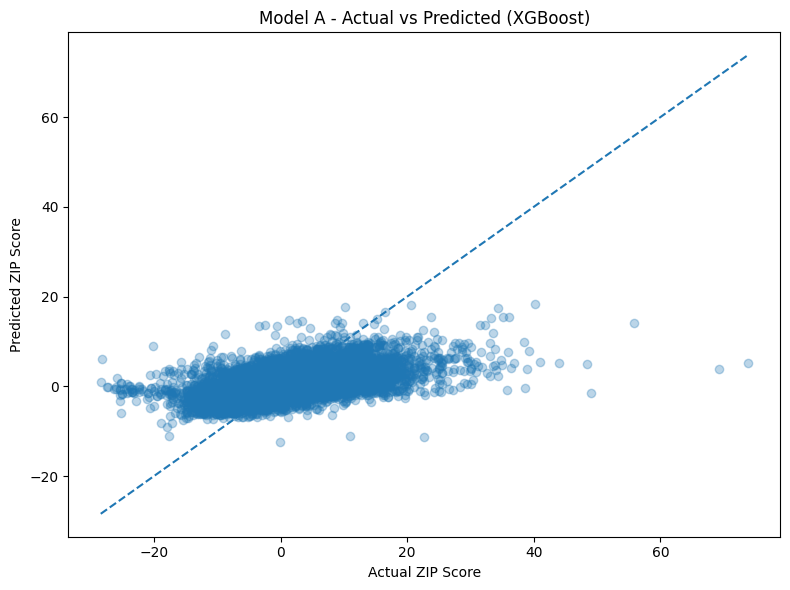

In [ ]:
# ============================================================
# CELL 68: ACTUAL VS PREDICTED
# ============================================================
import matplotlib.pyplot as plt
best_model_a = trained_models_a[best_model_a_name]

y_pred_best_a = best_model_a.predict(X_test_a)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_a,
    y_pred_best_a,
    alpha=0.3
)

min_value = min(
    y_test_a.min(),
    y_pred_best_a.min()
)

max_value = max(
    y_test_a.max(),
    y_pred_best_a.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual ZIP Score")
plt.ylabel("Predicted ZIP Score")

plt.title(
    f"Model A - Actual vs Predicted ({best_model_a_name})"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 69: BEST MODEL A METRICS
# ============================================================

best_model_a_metrics = {
    "Model": best_model_a_name,

    "Feature_Group":
        "50 Gene Expression + Morgan Fingerprints",

    "Number_of_features":
        X_a.shape[1],

    "Training_rows_used":
        len(X_train_fast),

    "Test_rows":
        len(X_test_a),

    "MAE":
        mean_absolute_error(
            y_test_a,
            y_pred_best_a
        ),

    "MSE":
        mean_squared_error(
            y_test_a,
            y_pred_best_a
        ),

    "RMSE":
        np.sqrt(
            mean_squared_error(
                y_test_a,
                y_pred_best_a
            )
        ),

    "R2":
        r2_score(
            y_test_a,
            y_pred_best_a
        )
}

best_model_a_metrics_df = pd.DataFrame(
    [best_model_a_metrics]
)

display(best_model_a_metrics_df)

,Model,Feature_Group,Number_of_features,Training_rows_used,Test_rows,MAE,MSE,RMSE,R2
0,XGBoost,50 Gene Expression + Morgan Fingerprints,4146,10000,19640,4.070488,31.911564,5.649032,0.245673


In [ ]:
# ============================================================
# CELL 70: SAVE BEST MODEL A
# ============================================================

import joblib

best_model_a_path = os.path.join(
    MODEL_DIR,
    "best_model_a.pkl"
)

joblib.dump(
    best_model_a,
    best_model_a_path
)

print("✓ Best Model A saved")
print(best_model_a_path)

✓ Best Model A saved
/content/drive/MyDrive/drug_synergy_project/models/best_model_a.pkl


In [ ]:
# ============================================================
# CELL 71: SAVE MODEL A FEATURE METADATA
# ============================================================

feature_metadata_a = {
    "target": TARGET,

    "gene_features": gene_feature_cols,

    "number_of_gene_features":
        len(gene_feature_cols),

    "morgan_radius":
        MORGAN_RADIUS,

    "morgan_bits":
        MORGAN_BITS,

    "morgan_features_per_drug":
        MORGAN_BITS,

    "total_morgan_features":
        MORGAN_BITS * 2,

    "total_features":
        X_a.shape[1],

    "drug1_morgan_position":
        "first_2048_bits",

    "drug2_morgan_position":
        "second_2048_bits"
}

feature_metadata_a_path = os.path.join(
    MODEL_DIR,
    "model_a_feature_metadata.pkl"
)

joblib.dump(
    feature_metadata_a,
    feature_metadata_a_path
)

print("✓ Model A feature metadata saved")
print(feature_metadata_a_path)

✓ Model A feature metadata saved
/content/drive/MyDrive/drug_synergy_project/models/model_a_feature_metadata.pkl


In [ ]:
# ============================================================
# CELL 72: SAVE MODEL A SUMMARY
# ============================================================

model_a_summary_path = os.path.join(
    PROCESSED_DIR,
    "model_a_summary.csv"
)

best_model_a_metrics_df.to_csv(
    model_a_summary_path,
    index=False
)

print("✓ Model A summary saved")
print(model_a_summary_path)

✓ Model A summary saved
/content/drive/MyDrive/drug_synergy_project/processed/model_a_summary.csv


In [ ]:
# ============================================================
# CELL 73: PREPARE MODEL B DATASET
# ============================================================

# Model B requires:
# 1. ZIP target
# 2. Morgan fingerprints for both drugs
# 3. 50 gene-expression features
# 4. DRS features

model_b_work = model_b_df.copy()

print("Model B rows:", len(model_b_work))
print("Target:", TARGET)

print("\nDRS feature availability:")
display(
    model_b_work[drs_feature_cols]
    .notna()
    .sum()
)

Model B rows: 5381
Target: ZIP

DRS feature availability:


,0
ic50_row,5381
ic50_col,5381
ri_row,5381
ri_col,5381
css_row,5381
css_col,5381


In [ ]:
# ============================================================
# CELL 74: MODEL B MORGAN FEATURES
# ============================================================

drug1_fp_b = np.vstack([
    morgan_dict[drug]
    for drug in model_b_work["Drug1_clean"]
]).astype(np.float32)

drug2_fp_b = np.vstack([
    morgan_dict[drug]
    for drug in model_b_work["Drug2_clean"]
]).astype(np.float32)

morgan_features_b = np.hstack([
    drug1_fp_b,
    drug2_fp_b
]).astype(np.float32)

print("✓ Morgan features created")

print("Drug 1 fingerprint shape:",
      drug1_fp_b.shape)

print("Drug 2 fingerprint shape:",
      drug2_fp_b.shape)

print("Combined Morgan shape:",
      morgan_features_b.shape)

✓ Morgan features created
Drug 1 fingerprint shape: (5381, 2048)
Drug 2 fingerprint shape: (5381, 2048)
Combined Morgan shape: (5381, 4096)


In [ ]:
# ============================================================
# CELL 75: MODEL B GENE FEATURES
# ============================================================

gene_features_b = (
    model_b_work[gene_feature_cols]
    .apply(pd.to_numeric, errors="coerce")
    .to_numpy(dtype=np.float32)
)

print("✓ Gene-expression features created")
print("Shape:", gene_features_b.shape)

print(
    "Missing values:",
    np.isnan(gene_features_b).sum()
)

✓ Gene-expression features created
Shape: (5381, 50)
Missing values: 0


In [ ]:
# ============================================================
# CELL 76: MODEL B DRS/GDSC FEATURES
# ============================================================

# Combine the 6 DRS features and
# 12 GDSC sensitivity features.

drs_all_feature_cols = (
    drs_feature_cols +
    gdsc_sensitivity_cols
)

drs_features_b = (
    model_b_work[drs_all_feature_cols]
    .apply(pd.to_numeric, errors="coerce")
    .to_numpy(dtype=np.float32)
)

print("✓ DRS/GDSC features prepared")

print("Number of DRS/GDSC features:",
      len(drs_all_feature_cols))

print("Feature matrix shape:",
      drs_features_b.shape)

print(
    "Total missing values:",
    np.isnan(drs_features_b).sum()
)

✓ DRS/GDSC features prepared
Number of DRS/GDSC features: 18
Feature matrix shape: (5381, 18)
Total missing values: 19218


In [ ]:
# ============================================================
# CELL 77: MODEL B TARGET
# ============================================================

y_b = (
    pd.to_numeric(
        model_b_work[TARGET],
        errors="coerce"
    )
    .to_numpy(dtype=np.float32)
)

print("✓ Target prepared")

print("Target shape:", y_b.shape)

print("Missing target values:",
      np.isnan(y_b).sum())

✓ Target prepared
Target shape: (5381,)
Missing target values: 0


In [ ]:
# ============================================================
# CELL 78: COMBINE MODEL B FEATURES
# ============================================================

X_b = np.hstack([
    gene_features_b,
    morgan_features_b,
    drs_features_b
]).astype(np.float32)

print("✓ Model B feature matrix created")

print("Final X_b shape:", X_b.shape)
print("Target shape:", y_b.shape)

print("\nExpected features:")
print("Gene features       :", len(gene_feature_cols))
print("Morgan features     :", MORGAN_BITS * 2)
print("DRS/GDSC features   :", len(drs_all_feature_cols))
print("Total expected      :",
      len(gene_feature_cols)
      + MORGAN_BITS * 2
      + len(drs_all_feature_cols))

✓ Model B feature matrix created
Final X_b shape: (5381, 4164)
Target shape: (5381,)

Expected features:
Gene features       : 50
Morgan features     : 4096
DRS/GDSC features   : 18
Total expected      : 4164


In [ ]:
# ============================================================
# CELL 79: MODEL B DATA QUALITY CHECK
# ============================================================

print("NaN values in X_b:",
      np.isnan(X_b).sum())

print("Infinite values in X_b:",
      np.isinf(X_b).sum())

print("NaN values in y_b:",
      np.isnan(y_b).sum())

print("Infinite values in y_b:",
      np.isinf(y_b).sum())

print("\n✓ Model B data quality check completed")

NaN values in X_b: 19218
Infinite values in X_b: 0
NaN values in y_b: 0
Infinite values in y_b: 0

✓ Model B data quality check completed


In [ ]:
# ============================================================
# CELL 80: MODEL B TRAIN/TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b,
    y_b,
    test_size=0.20,
    random_state=42
)

print("✓ Model B train/test split completed")

print("Training rows:", X_train_b.shape[0])
print("Testing rows :", X_test_b.shape[0])
print("Features     :", X_train_b.shape[1])

✓ Model B train/test split completed
Training rows: 4304
Testing rows : 1077
Features     : 4164


In [ ]:
# ============================================================
# CELL 81: IMPUTE MISSING MODEL B FEATURES
# ============================================================

from sklearn.impute import SimpleImputer

# Create imputer
imputer_b = SimpleImputer(
    strategy="median"
)

# Fit ONLY on training data
X_train_b = imputer_b.fit_transform(X_train_b)

# Apply same transformation to test data
X_test_b = imputer_b.transform(X_test_b)

# Convert to float32 to reduce RAM usage
X_train_b = X_train_b.astype(np.float32)
X_test_b = X_test_b.astype(np.float32)

print("✓ Missing values handled")

print("Training shape:", X_train_b.shape)
print("Testing shape :", X_test_b.shape)

print("Training NaN values:", np.isnan(X_train_b).sum())
print("Testing NaN values :", np.isnan(X_test_b).sum())

✓ Missing values handled
Training shape: (4304, 4164)
Testing shape : (1077, 4164)
Training NaN values: 0
Testing NaN values : 0


In [ ]:
# ============================================================
# CELL 82: DEFINE FAST MODEL B
# ============================================================

models_b = {

    "LASSO": Lasso(
        alpha=0.01,
        max_iter=1000
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=30,
        max_depth=8,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ),

    "AdaBoost": AdaBoostRegressor(
        n_estimators=30,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.7,
        objective="reg:squarederror",
        n_jobs=-1,
        random_state=42
    )
}

print("✓ Model B algorithms defined")

for name in models_b:
    print("-", name)

✓ Model B algorithms defined
- LASSO
- Random Forest
- AdaBoost
- XGBoost


In [ ]:
# ============================================================
# CELL 83: TRAIN MODEL B
# ============================================================

results_b = []
trained_models_b = {}

for name, model in models_b.items():

    print("\n" + "=" * 60)
    print("Training:", name)
    print("=" * 60)

    model.fit(
        X_train_b,
        y_train_b
    )

    y_pred = model.predict(
        X_test_b
    )

    mae = mean_absolute_error(
        y_test_b,
        y_pred
    )

    mse = mean_squared_error(
        y_test_b,
        y_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test_b,
        y_pred
    )

    results_b.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models_b[name] = model

    print("✓ Completed:", name)
    print("MAE :", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R²  :", round(r2, 4))


print("\n✓ All Model B models completed")


Training: LASSO


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.091e+03, tolerance: 1.933e+01
  model = cd_fast.enet_coordinate_descent(


✓ Completed: LASSO
MAE : 3.4749
RMSE: 4.7472
R²  : 0.4543

Training: Random Forest
✓ Completed: Random Forest
MAE : 2.9366
RMSE: 4.186
R²  : 0.5757

Training: AdaBoost
✓ Completed: AdaBoost
MAE : 4.1502
RMSE: 5.3931
R²  : 0.2956

Training: XGBoost
✓ Completed: XGBoost
MAE : 2.9881
RMSE: 4.2086
R²  : 0.5711

✓ All Model B models completed


In [ ]:
# ============================================================
# CELL 84: MODEL B RESULTS
# ============================================================

results_b_df = pd.DataFrame(
    results_b
)

results_b_df = results_b_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

print("MODEL B: GENE + MORGAN + DRS/GDSC")
print("=" * 70)

display(results_b_df)

MODEL B: GENE + MORGAN + DRS/GDSC


,Model,MAE,MSE,RMSE,R2
0,Random Forest,2.936624,17.522711,4.186014,0.575659
1,XGBoost,2.988143,17.712530,4.208626,0.571063
2,LASSO,3.474922,22.536085,4.747219,0.454253
3,AdaBoost,4.150227,29.085492,5.393097,0.295648


In [ ]:
# ============================================================
# CELL 85: SAVE MODEL B RESULTS
# ============================================================

model_b_results_path = os.path.join(
    PROCESSED_DIR,
    "model_b_gene_morgan_drs_results.csv"
)

results_b_df.to_csv(
    model_b_results_path,
    index=False
)

print("✓ Model B results saved")
print(model_b_results_path)

✓ Model B results saved
/content/drive/MyDrive/drug_synergy_project/processed/model_b_gene_morgan_drs_results.csv


In [ ]:
# ============================================================
# CELL 86: IDENTIFY BEST MODEL B
# ============================================================

best_model_b_name = results_b_df.iloc[0]["Model"]

best_model_b_r2 = results_b_df.iloc[0]["R2"]

best_model_b_rmse = results_b_df.iloc[0]["RMSE"]

print("BEST MODEL B")
print("=" * 50)

print("Model :", best_model_b_name)
print("R²    :", round(best_model_b_r2, 4))
print("RMSE  :", round(best_model_b_rmse, 4))

BEST MODEL B
Model : Random Forest
R²    : 0.5757
RMSE  : 4.186


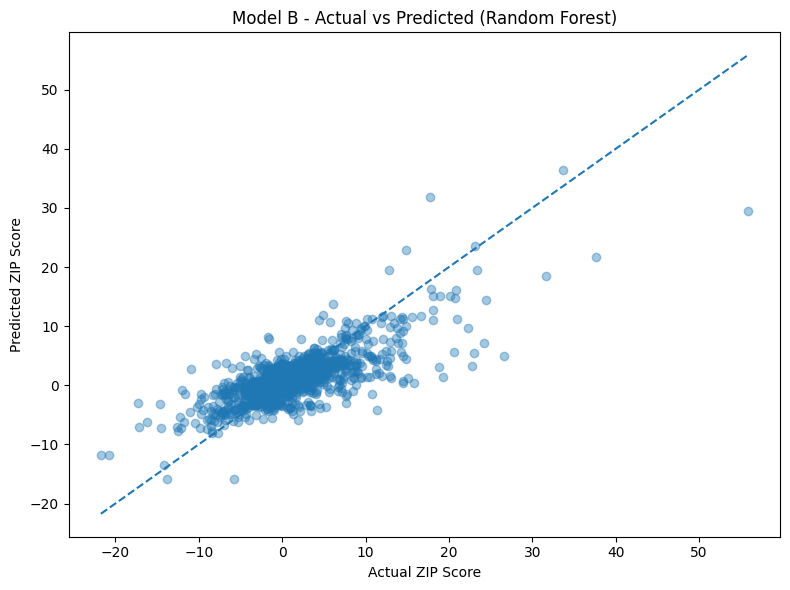

In [ ]:
# ============================================================
# CELL 87: BEST MODEL B ACTUAL VS PREDICTED
# ============================================================

best_model_b = trained_models_b[
    best_model_b_name
]

y_pred_best_b = best_model_b.predict(
    X_test_b
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_b,
    y_pred_best_b,
    alpha=0.4
)

min_value = min(
    y_test_b.min(),
    y_pred_best_b.min()
)

max_value = max(
    y_test_b.max(),
    y_pred_best_b.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual ZIP Score")
plt.ylabel("Predicted ZIP Score")

plt.title(
    f"Model B - Actual vs Predicted ({best_model_b_name})"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 88: SAVE BEST MODEL B
# ============================================================

best_model_b_path = os.path.join(
    MODEL_DIR,
    "best_model_b.pkl"
)

joblib.dump(
    best_model_b,
    best_model_b_path
)

print("✓ Best Model B saved")
print(best_model_b_path)

✓ Best Model B saved
/content/drive/MyDrive/drug_synergy_project/models/best_model_b.pkl


In [ ]:
# ============================================================
# CELL 89: SAVE MODEL B IMPUTER
# ============================================================

imputer_b_path = os.path.join(
    MODEL_DIR,
    "model_b_imputer.pkl"
)

joblib.dump(
    imputer_b,
    imputer_b_path
)

print("✓ Model B imputer saved")
print(imputer_b_path)

✓ Model B imputer saved
/content/drive/MyDrive/drug_synergy_project/models/model_b_imputer.pkl


In [ ]:
# ============================================================
# CELL 90: MODEL A VS MODEL B COMPARISON
# ============================================================

comparison_df = pd.concat(
    [
        results_a_df.assign(
            Feature_Group="Gene + Morgan"
        ),
        results_b_df.assign(
            Feature_Group="Gene + Morgan + DRS/GDSC"
        )
    ],
    ignore_index=True
)

comparison_df = comparison_df[
    [
        "Feature_Group",
        "Model",
        "MAE",
        "MSE",
        "RMSE",
        "R2"
    ]
]

comparison_df = comparison_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

print("MODEL A vs MODEL B")
print("=" * 80)

display(comparison_df)

MODEL A vs MODEL B


,Feature_Group,Model,MAE,MSE,RMSE,R2
0,Gene + Morgan + DRS/GDSC,Random Forest,2.936624,17.522711,4.186014,0.575659
1,Gene + Morgan + DRS/GDSC,XGBoost,2.988143,17.712530,4.208626,0.571063
2,Gene + Morgan + DRS/GDSC,LASSO,3.474922,22.536085,4.747219,0.454253
3,Gene + Morgan + DRS/GDSC,AdaBoost,4.150227,29.085492,5.393097,0.295648
4,Gene + Morgan,XGBoost,4.070488,31.911564,5.649032,0.245673
5,Gene + Morgan,Random Forest,4.121288,32.524610,5.703035,0.231182
6,Gene + Morgan,LASSO,4.114028,32.605576,5.710129,0.229268
7,Gene + Morgan,AdaBoost,4.585009,39.233456,6.263662,0.072598


In [ ]:
# ============================================================
# CELL 91: SAVE MODEL COMPARISON
# ============================================================

comparison_path = os.path.join(
    PROCESSED_DIR,
    "model_a_vs_model_b_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("✓ Comparison saved")
print(comparison_path)

✓ Comparison saved
/content/drive/MyDrive/drug_synergy_project/processed/model_a_vs_model_b_comparison.csv


In [ ]:
# ============================================================
# CELL 92: FIND OVERALL BEST MODEL
# ============================================================

best_overall = comparison_df.iloc[0]

print("OVERALL BEST MODEL")
print("=" * 60)

print("Feature Group:",
      best_overall["Feature_Group"])

print("Model:",
      best_overall["Model"])

print("MAE:",
      round(best_overall["MAE"], 4))

print("RMSE:",
      round(best_overall["RMSE"], 4))

print("R²:",
      round(best_overall["R2"], 4))

OVERALL BEST MODEL
Feature Group: Gene + Morgan + DRS/GDSC
Model: Random Forest
MAE: 2.9366
RMSE: 4.186
R²: 0.5757


In [ ]:
# ============================================================
# CELL 93: BEST A VS BEST B
# ============================================================

best_a_row = results_a_df.iloc[0]
best_b_row = results_b_df.iloc[0]

best_ab_df = pd.DataFrame({
    "Metric": [
        "Model",
        "RMSE",
        "MAE",
        "R2"
    ],

    "Model A": [
        best_a_row["Model"],
        best_a_row["RMSE"],
        best_a_row["MAE"],
        best_a_row["R2"]
    ],

    "Model B": [
        best_b_row["Model"],
        best_b_row["RMSE"],
        best_b_row["MAE"],
        best_b_row["R2"]
    ]
})

display(best_ab_df)

,Metric,Model A,Model B
0,Model,XGBoost,Random Forest
1,RMSE,5.649032,4.186014
2,MAE,4.070488,2.936624
3,R2,0.245673,0.575659


In [ ]:
# ============================================================
# CELL 94: DRS/GDSC IMPROVEMENT
# ============================================================

rmse_improvement = (
    best_a_row["RMSE"]
    - best_b_row["RMSE"]
)

r2_improvement = (
    best_b_row["R2"]
    - best_a_row["R2"]
)

print("EFFECT OF ADDING DRS/GDSC FEATURES")
print("=" * 60)

print(
    "Model A:",
    best_a_row["Model"]
)

print(
    "Model B:",
    best_b_row["Model"]
)

print(
    "\nRMSE change:",
    round(rmse_improvement, 4)
)

print(
    "R² improvement:",
    round(r2_improvement, 4)
)

if r2_improvement > 0:
    print(
        "\n✓ DRS/GDSC features improved R²"
    )
else:
    print(
        "\n⚠ DRS/GDSC features did not improve R²"
    )

EFFECT OF ADDING DRS/GDSC FEATURES
Model A: XGBoost
Model B: Random Forest

RMSE change: 1.463
R² improvement: 0.33

✓ DRS/GDSC features improved R²


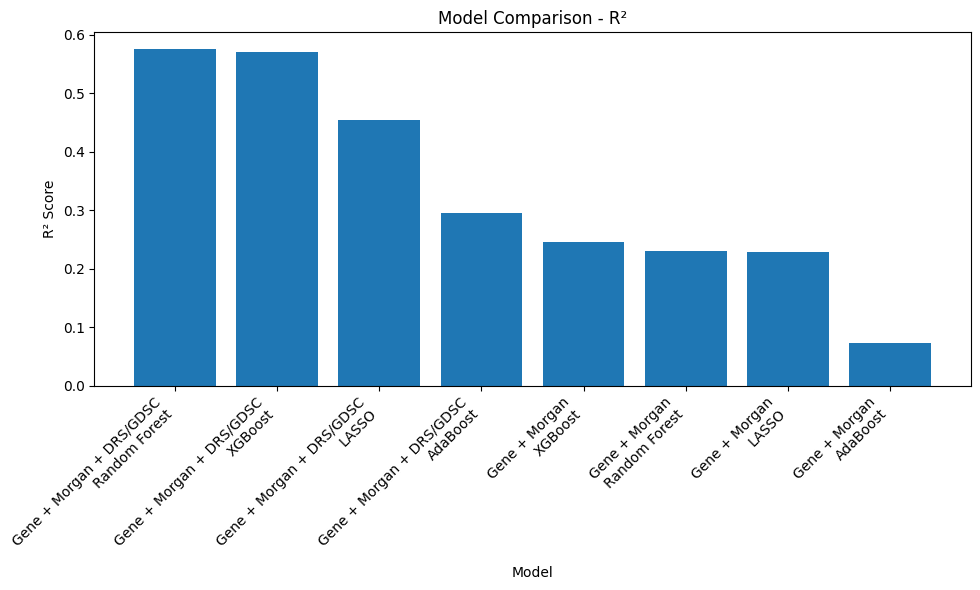

In [ ]:
# ============================================================
# CELL 95: MODEL COMPARISON GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

labels = (
    comparison_df["Feature_Group"]
    + "\n"
    + comparison_df["Model"]
)

plt.bar(
    labels,
    comparison_df["R2"]
)

plt.ylabel("R² Score")
plt.xlabel("Model")
plt.title("Model Comparison - R²")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

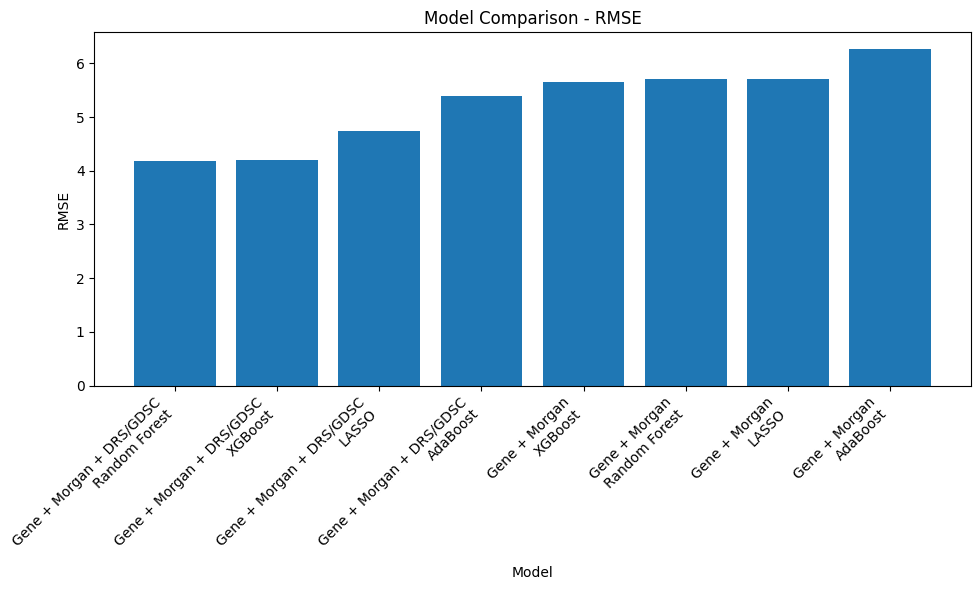

In [ ]:
# ============================================================
# CELL 96: RMSE COMPARISON GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

labels = (
    comparison_df["Feature_Group"]
    + "\n"
    + comparison_df["Model"]
)

plt.bar(
    labels,
    comparison_df["RMSE"]
)

plt.ylabel("RMSE")
plt.xlabel("Model")
plt.title("Model Comparison - RMSE")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 97: SAVE COMPLETE COMPARISON SUMMARY
# ============================================================

final_comparison_path = os.path.join(
    PROCESSED_DIR,
    "final_model_comparison.csv"
)

comparison_df.to_csv(
    final_comparison_path,
    index=False
)

print("✓ Final comparison saved")
print(final_comparison_path)

✓ Final comparison saved
/content/drive/MyDrive/drug_synergy_project/processed/final_model_comparison.csv


In [ ]:
# ============================================================
# CELL 98: PROJECT MODELING SUMMARY
# ============================================================

print("=" * 70)
print("DRUG SYNERGY PREDICTION - MODELING SUMMARY")
print("=" * 70)

print("\nTarget:")
print("ZIP synergy score")

print("\nModel A:")
print("50 Gene Expression + Morgan Fingerprints")

print("\nModel B:")
print("50 Gene Expression + Morgan Fingerprints + DRS/GDSC")

print("\nBest Model A:")
print(best_a_row["Model"])

print("Model A R²:",
      round(best_a_row["R2"], 4))

print("Model A RMSE:",
      round(best_a_row["RMSE"], 4))

print("\nBest Model B:")
print(best_b_row["Model"])

print("Model B R²:",
      round(best_b_row["R2"], 4))

print("Model B RMSE:",
      round(best_b_row["RMSE"], 4))

print("\nOverall Best:")
print(best_overall["Model"])

print("Feature Group:")
print(best_overall["Feature_Group"])

print("Overall R²:",
      round(best_overall["R2"], 4))

print("Overall RMSE:",
      round(best_overall["RMSE"], 4))

print("\n✓ Modeling comparison completed")

DRUG SYNERGY PREDICTION - MODELING SUMMARY

Target:
ZIP synergy score

Model A:
50 Gene Expression + Morgan Fingerprints

Model B:
50 Gene Expression + Morgan Fingerprints + DRS/GDSC

Best Model A:
XGBoost
Model A R²: 0.2457
Model A RMSE: 5.649

Best Model B:
Random Forest
Model B R²: 0.5757
Model B RMSE: 4.186

Overall Best:
Random Forest
Feature Group:
Gene + Morgan + DRS/GDSC
Overall R²: 0.5757
Overall RMSE: 4.186

✓ Modeling comparison completed


In [ ]:
# ============================================================
# CELL 99: PREDICTION CORRELATION
# ============================================================

from scipy.stats import pearsonr

# Best Model A correlation
corr_a, p_a = pearsonr(
    y_test_a,
    y_pred_best_a
)

# Best Model B correlation
corr_b, p_b = pearsonr(
    y_test_b,
    y_pred_best_b
)

print("PREDICTION CORRELATION")
print("=" * 60)

print("Best Model A:")
print("Model      :", best_model_a_name)
print("Pearson r  :", round(corr_a, 4))
print("p-value    :", p_a)

print("\nBest Model B:")
print("Model      :", best_model_b_name)
print("Pearson r  :", round(corr_b, 4))
print("p-value    :", p_b)

PREDICTION CORRELATION
Best Model A:
Model      : XGBoost
Pearson r  : 0.5103
p-value    : 0.0

Best Model B:
Model      : Random Forest
Pearson r  : 0.7634
p-value    : 2.87446239330221e-206


In [ ]:
# ============================================================
# CELL 100: ADD CORRELATION TO RESULTS
# ============================================================

results_a_df["Pearson_r"] = np.nan
results_b_df["Pearson_r"] = np.nan

results_a_df.loc[
    results_a_df["Model"] == best_model_a_name,
    "Pearson_r"
] = corr_a

results_b_df.loc[
    results_b_df["Model"] == best_model_b_name,
    "Pearson_r"
] = corr_b

print("✓ Pearson correlation added")

✓ Pearson correlation added


In [ ]:
# ============================================================
# CELL 101: RESIDUAL ANALYSIS
# ============================================================

residuals_b = (
    y_test_b - y_pred_best_b
)

print("RESIDUAL STATISTICS")
print("=" * 60)

print("Mean residual:",
      round(np.mean(residuals_b), 4))

print("Std residual:",
      round(np.std(residuals_b), 4))

print("Minimum residual:",
      round(np.min(residuals_b), 4))

print("Maximum residual:",
      round(np.max(residuals_b), 4))

RESIDUAL STATISTICS
Mean residual: 0.2174
Std residual: 4.1804
Minimum residual: -14.3195
Maximum residual: 26.3254


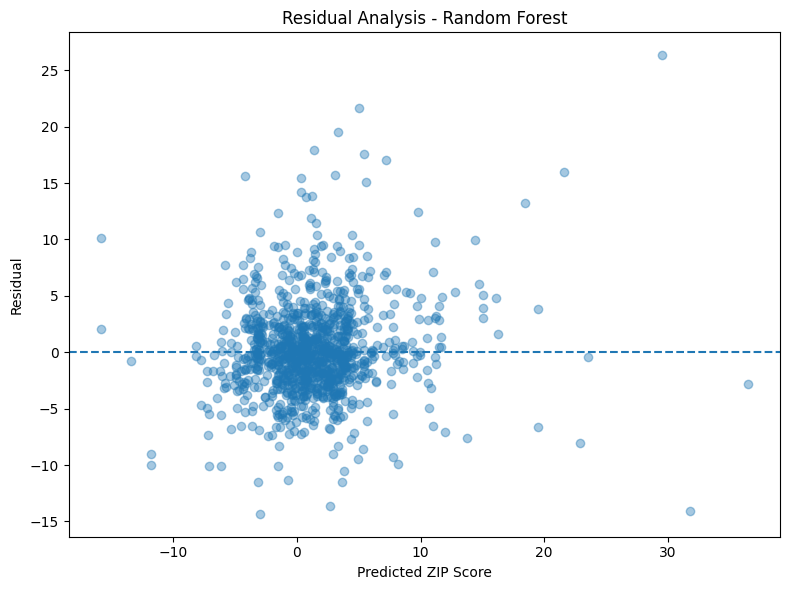

In [ ]:
# ============================================================
# CELL 102: RESIDUAL PLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_best_b,
    residuals_b,
    alpha=0.4
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted ZIP Score")
plt.ylabel("Residual")
plt.title(
    f"Residual Analysis - {best_model_b_name}"
)

plt.tight_layout()
plt.show()

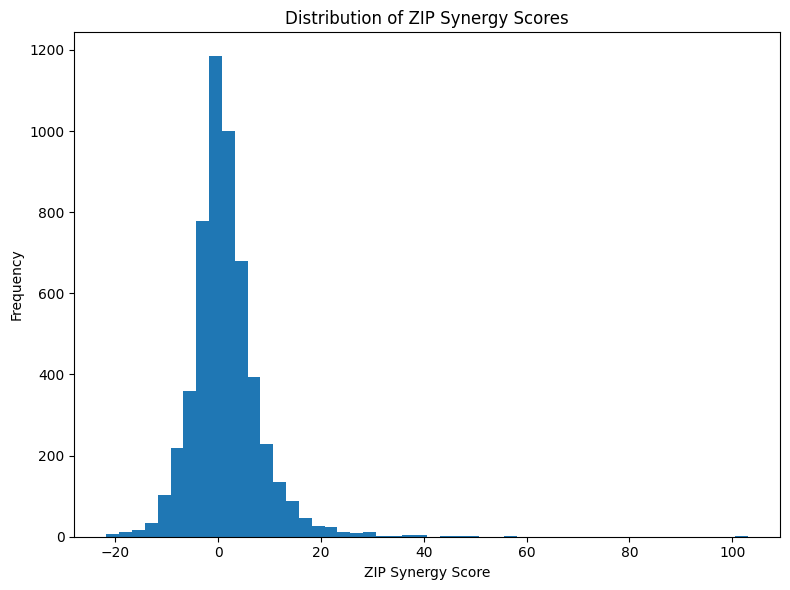

In [ ]:
# ============================================================
# CELL 103: ZIP SCORE DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 6))

plt.hist(
    y_b,
    bins=50
)

plt.xlabel("ZIP Synergy Score")
plt.ylabel("Frequency")
plt.title("Distribution of ZIP Synergy Scores")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 104: ZIP SYNERGY CATEGORIES
# ============================================================

def classify_zip(value):

    if value > 10:
        return "Strong Synergy"

    elif value > 0:
        return "Synergy"

    elif value >= -10:
        return "Near Neutral"

    else:
        return "Antagonism"


zip_categories = pd.Series(y_b).apply(
    classify_zip
)

print("ZIP SYNERGY CATEGORY DISTRIBUTION")
print("=" * 60)

display(
    zip_categories.value_counts()
    .to_frame("Count")
)

ZIP SYNERGY CATEGORY DISTRIBUTION


,Count
Synergy,2614
Near Neutral,2217
Strong Synergy,428
Antagonism,122


In [ ]:
# ============================================================
# CELL 105: FEATURE IMPORTANCE
# ============================================================

best_model_b = trained_models_b[
    best_model_b_name
]

if hasattr(best_model_b, "feature_importances_"):

    feature_importance = best_model_b.feature_importances_

    feature_names_b = (
        gene_feature_cols
        + [
            f"Drug1_Morgan_{i}"
            for i in range(MORGAN_BITS)
        ]
        + [
            f"Drug2_Morgan_{i}"
            for i in range(MORGAN_BITS)
        ]
        + drs_all_feature_cols
    )

    feature_importance_df = pd.DataFrame({
        "Feature": feature_names_b,
        "Importance": feature_importance
    })

    feature_importance_df = (
        feature_importance_df
        .sort_values(
            by="Importance",
            ascending=False
        )
        .reset_index(drop=True)
    )

    print("✓ Feature importance calculated")

    display(
        feature_importance_df.head(20)
    )

else:

    print(
        "Best Model B does not provide tree-based "
        "feature_importances_."
    )

✓ Feature importance calculated


,Feature,Importance
0,ri_row,0.153661
1,css_col,0.150551
2,C19orf33,0.148579
3,css_row,0.064971
4,KRT8,0.054466
5,ri_col,0.052769
6,ic50_col,0.045337
7,GDSC1_ROW_LN_IC50,0.014765
8,Drug1_Morgan_1691,0.013449
9,UCHL1,0.013168


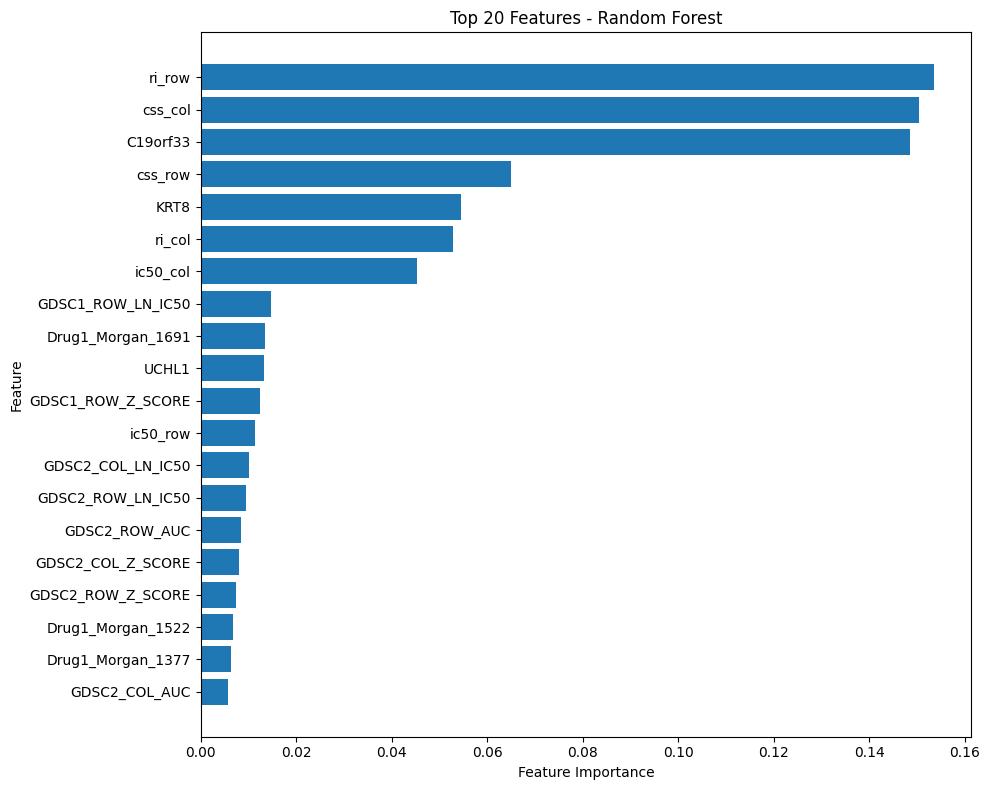

In [ ]:
# ============================================================
# CELL 106: TOP 20 FEATURE IMPORTANCE
# ============================================================

if "feature_importance_df" in globals():

    top_features = (
        feature_importance_df
        .head(20)
        .sort_values(
            by="Importance"
        )
    )

    plt.figure(figsize=(10, 8))

    plt.barh(
        top_features["Feature"],
        top_features["Importance"]
    )

    plt.xlabel("Feature Importance")
    plt.ylabel("Feature")
    plt.title(
        f"Top 20 Features - {best_model_b_name}"
    )

    plt.tight_layout()
    plt.show()

else:

    print(
        "Feature importance plot skipped."
    )

In [ ]:
# ============================================================
# CELL 107: FEATURE GROUP IMPORTANCE
# ============================================================

if "feature_importance_df" in globals():

    importance_values = (
        feature_importance_df
        .set_index("Feature")["Importance"]
    )

    gene_importance = importance_values[
        gene_feature_cols
    ].sum()

    morgan_drug1_features = [
        f"Drug1_Morgan_{i}"
        for i in range(MORGAN_BITS)
    ]

    morgan_drug2_features = [
        f"Drug2_Morgan_{i}"
        for i in range(MORGAN_BITS)
    ]

    morgan_importance = (
        importance_values[
            morgan_drug1_features
        ].sum()
        +
        importance_values[
            morgan_drug2_features
        ].sum()
    )

    drs_importance = importance_values[
        drs_all_feature_cols
    ].sum()

    feature_group_importance = pd.DataFrame({
        "Feature_Group": [
            "Gene Expression",
            "Morgan Fingerprints",
            "DRS/GDSC"
        ],
        "Total_Importance": [
            gene_importance,
            morgan_importance,
            drs_importance
        ]
    })

    feature_group_importance[
        "Percentage"
    ] = (
        feature_group_importance["Total_Importance"]
        /
        feature_group_importance["Total_Importance"].sum()
        * 100
    )

    display(
        feature_group_importance
    )

else:

    print(
        "Feature-group importance unavailable."
    )

,Feature_Group,Total_Importance,Percentage
0,Gene Expression,0.259289,25.928929
1,Morgan Fingerprints,0.173351,17.335136
2,DRS/GDSC,0.567359,56.735935


In [ ]:
# ============================================================
# CELL 108: SAVE FEATURE IMPORTANCE
# ============================================================

if "feature_importance_df" in globals():

    feature_importance_path = os.path.join(
        PROCESSED_DIR,
        "model_b_feature_importance.csv"
    )

    feature_importance_df.to_csv(
        feature_importance_path,
        index=False
    )

    print("✓ Feature importance saved")
    print(feature_importance_path)

else:

    print(
        "No feature importance to save."
    )

✓ Feature importance saved
/content/drive/MyDrive/drug_synergy_project/processed/model_b_feature_importance.csv


In [ ]:
# ============================================================
# CELL 109: FINAL ML RESULTS TABLE
# ============================================================

final_ml_results = comparison_df.copy()

print("FINAL ML MODEL COMPARISON")
print("=" * 80)

display(final_ml_results)

FINAL ML MODEL COMPARISON


,Feature_Group,Model,MAE,MSE,RMSE,R2
0,Gene + Morgan + DRS/GDSC,Random Forest,2.936624,17.522711,4.186014,0.575659
1,Gene + Morgan + DRS/GDSC,XGBoost,2.988143,17.712530,4.208626,0.571063
2,Gene + Morgan + DRS/GDSC,LASSO,3.474922,22.536085,4.747219,0.454253
3,Gene + Morgan + DRS/GDSC,AdaBoost,4.150227,29.085492,5.393097,0.295648
4,Gene + Morgan,XGBoost,4.070488,31.911564,5.649032,0.245673
5,Gene + Morgan,Random Forest,4.121288,32.524610,5.703035,0.231182
6,Gene + Morgan,LASSO,4.114028,32.605576,5.710129,0.229268
7,Gene + Morgan,AdaBoost,4.585009,39.233456,6.263662,0.072598


In [ ]:
# ============================================================
# CELL 110: SAVE FINAL ML RESULTS
# ============================================================

final_ml_results_path = os.path.join(
    PROCESSED_DIR,
    "FINAL_DRUG_SYNERGY_ML_RESULTS.csv"
)

final_ml_results.to_csv(
    final_ml_results_path,
    index=False
)

print("✓ Final ML results saved")
print(final_ml_results_path)

✓ Final ML results saved
/content/drive/MyDrive/drug_synergy_project/processed/FINAL_DRUG_SYNERGY_ML_RESULTS.csv


In [ ]:
# ============================================================
# CELL 111: CHECK PROJECT ARTIFACTS
# ============================================================

print("=" * 70)
print("PROJECT ARTIFACT CHECK")
print("=" * 70)

artifact_paths = {
    "Model A results":
        os.path.join(
            PROCESSED_DIR,
            "model_a_gene_morgan_results.csv"
        ),

    "Model B results":
        os.path.join(
            PROCESSED_DIR,
            "model_b_gene_morgan_drs_results.csv"
        ),

    "Model comparison":
        os.path.join(
            PROCESSED_DIR,
            "final_model_comparison.csv"
        ),

    "Best Model A":
        os.path.join(
            MODEL_DIR,
            "best_model_a.pkl"
        ),

    "Best Model B":
        os.path.join(
            MODEL_DIR,
            "best_model_b.pkl"
        ),

    "Model B imputer":
        os.path.join(
            MODEL_DIR,
            "model_b_imputer.pkl"
        ),

    "Model A metadata":
        os.path.join(
            MODEL_DIR,
            "model_a_feature_metadata.pkl"
        )
}

for name, path in artifact_paths.items():

    status = "✓ EXISTS" if os.path.exists(path) else "✗ MISSING"

    print(f"{status:12} | {name}")
    print("             ", path)

PROJECT ARTIFACT CHECK
✓ EXISTS     | Model A results
              /content/drive/MyDrive/drug_synergy_project/processed/model_a_gene_morgan_results.csv
✓ EXISTS     | Model B results
              /content/drive/MyDrive/drug_synergy_project/processed/model_b_gene_morgan_drs_results.csv
✓ EXISTS     | Model comparison
              /content/drive/MyDrive/drug_synergy_project/processed/final_model_comparison.csv
✓ EXISTS     | Best Model A
              /content/drive/MyDrive/drug_synergy_project/models/best_model_a.pkl
✓ EXISTS     | Best Model B
              /content/drive/MyDrive/drug_synergy_project/models/best_model_b.pkl
✓ EXISTS     | Model B imputer
              /content/drive/MyDrive/drug_synergy_project/models/model_b_imputer.pkl
✓ EXISTS     | Model A metadata
              /content/drive/MyDrive/drug_synergy_project/models/model_a_feature_metadata.pkl


In [ ]:
# ============================================================
# CELL 112: MODEL CONSISTENCY CHECK
# ============================================================

print("=" * 70)
print("MODEL CONSISTENCY CHECK")
print("=" * 70)

print("\nMODEL A")
print("Training rows:", len(X_train_a))
print("Testing rows :", len(X_test_a))
print("Features     :", X_train_a.shape[1])

print("\nMODEL B")
print("Training rows:", len(X_train_b))
print("Testing rows :", len(X_test_b))
print("Features     :", X_train_b.shape[1])

print("\nExpected Model A features:")
print(
    len(gene_feature_cols)
    + (MORGAN_BITS * 2)
)

print("\nExpected Model B features:")
print(
    len(gene_feature_cols)
    + (MORGAN_BITS * 2)
    + len(drs_all_feature_cols)
)

MODEL CONSISTENCY CHECK

MODEL A
Training rows: 78557
Testing rows : 19640
Features     : 4146

MODEL B
Training rows: 4304
Testing rows : 1077
Features     : 4164

Expected Model A features:
4146

Expected Model B features:
4164


In [ ]:
# ============================================================
# CELL 113: SAVE TOP 50 GENES
# ============================================================

top_genes_final_path = os.path.join(
    PROCESSED_DIR,
    "FINAL_TOP_50_GENES.csv"
)

pd.DataFrame({
    "Gene_Number": range(1, len(TOP_GENES) + 1),
    "Gene": TOP_GENES
}).to_csv(
    top_genes_final_path,
    index=False
)

print("✓ Final TOP 50 genes saved")
print(top_genes_final_path)

print("\nNumber of genes:",
      len(TOP_GENES))

✓ Final TOP 50 genes saved
/content/drive/MyDrive/drug_synergy_project/processed/FINAL_TOP_50_GENES.csv

Number of genes: 50


In [ ]:
# ============================================================
# CELL 114: SAVE MORGAN CONFIGURATION
# ============================================================

morgan_config = {
    "Fingerprint": "Morgan",
    "Radius": MORGAN_RADIUS,
    "Bits": MORGAN_BITS,
    "Drug1_features": MORGAN_BITS,
    "Drug2_features": MORGAN_BITS,
    "Total_features": MORGAN_BITS * 2
}

morgan_config_df = pd.DataFrame(
    [morgan_config]
)

morgan_config_path = os.path.join(
    PROCESSED_DIR,
    "FINAL_MORGAN_CONFIGURATION.csv"
)

morgan_config_df.to_csv(
    morgan_config_path,
    index=False
)

display(morgan_config_df)

print("✓ Morgan configuration saved")

,Fingerprint,Radius,Bits,Drug1_features,Drug2_features,Total_features
0,Morgan,2,2048,2048,2048,4096


✓ Morgan configuration saved


In [ ]:
# ============================================================
# CELL 115: COMPLETE EXPERIMENT CONFIGURATION
# ============================================================

experiment_config = {
    "Target": TARGET,

    "Top_genes": len(TOP_GENES),

    "Morgan_radius": MORGAN_RADIUS,

    "Morgan_bits": MORGAN_BITS,

    "Morgan_total_features":
        MORGAN_BITS * 2,

    "DRS_features":
        len(drs_feature_cols),

    "GDSC_sensitivity_features":
        len(gdsc_sensitivity_cols),

    "Model_A_total_features":
        len(gene_feature_cols)
        + MORGAN_BITS * 2,

    "Model_B_total_features":
        len(gene_feature_cols)
        + MORGAN_BITS * 2
        + len(drs_all_feature_cols),

    "Train_test_split":
        "80/20",

    "Random_state":
        42,

    "Model_A_training_rows":
        len(X_train_a),

    "Model_A_test_rows":
        len(X_test_a),

    "Model_B_training_rows":
        len(X_train_b),

    "Model_B_test_rows":
        len(X_test_b)
}

experiment_config_df = pd.DataFrame(
    [experiment_config]
)

experiment_config_path = os.path.join(
    PROCESSED_DIR,
    "FINAL_EXPERIMENT_CONFIGURATION.csv"
)

experiment_config_df.to_csv(
    experiment_config_path,
    index=False
)

display(experiment_config_df)

print("✓ Experiment configuration saved")

,Target,Top_genes,Morgan_radius,Morgan_bits,Morgan_total_features,DRS_features,GDSC_sensitivity_features,Model_A_total_features,Model_B_total_features,Train_test_split,Random_state,Model_A_training_rows,Model_A_test_rows,Model_B_training_rows,Model_B_test_rows
0,ZIP,50,2,2048,4096,6,12,4146,4164,80/20,42,78557,19640,4304,1077


✓ Experiment configuration saved


In [ ]:
# ============================================================
# CELL 116: FINAL PERFORMANCE SUMMARY
# ============================================================

print("=" * 80)
print("FINAL DRUG SYNERGY PREDICTION PERFORMANCE")
print("=" * 80)

print("\nMODEL A")
print("-" * 50)

print("Features: Gene Expression + Morgan")

print("Best algorithm:",
      best_model_a_name)

print("MAE:",
      round(best_a_row["MAE"], 4))

print("RMSE:",
      round(best_a_row["RMSE"], 4))

print("R²:",
      round(best_a_row["R2"], 4))

print("\nMODEL B")
print("-" * 50)

print("Features: Gene Expression + Morgan + DRS/GDSC")

print("Best algorithm:",
      best_model_b_name)

print("MAE:",
      round(best_b_row["MAE"], 4))

print("RMSE:",
      round(best_b_row["RMSE"], 4))

print("R²:",
      round(best_b_row["R2"], 4))

print("\nOVERALL")
print("-" * 50)

print("Best feature group:",
      best_overall["Feature_Group"])

print("Best algorithm:",
      best_overall["Model"])

print("Best R²:",
      round(best_overall["R2"], 4))

print("Best RMSE:",
      round(best_overall["RMSE"], 4))

FINAL DRUG SYNERGY PREDICTION PERFORMANCE

MODEL A
--------------------------------------------------
Features: Gene Expression + Morgan
Best algorithm: XGBoost
MAE: 4.0705
RMSE: 5.649
R²: 0.2457

MODEL B
--------------------------------------------------
Features: Gene Expression + Morgan + DRS/GDSC
Best algorithm: Random Forest
MAE: 2.9366
RMSE: 4.186
R²: 0.5757

OVERALL
--------------------------------------------------
Best feature group: Gene + Morgan + DRS/GDSC
Best algorithm: Random Forest
Best R²: 0.5757
Best RMSE: 4.186


In [ ]:
# ============================================================
# CELL 117: SAVE FINAL REPORT
# ============================================================

final_report = pd.DataFrame({
    "Item": [
        "Target",
        "Model A",
        "Model B",
        "Best Model A",
        "Best Model B",
        "Overall Best Model",
        "Overall Best Feature Group",
        "Best R2",
        "Best RMSE",
        "Best MAE"
    ],

    "Value": [
        TARGET,

        "50 Gene Expression + Morgan",

        "50 Gene Expression + Morgan + DRS/GDSC",

        best_model_a_name,

        best_model_b_name,

        best_overall["Model"],

        best_overall["Feature_Group"],

        best_overall["R2"],

        best_overall["RMSE"],

        best_overall["MAE"]
    ]
})

final_report_path = os.path.join(
    PROCESSED_DIR,
    "FINAL_DRUG_SYNERGY_REPORT.csv"
)

final_report.to_csv(
    final_report_path,
    index=False
)

display(final_report)

print("✓ Final report saved")
print(final_report_path)

,Item,Value
0,Target,ZIP
1,Model A,50 Gene Expression + Morgan
2,Model B,50 Gene Expression + Morgan + DRS/GDSC
3,Best Model A,XGBoost
4,Best Model B,Random Forest
5,Overall Best Model,Random Forest
6,Overall Best Feature Group,Gene + Morgan + DRS/GDSC
7,Best R2,0.575659
8,Best RMSE,4.186014
9,Best MAE,2.936624


✓ Final report saved
/content/drive/MyDrive/drug_synergy_project/processed/FINAL_DRUG_SYNERGY_REPORT.csv


In [ ]:
# ============================================================
# CELL 118: LIST PROCESSED OUTPUTS
# ============================================================

print("=" * 70)
print("PROCESSED PROJECT FILES")
print("=" * 70)

for file in sorted(os.listdir(PROCESSED_DIR)):

    full_path = os.path.join(
        PROCESSED_DIR,
        file
    )

    if os.path.isfile(full_path):

        size_mb = (
            os.path.getsize(full_path)
            / (1024 * 1024)
        )

        print(
            f"{file:<55} {size_mb:.2f} MB"
        )

PROCESSED PROJECT FILES
COMBINED_FIVE_MODEL_RESULTS.csv                         0.00 MB
DRS_FIVE_MODEL_RESULTS.csv                              0.00 MB
DS_FIVE_MODEL_RESULTS.csv                               0.00 MB
FINAL_DRUG_SYNERGY_ML_RESULTS.csv                       0.00 MB
FINAL_DRUG_SYNERGY_REPORT.csv                           0.00 MB
FINAL_EXPERIMENT_CONFIGURATION.csv                      0.00 MB
FINAL_FIVE_MODEL_COMPARISON.csv                         0.00 MB
FINAL_MORGAN_CONFIGURATION.csv                          0.00 MB
FINAL_TOP_50_GENES.csv                                  0.00 MB
GROUPED_FEATURE_GROUP_IMPORTANCE.csv                    0.00 MB
GROUPED_VALIDATION_RESULTS.csv                          0.00 MB
GROUPED_XGBOOST_FEATURE_IMPORTANCE.csv                  0.09 MB
RANDOM_VS_GROUPED_VALIDATION.csv                        0.00 MB
STRUCTURE_FIVE_MODEL_RESULTS.csv                        0.00 MB
final_model_comparison.csv                              0.00 MB
model_a_gene_mor

In [ ]:
# ============================================================
# CELL 119: LIST SAVED MODELS
# ============================================================

print("=" * 70)
print("SAVED MODEL FILES")
print("=" * 70)

for file in sorted(os.listdir(MODEL_DIR)):

    full_path = os.path.join(
        MODEL_DIR,
        file
    )

    if os.path.isfile(full_path):

        size_mb = (
            os.path.getsize(full_path)
            / (1024 * 1024)
        )

        print(
            f"{file:<45} {size_mb:.2f} MB"
        )

SAVED MODEL FILES
best_model_a.pkl                              0.16 MB
best_model_b.pkl                              0.53 MB
model_a_feature_metadata.pkl                  0.00 MB
model_b_imputer.pkl                           0.02 MB


In [ ]:
# ============================================================
# CELL 120: FINAL PROJECT COMPLETION CHECK
# ============================================================

print("=" * 80)
print("DRUG SYNERGY ML PROJECT - FINAL CHECK")
print("=" * 80)

checks = {
    "50 genes selected":
        len(TOP_GENES) == 50,

    "Morgan fingerprints":
        MORGAN_BITS == 2048,

    "Model A created":
        os.path.exists(
            os.path.join(
                MODEL_DIR,
                "best_model_a.pkl"
            )
        ),

    "Model B created":
        os.path.exists(
            os.path.join(
                MODEL_DIR,
                "best_model_b.pkl"
            )
        ),

    "Model B imputer saved":
        os.path.exists(
            os.path.join(
                MODEL_DIR,
                "model_b_imputer.pkl"
            )
        ),

    "Final comparison saved":
        os.path.exists(
            os.path.join(
                PROCESSED_DIR,
                "final_model_comparison.csv"
            )
        ),

    "Final report saved":
        os.path.exists(
            os.path.join(
                PROCESSED_DIR,
                "FINAL_DRUG_SYNERGY_REPORT.csv"
            )
        )
}

for item, status in checks.items():

    print(
        ("✓" if status else "✗"),
        item
    )

print("\n" + "=" * 80)

if all(checks.values()):
    print("✓ ML PROJECT PIPELINE COMPLETED SUCCESSFULLY")
else:
    print("⚠ Some project artifacts are missing")

print("=" * 80)

DRUG SYNERGY ML PROJECT - FINAL CHECK
✓ 50 genes selected
✓ Morgan fingerprints
✓ Model A created
✓ Model B created
✓ Model B imputer saved
✓ Final comparison saved
✓ Final report saved

✓ ML PROJECT PIPELINE COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# CELL 121: CREATE DRUG-COMBINATION GROUPS
# ============================================================

# Use the Model B dataset because it contains all feature groups
group_df = model_b_work.copy()

group_df["Group_Key"] = (
    group_df["Drug1_clean"].astype(str) + "__" +
    group_df["Drug2_clean"].astype(str) + "__" +
    group_df["Cell line"].astype(str)
)

print("Total Model B rows:", len(group_df))
print("Unique drug-drug-cell groups:", group_df["Group_Key"].nunique())

print("\nExample groups:")
display(
    group_df[
        ["Drug1_clean", "Drug2_clean", "Cell line", "Group_Key"]
    ].head()
)


Total Model B rows: 5381
Unique drug-drug-cell groups: 2494

Example groups:


,Drug1_clean,Drug2_clean,Cell line,Group_Key
216,BORTEZOMIB,DASATINIB,A2058,BORTEZOMIB__DASATINIB__A2058
217,BORTEZOMIB,DASATINIB,A2058,BORTEZOMIB__DASATINIB__A2058
218,BORTEZOMIB,DASATINIB,A2058,BORTEZOMIB__DASATINIB__A2058
219,BORTEZOMIB,DASATINIB,A2058,BORTEZOMIB__DASATINIB__A2058
220,BORTEZOMIB,DINACICLIB,A2058,BORTEZOMIB__DINACICLIB__A2058


In [ ]:
# ============================================================
# CELL 122: CHECK REPEATED COMBINATIONS
# ============================================================

group_counts = group_df["Group_Key"].value_counts()

print("Groups appearing once :", (group_counts == 1).sum())
print("Groups appearing >1   :", (group_counts > 1).sum())
print("Maximum rows per group:", group_counts.max())

print("\nTop repeated groups:")
display(group_counts.head(10))

Groups appearing once : 1551
Groups appearing >1   : 943
Maximum rows per group: 8

Top repeated groups:


,count
Group_Key,
TEMOZOLOMIDE__MK-8776__A427,8
LAPATINIB__MK-2206__A2058,8
MK-2206__ERLOTINIB__LOVO,8
LAPATINIB__MK-2206__LOVO,8
MK-2206__ERLOTINIB__A375,8
DASATINIB__MK-8776__A2058,8
TEMOZOLOMIDE__MK-8776__A375,8
MK-2206__ERLOTINIB__A427,8
TEMOZOLOMIDE__MK-8776__LOVO,8


In [ ]:
# ============================================================
# CELL 123: PREPARE DATA FOR GROUPED VALIDATION
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

X_grouped = X_b.copy()
y_grouped = y_b.copy()
groups = group_df["Group_Key"].to_numpy()

print("X shape:", X_grouped.shape)
print("y shape:", y_grouped.shape)
print("Groups:", len(np.unique(groups)))

X shape: (5381, 4164)
y shape: (5381,)
Groups: 2494


In [ ]:
# ============================================================
# CELL 124: GROUPED TRAIN/TEST SPLIT
# ============================================================

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx_g, test_idx_g = next(
    gss.split(X_grouped, y_grouped, groups=groups)
)

X_train_g = X_grouped[train_idx_g]
X_test_g = X_grouped[test_idx_g]

y_train_g = y_grouped[train_idx_g]
y_test_g = y_grouped[test_idx_g]

groups_train = groups[train_idx_g]
groups_test = groups[test_idx_g]

print("Grouped training rows:", len(X_train_g))
print("Grouped testing rows :", len(X_test_g))

print("Training groups:", len(np.unique(groups_train)))
print("Testing groups :", len(np.unique(groups_test)))

# Verify no group leakage
overlap_groups = set(groups_train).intersection(set(groups_test))

print("\nGroup overlap between train and test:", len(overlap_groups))

if len(overlap_groups) == 0:
    print("✓ No drug-drug-cell groups are shared between train and test.")
else:
    print("⚠ Group leakage detected.")

Grouped training rows: 4324
Grouped testing rows : 1057
Training groups: 1995
Testing groups : 499

Group overlap between train and test: 0
✓ No drug-drug-cell groups are shared between train and test.


In [ ]:
# ============================================================
# CELL 125: APPLY MEDIAN IMPUTATION TO GROUPED DATA
# ============================================================

imputer_grouped = SimpleImputer(strategy="median")

X_train_g = imputer_grouped.fit_transform(
    X_train_g
).astype(np.float32)

X_test_g = imputer_grouped.transform(
    X_test_g
).astype(np.float32)

print("Grouped training shape:", X_train_g.shape)
print("Grouped testing shape :", X_test_g.shape)
print("✓ Imputation completed.")

Grouped training shape: (4324, 4164)
Grouped testing shape : (1057, 4164)
✓ Imputation completed.


In [ ]:
# ============================================================
# CELL 126: GROUPED VALIDATION - XGBOOST
# ============================================================

grouped_xgb = XGBRegressor(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.7,
    objective="reg:squarederror",
    n_jobs=-1,
    random_state=42
)

print("Training grouped XGBoost...")

grouped_xgb.fit(
    X_train_g,
    y_train_g
)

y_pred_grouped = grouped_xgb.predict(
    X_test_g
)

print("✓ Grouped XGBoost training completed.")

Training grouped XGBoost...
✓ Grouped XGBoost training completed.


In [ ]:
# ============================================================
# CELL 127: GROUPED VALIDATION METRICS
# ============================================================

grouped_mae = mean_absolute_error(
    y_test_g,
    y_pred_grouped
)

grouped_mse = mean_squared_error(
    y_test_g,
    y_pred_grouped
)

grouped_rmse = np.sqrt(grouped_mse)

grouped_r2 = r2_score(
    y_test_g,
    y_pred_grouped
)

grouped_corr, grouped_p = pearsonr(
    y_test_g,
    y_pred_grouped
)

grouped_results = pd.DataFrame([{
    "Validation": "Grouped Train/Test",
    "Model": "XGBoost",
    "MAE": grouped_mae,
    "MSE": grouped_mse,
    "RMSE": grouped_rmse,
    "R2": grouped_r2,
    "Pearson_r": grouped_corr
}])

display(grouped_results)

print("\nGrouped Validation Results")
print("--------------------------")
print("MAE       :", round(grouped_mae, 4))
print("RMSE      :", round(grouped_rmse, 4))
print("R2        :", round(grouped_r2, 4))
print("Pearson r :", round(grouped_corr, 4))

,Validation,Model,MAE,MSE,RMSE,R2,Pearson_r
0,Grouped Train/Test,XGBoost,3.263323,25.481445,5.047915,0.535158,0.766213



Grouped Validation Results
--------------------------
MAE       : 3.2633
RMSE      : 5.0479
R2        : 0.5352
Pearson r : 0.7662


In [ ]:
# ============================================================
# CELL 128: RANDOM VS GROUPED VALIDATION
# ============================================================

random_validation = pd.DataFrame([{
    "Validation": "Random Split",
    "RMSE": best_model_b_rmse,
    "R2": best_model_b_r2
}])

grouped_validation = pd.DataFrame([{
    "Validation": "Grouped Split",
    "RMSE": grouped_rmse,
    "R2": grouped_r2
}])

validation_comparison = pd.concat(
    [random_validation, grouped_validation],
    ignore_index=True
)

display(validation_comparison)

,Validation,RMSE,R2
0,Random Split,4.186014,0.575659
1,Grouped Split,5.047915,0.535158


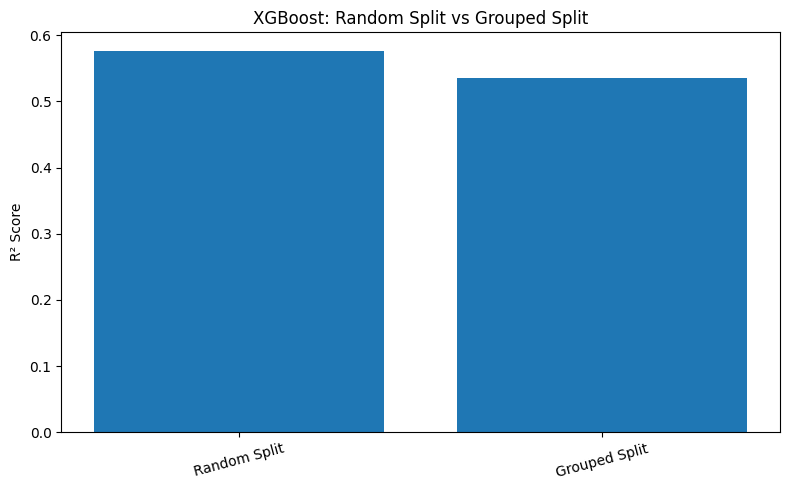

In [ ]:
# ============================================================
# CELL 129: RANDOM VS GROUPED R2
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    validation_comparison["Validation"],
    validation_comparison["R2"]
)

plt.ylabel("R² Score")
plt.title("XGBoost: Random Split vs Grouped Split")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

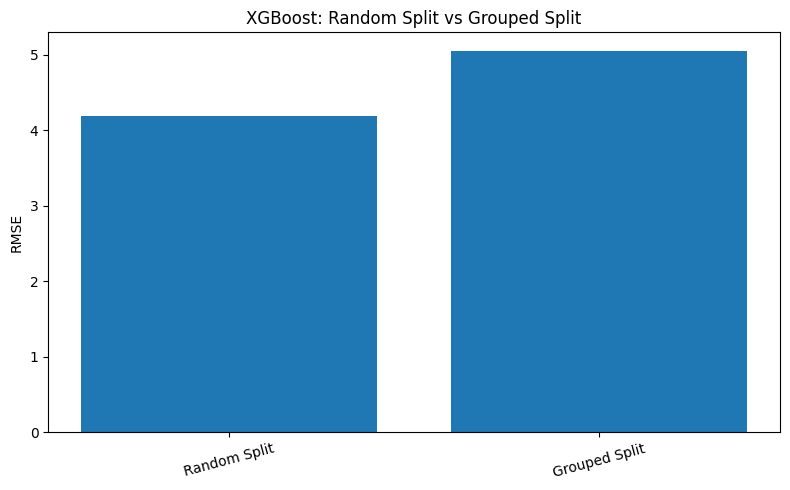

In [ ]:
# ============================================================
# CELL 130: RANDOM VS GROUPED RMSE
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    validation_comparison["Validation"],
    validation_comparison["RMSE"]
)

plt.ylabel("RMSE")
plt.title("XGBoost: Random Split vs Grouped Split")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 131: SAVE GROUPED VALIDATION RESULTS
# ============================================================

grouped_validation_path = os.path.join(
    PROCESSED_DIR,
    "GROUPED_VALIDATION_RESULTS.csv"
)

grouped_results.to_csv(
    grouped_validation_path,
    index=False
)

validation_comparison_path = os.path.join(
    PROCESSED_DIR,
    "RANDOM_VS_GROUPED_VALIDATION.csv"
)

validation_comparison.to_csv(
    validation_comparison_path,
    index=False
)

print("✓ Saved:")
print(grouped_validation_path)
print(validation_comparison_path)

✓ Saved:
/content/drive/MyDrive/drug_synergy_project/processed/GROUPED_VALIDATION_RESULTS.csv
/content/drive/MyDrive/drug_synergy_project/processed/RANDOM_VS_GROUPED_VALIDATION.csv


In [ ]:
# ============================================================
# CELL 132: FINAL VALIDATION SUMMARY
# ============================================================

print("=" * 70)
print("FINAL VALIDATION SUMMARY")
print("=" * 70)

print("\nRandom Split:")
print("  R²   :", round(best_model_b_r2, 4))
print("  RMSE :", round(best_model_b_rmse, 4))

print("\nGrouped Split:")
print("  R²   :", round(grouped_r2, 4))
print("  RMSE :", round(grouped_rmse, 4))

print("\nGroup Leakage Check:")
print("  Shared groups:", len(overlap_groups))

if len(overlap_groups) == 0:
    print("  ✓ No group leakage")
else:
    print("  ⚠ Group leakage detected")

print("\nFeature Configuration:")
print("  Gene features       : 50")
print("  Morgan fingerprint  : 4096")
print("  DRS/GDSC features   :", len(drs_all_feature_cols))
print("  Total Model B       :", X_b.shape[1])

print("\nTarget:")
print("  ZIP synergy score")

print("\n" + "=" * 70)

FINAL VALIDATION SUMMARY

Random Split:
  R²   : 0.5757
  RMSE : 4.186

Grouped Split:
  R²   : 0.5352
  RMSE : 5.0479

Group Leakage Check:
  Shared groups: 0
  ✓ No group leakage

Feature Configuration:
  Gene features       : 50
  Morgan fingerprint  : 4096
  DRS/GDSC features   : 18
  Total Model B       : 4164

Target:
  ZIP synergy score



In [ ]:
# ============================================================
# CELL 133: GROUPED XGBOOST FEATURE IMPORTANCE
# ============================================================

feature_names_b = (
    gene_feature_cols
    + [f"Drug1_Morgan_{i}" for i in range(MORGAN_BITS)]
    + [f"Drug2_Morgan_{i}" for i in range(MORGAN_BITS)]
    + drs_all_feature_cols
)

importance_values = grouped_xgb.feature_importances_

grouped_importance_df = pd.DataFrame({
    "Feature": feature_names_b,
    "Importance": importance_values
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 20 important features:")
display(grouped_importance_df.head(20))

Top 20 important features:


,Feature,Importance
0,C19orf33,0.074304
1,SPINT2,0.045230
2,Drug1_Morgan_249,0.038882
3,KRT8,0.035278
4,Drug2_Morgan_875,0.025410
5,AGR2,0.015035
6,Drug2_Morgan_666,0.012795
7,Drug1_Morgan_875,0.011801
8,Drug2_Morgan_1750,0.011027
9,Drug1_Morgan_415,0.010944


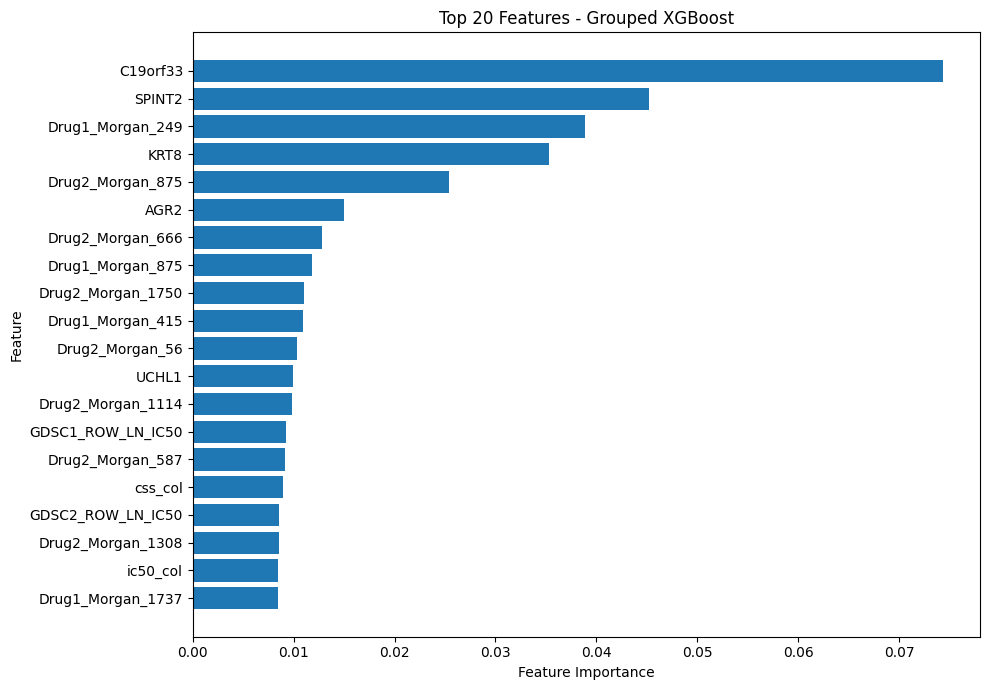

In [ ]:
# ============================================================
# CELL 134: TOP 20 FEATURE IMPORTANCE
# ============================================================

top20_grouped = grouped_importance_df.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top20_grouped["Feature"],
    top20_grouped["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features - Grouped XGBoost")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 135: FEATURE GROUP IMPORTANCE
# ============================================================

gene_count = len(gene_feature_cols)
morgan_count = MORGAN_BITS * 2
drs_count = len(drs_all_feature_cols)

group_importance = pd.DataFrame({
    "Feature Group": [
        "Gene Expression",
        "Morgan Fingerprints",
        "DRS/GDSC"
    ],
    "Number of Features": [
        gene_count,
        morgan_count,
        drs_count
    ],
    "Total Importance": [
        importance_values[:gene_count].sum(),
        importance_values[
            gene_count:gene_count + morgan_count
        ].sum(),
        importance_values[
            gene_count + morgan_count:
        ].sum()
    ]
})

group_importance["Average Importance"] = (
    group_importance["Total Importance"] /
    group_importance["Number of Features"]
)

display(group_importance)

,Feature Group,Number of Features,Total Importance,Average Importance
0,Gene Expression,50,0.304318,0.006086
1,Morgan Fingerprints,4096,0.608743,0.000149
2,DRS/GDSC,18,0.086939,0.004830


In [ ]:
# ============================================================
# CELL 136: SAVE GROUPED FEATURE IMPORTANCE
# ============================================================

grouped_importance_path = os.path.join(
    PROCESSED_DIR,
    "GROUPED_XGBOOST_FEATURE_IMPORTANCE.csv"
)

grouped_importance_df.to_csv(
    grouped_importance_path,
    index=False
)

group_importance_path = os.path.join(
    PROCESSED_DIR,
    "GROUPED_FEATURE_GROUP_IMPORTANCE.csv"
)

group_importance.to_csv(
    group_importance_path,
    index=False
)

print("✓ Feature importance files saved.")

✓ Feature importance files saved.


In [ ]:
# ============================================================
# CELL 137: TEST A REAL DATASET COMBINATION
# ============================================================

test_row = model_b_work.iloc[0]

print("Drug 1 :", test_row["Drug1_clean"])
print("Drug 2 :", test_row["Drug2_clean"])
print("Cell   :", test_row["Cell line"])
print("Actual ZIP:", test_row[TARGET])

Drug 1 : BORTEZOMIB
Drug 2 : DASATINIB
Cell   : A2058
Actual ZIP: 3.28


In [ ]:
# ============================================================
# CELL 138: BUILD TEST FEATURE VECTOR
# ============================================================

drug1 = test_row["Drug1_clean"]
drug2 = test_row["Drug2_clean"]

fp1 = morgan_dict[drug1].astype(np.float32)
fp2 = morgan_dict[drug2].astype(np.float32)

gene_values = (
    test_row[gene_feature_cols]
    .apply(pd.to_numeric, errors="coerce")
    .to_numpy(dtype=np.float32)
)

drs_values = (
    test_row[drs_all_feature_cols]
    .apply(pd.to_numeric, errors="coerce")
    .to_numpy(dtype=np.float32)
)

test_features = np.hstack([
    gene_values,
    fp1,
    fp2,
    drs_values
]).reshape(1, -1)

print("Feature vector shape:", test_features.shape)
print("Expected:", (1, X_b.shape[1]))

Feature vector shape: (1, 4164)
Expected: (1, 4164)


In [ ]:
# ============================================================
# CELL 139: PREDICT ZIP SCORE
# ============================================================

test_features_imputed = imputer_grouped.transform(
    test_features
).astype(np.float32)

predicted_zip = grouped_xgb.predict(
    test_features_imputed
)[0]

actual_zip = float(test_row[TARGET])

print("=" * 50)
print("DRUG SYNERGY PREDICTION")
print("=" * 50)

print("Drug 1       :", drug1)
print("Drug 2       :", drug2)
print("Cell line    :", test_row["Cell line"])
print("Actual ZIP   :", round(actual_zip, 4))
print("Predicted ZIP:", round(predicted_zip, 4))
print("Error        :", round(abs(actual_zip - predicted_zip), 4))

DRUG SYNERGY PREDICTION
Drug 1       : BORTEZOMIB
Drug 2       : DASATINIB
Cell line    : A2058
Actual ZIP   : 3.28
Predicted ZIP: 5.5722
Error        : 2.2922


In [ ]:
# ============================================================
# CELL 140: INTERPRET PREDICTED ZIP SCORE
# ============================================================

def interpret_zip(zip_score):
    if zip_score > 10:
        return "Strong Synergy"
    elif zip_score > 0:
        return "Synergy"
    elif zip_score >= -10:
        return "Near Neutral"
    else:
        return "Antagonism"

print("Predicted ZIP:", round(predicted_zip, 4))
print("Interpretation:", interpret_zip(predicted_zip))

Predicted ZIP: 5.5722
Interpretation: Synergy


In [ ]:
# ============================================================
# CELL 141: IMPORT PYTORCH FOR SYNERGYX
# ============================================================

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

print("PyTorch version:", torch.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

PyTorch version: 2.11.0+cpu
Device: cpu
Using CPU


In [ ]:
# ============================================================
# CELL 142: SEPARATE MULTI-MODAL FEATURES
# ============================================================

GENE_START = 0
GENE_END = len(gene_feature_cols)

MORGAN_START = GENE_END
MORGAN_END = GENE_END + MORGAN_BITS * 2

DRS_START = MORGAN_END
DRS_END = X_b.shape[1]

print("Gene features :", GENE_END - GENE_START)
print("Morgan features:", MORGAN_END - MORGAN_START)
print("DRS/GDSC features:", DRS_END - DRS_START)

print("Total features:", DRS_END)

Gene features : 50
Morgan features: 4096
DRS/GDSC features: 18
Total features: 4164


In [ ]:
# ============================================================
# CELL 143: EXTRACT TRAIN/TEST MODALITIES
# ============================================================

X_train_gene = X_train_b[:, GENE_START:GENE_END]
X_test_gene  = X_test_b[:, GENE_START:GENE_END]

X_train_morgan = X_train_b[:, MORGAN_START:MORGAN_END]
X_test_morgan  = X_test_b[:, MORGAN_START:MORGAN_END]

X_train_drs = X_train_b[:, DRS_START:DRS_END]
X_test_drs  = X_test_b[:, DRS_START:DRS_END]

print("Gene train :", X_train_gene.shape)
print("Morgan train:", X_train_morgan.shape)
print("DRS train  :", X_train_drs.shape)

print("\nGene test :", X_test_gene.shape)
print("Morgan test:", X_test_morgan.shape)
print("DRS test  :", X_test_drs.shape)

Gene train : (4304, 50)
Morgan train: (4304, 4096)
DRS train  : (4304, 18)

Gene test : (1077, 50)
Morgan test: (1077, 4096)
DRS test  : (1077, 18)


In [ ]:
# ============================================================
# CELL 144: SCALE GENE + DRS FEATURES
# ============================================================

from sklearn.preprocessing import StandardScaler

gene_scaler = StandardScaler()
drs_scaler = StandardScaler()

X_train_gene_scaled = gene_scaler.fit_transform(
    X_train_gene
).astype(np.float32)

X_test_gene_scaled = gene_scaler.transform(
    X_test_gene
).astype(np.float32)

X_train_drs_scaled = drs_scaler.fit_transform(
    X_train_drs
).astype(np.float32)

X_test_drs_scaled = drs_scaler.transform(
    X_test_drs
).astype(np.float32)

# Morgan fingerprints are already binary 0/1,
# so we keep them unchanged.

X_train_morgan = X_train_morgan.astype(np.float32)
X_test_morgan = X_test_morgan.astype(np.float32)

print("✓ Gene scaling completed")
print("✓ DRS scaling completed")
print("✓ Morgan fingerprints kept as binary features")

✓ Gene scaling completed
✓ DRS scaling completed
✓ Morgan fingerprints kept as binary features


In [ ]:
# ============================================================
# CELL 145: CREATE PYTORCH DATASETS
# ============================================================

train_gene_tensor = torch.tensor(X_train_gene_scaled)
train_morgan_tensor = torch.tensor(X_train_morgan)
train_drs_tensor = torch.tensor(X_train_drs_scaled)
train_y_tensor = torch.tensor(y_train_b.reshape(-1, 1))

test_gene_tensor = torch.tensor(X_test_gene_scaled)
test_morgan_tensor = torch.tensor(X_test_morgan)
test_drs_tensor = torch.tensor(X_test_drs_scaled)
test_y_tensor = torch.tensor(y_test_b.reshape(-1, 1))

train_dataset = TensorDataset(
    train_gene_tensor,
    train_morgan_tensor,
    train_drs_tensor,
    train_y_tensor
)

test_dataset = TensorDataset(
    test_gene_tensor,
    test_morgan_tensor,
    test_drs_tensor,
    test_y_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Testing samples :", len(test_dataset))

Training samples: 4304
Testing samples : 1077


In [ ]:
# ============================================================
# CELL 146: DEFINE SYNERGYX-STYLE MODEL
# ============================================================

class SynergyXAdapted(nn.Module):

    def __init__(
        self,
        gene_dim=50,
        morgan_dim=4096,
        drs_dim=18,
        hidden_dim=64,
        num_heads=4
    ):
        super().__init__()

        # -------------------------------
        # Gene-expression encoder
        # -------------------------------
        self.gene_encoder = nn.Sequential(
            nn.Linear(gene_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, hidden_dim)
        )

        # -------------------------------
        # Morgan fingerprint encoder
        # -------------------------------
        self.morgan_encoder = nn.Sequential(
            nn.Linear(morgan_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, hidden_dim)
        )

        # -------------------------------
        # DRS/GDSC encoder
        # -------------------------------
        self.drs_encoder = nn.Sequential(
            nn.Linear(drs_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, hidden_dim)
        )

        # -------------------------------
        # Multi-modal attention
        # -------------------------------
        self.attention = nn.MultiheadAttention(
            embed_dim=hidden_dim,
            num_heads=num_heads,
            batch_first=True
        )

        # -------------------------------
        # Fusion + regression
        # -------------------------------
        self.fusion = nn.Sequential(
            nn.Linear(hidden_dim * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, gene, morgan, drs):

        gene_embedding = self.gene_encoder(gene)
        morgan_embedding = self.morgan_encoder(morgan)
        drs_embedding = self.drs_encoder(drs)

        # Three modalities become three tokens
        modalities = torch.stack(
            [
                gene_embedding,
                morgan_embedding,
                drs_embedding
            ],
            dim=1
        )

        # Cross-modal attention
        attended, attention_weights = self.attention(
            modalities,
            modalities,
            modalities
        )

        # Flatten the three attended modalities
        fused = attended.reshape(
            attended.size(0),
            -1
        )

        output = self.fusion(fused)

        return output, attention_weights

In [ ]:
# ============================================================
# CELL 147: CREATE SYNERGYX MODEL
# ============================================================

synergyx_model = SynergyXAdapted(
    gene_dim=50,
    morgan_dim=4096,
    drs_dim=18,
    hidden_dim=64,
    num_heads=4
).to(device)

print(synergyx_model)

SynergyXAdapted(
  (gene_encoder): Sequential(
    (0): Linear(in_features=50, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=64, bias=True)
  )
  (morgan_encoder): Sequential(
    (0): Linear(in_features=4096, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
  )
  (drs_encoder): Sequential(
    (0): Linear(in_features=18, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=64, bias=True)
  )
  (attention): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
  )
  (fusion): Sequential(
    (0): Linear(in_features=192, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
  

In [ ]:
# ============================================================
# CELL 148: SYNERGYX TRAINING CONFIGURATION
# ============================================================

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    synergyx_model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

EPOCHS = 50

print("Loss function : MSELoss")
print("Optimizer     : Adam")
print("Learning rate :", 0.001)
print("Epochs        :", EPOCHS)

Loss function : MSELoss
Optimizer     : Adam
Learning rate : 0.001
Epochs        : 50


In [ ]:
# ============================================================
# CELL 149: TRAIN SYNERGYX
# ============================================================

train_losses = []

print("Training SynergyX...")
print("-" * 50)

for epoch in range(EPOCHS):

    synergyx_model.train()

    running_loss = 0.0

    for gene_batch, morgan_batch, drs_batch, y_batch in train_loader:

        gene_batch = gene_batch.to(device)
        morgan_batch = morgan_batch.to(device)
        drs_batch = drs_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions, attention_weights = synergyx_model(
            gene_batch,
            morgan_batch,
            drs_batch
        )

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    train_losses.append(epoch_loss)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} "
            f"- Loss: {epoch_loss:.4f}"
        )

print("-" * 50)
print("✓ SynergyX training completed.")

Training SynergyX...
--------------------------------------------------
Epoch 05/50 - Loss: 19.5924
Epoch 10/50 - Loss: 15.9017
Epoch 15/50 - Loss: 14.2116
Epoch 20/50 - Loss: 13.1986
Epoch 25/50 - Loss: 12.1366
Epoch 30/50 - Loss: 10.6905
Epoch 35/50 - Loss: 10.1810
Epoch 40/50 - Loss: 9.5408
Epoch 45/50 - Loss: 9.9728
Epoch 50/50 - Loss: 9.0497
--------------------------------------------------
✓ SynergyX training completed.


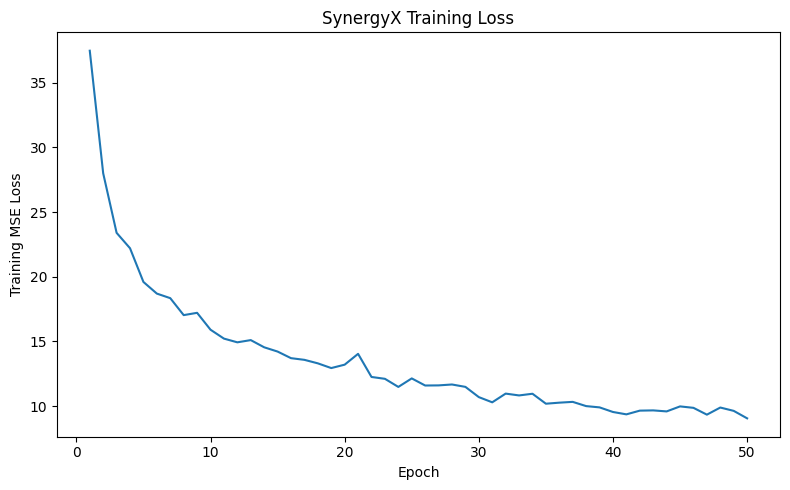

In [ ]:
# ============================================================
# CELL 150: SYNERGYX TRAINING LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")
plt.title("SynergyX Training Loss")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 151: EVALUATE SYNERGYX
# ============================================================

synergyx_model.eval()

synergyx_predictions = []

with torch.no_grad():

    for gene_batch, morgan_batch, drs_batch, y_batch in test_loader:

        gene_batch = gene_batch.to(device)
        morgan_batch = morgan_batch.to(device)
        drs_batch = drs_batch.to(device)

        predictions, _ = synergyx_model(
            gene_batch,
            morgan_batch,
            drs_batch
        )

        synergyx_predictions.extend(
            predictions.cpu().numpy().flatten()
        )

y_pred_synergyx = np.array(
    synergyx_predictions
)

print("Predictions:", len(y_pred_synergyx))
print("Actual values:", len(y_test_b))

Predictions: 1077
Actual values: 1077


In [ ]:
# ============================================================
# CELL 152: SYNERGYX METRICS
# ============================================================

synergyx_mae = mean_absolute_error(
    y_test_b,
    y_pred_synergyx
)

synergyx_mse = mean_squared_error(
    y_test_b,
    y_pred_synergyx
)

synergyx_rmse = np.sqrt(
    synergyx_mse
)

synergyx_r2 = r2_score(
    y_test_b,
    y_pred_synergyx
)

synergyx_pearson, synergyx_p = pearsonr(
    y_test_b,
    y_pred_synergyx
)

synergyx_result = pd.DataFrame([{
    "Model": "SynergyX",
    "MAE": synergyx_mae,
    "MSE": synergyx_mse,
    "RMSE": synergyx_rmse,
    "R2": synergyx_r2,
    "Pearson_r": synergyx_pearson
}])

display(synergyx_result)

print("\nSynergyX Results")
print("----------------")
print("MAE       :", round(synergyx_mae, 4))
print("MSE       :", round(synergyx_mse, 4))
print("RMSE      :", round(synergyx_rmse, 4))
print("R2        :", round(synergyx_r2, 4))
print("Pearson r :", round(synergyx_pearson, 4))

,Model,MAE,MSE,RMSE,R2,Pearson_r
0,SynergyX,2.69578,15.066641,3.881577,0.635137,0.80041



SynergyX Results
----------------
MAE       : 2.6958
MSE       : 15.0666
RMSE      : 3.8816
R2        : 0.6351
Pearson r : 0.8004


In [ ]:
# ============================================================
# CELL 153: FINAL 5-MODEL COMPARISON
# ============================================================

five_model_results = pd.DataFrame([
    {
        "Model": "LASSO",
        "MAE": results_b_df[
            results_b_df["Model"] == "LASSO"
        ]["MAE"].iloc[0],
        "MSE": results_b_df[
            results_b_df["Model"] == "LASSO"
        ]["MSE"].iloc[0],
        "RMSE": results_b_df[
            results_b_df["Model"] == "LASSO"
        ]["RMSE"].iloc[0],
        "R2": results_b_df[
            results_b_df["Model"] == "LASSO"
        ]["R2"].iloc[0]
    },
    {
        "Model": "AdaBoost",
        "MAE": results_b_df[
            results_b_df["Model"] == "AdaBoost"
        ]["MAE"].iloc[0],
        "MSE": results_b_df[
            results_b_df["Model"] == "AdaBoost"
        ]["MSE"].iloc[0],
        "RMSE": results_b_df[
            results_b_df["Model"] == "AdaBoost"
        ]["RMSE"].iloc[0],
        "R2": results_b_df[
            results_b_df["Model"] == "AdaBoost"
        ]["R2"].iloc[0]
    },
    {
        "Model": "Random Forest",
        "MAE": results_b_df[
            results_b_df["Model"] == "Random Forest"
        ]["MAE"].iloc[0],
        "MSE": results_b_df[
            results_b_df["Model"] == "Random Forest"
        ]["MSE"].iloc[0],
        "RMSE": results_b_df[
            results_b_df["Model"] == "Random Forest"
        ]["RMSE"].iloc[0],
        "R2": results_b_df[
            results_b_df["Model"] == "Random Forest"
        ]["R2"].iloc[0]
    },
    {
        "Model": "XGBoost",
        "MAE": results_b_df[
            results_b_df["Model"] == "XGBoost"
        ]["MAE"].iloc[0],
        "MSE": results_b_df[
            results_b_df["Model"] == "XGBoost"
        ]["MSE"].iloc[0],
        "RMSE": results_b_df[
            results_b_df["Model"] == "XGBoost"
        ]["RMSE"].iloc[0],
        "R2": results_b_df[
            results_b_df["Model"] == "XGBoost"
        ]["R2"].iloc[0]
    },
    {
        "Model": "SynergyX",
        "MAE": synergyx_mae,
        "MSE": synergyx_mse,
        "RMSE": synergyx_rmse,
        "R2": synergyx_r2
    }
])

five_model_results = five_model_results.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

display(five_model_results)

,Model,MAE,MSE,RMSE,R2
0,SynergyX,2.695780,15.066641,3.881577,0.635137
1,Random Forest,2.936624,17.522711,4.186014,0.575659
2,XGBoost,2.988143,17.712530,4.208626,0.571063
3,LASSO,3.474922,22.536085,4.747219,0.454253
4,AdaBoost,4.150227,29.085492,5.393097,0.295648


In [ ]:
# ============================================================
# CELL 154: BEST MODEL AMONG FIVE
# ============================================================

best_five_model = five_model_results.iloc[0]

print("=" * 60)
print("BEST MODEL")
print("=" * 60)

print("Model :", best_five_model["Model"])
print("RMSE  :", round(best_five_model["RMSE"], 4))
print("R²    :", round(best_five_model["R2"], 4))
print("MAE   :", round(best_five_model["MAE"], 4))

print("\n✓ Best model selected using highest R².")

BEST MODEL
Model : SynergyX
RMSE  : 3.8816
R²    : 0.6351
MAE   : 2.6958

✓ Best model selected using highest R².


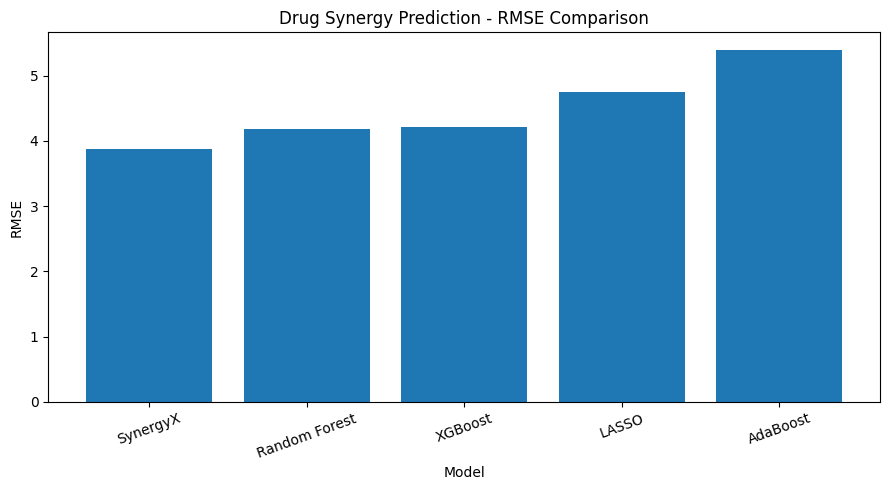

In [ ]:
# ============================================================
# CELL 155: RMSE COMPARISON - FIVE MODELS
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    five_model_results["Model"],
    five_model_results["RMSE"]
)

plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("Drug Synergy Prediction - RMSE Comparison")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

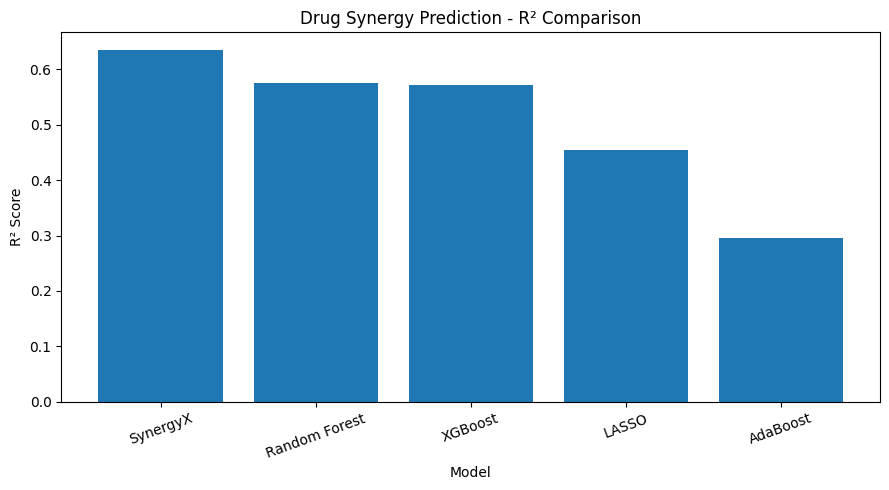

In [ ]:
# ============================================================
# CELL 156: R2 COMPARISON - FIVE MODELS
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    five_model_results["Model"],
    five_model_results["R2"]
)

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Drug Synergy Prediction - R² Comparison")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 157: SAVE FINAL FIVE-MODEL RESULTS
# ============================================================

five_model_path = os.path.join(
    PROCESSED_DIR,
    "FINAL_FIVE_MODEL_COMPARISON.csv"
)

five_model_results.to_csv(
    five_model_path,
    index=False
)

print("✓ Final five-model comparison saved:")
print(five_model_path)

✓ Final five-model comparison saved:
/content/drive/MyDrive/drug_synergy_project/processed/FINAL_FIVE_MODEL_COMPARISON.csv


In [ ]:
# ============================================================
# CELL 158: STRUCTURE FEATURE EXPERIMENT
# Morgan fingerprints = Structure features
# ============================================================

# Model B already contains:
# 50 Gene features
# 4096 Morgan features
# 18 DRS/GDSC features

# Extract ONLY Morgan features
X_structure = X_b[:, MORGAN_START:MORGAN_END].astype(np.float32)

y_structure = y_b.astype(np.float32)

print("Structure feature shape:", X_structure.shape)
print("Number of structure features:", X_structure.shape[1])
print("Target shape:", y_structure.shape)

Structure feature shape: (5381, 4096)
Number of structure features: 4096
Target shape: (5381,)


In [ ]:
# ============================================================
# CELL 159: STRUCTURE TRAIN/TEST SPLIT
# ============================================================

X_structure_train = X_structure[train_idx_g]
X_structure_test = X_structure[test_idx_g]

y_structure_train = y_structure[train_idx_g]
y_structure_test = y_structure[test_idx_g]

print("Training shape:", X_structure_train.shape)
print("Testing shape :", X_structure_test.shape)

print("Training targets:", y_structure_train.shape)
print("Testing targets :", y_structure_test.shape)

Training shape: (4324, 4096)
Testing shape : (1057, 4096)
Training targets: (4324,)
Testing targets : (1057,)


In [ ]:
# ============================================================
# CELL 160: STRUCTURE - FOUR CLASSICAL ML MODELS
# ============================================================

structure_models = {

    "LASSO": Lasso(
        alpha=0.01,
        max_iter=1000
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=30,
        max_depth=8,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ),

    "AdaBoost": AdaBoostRegressor(
        n_estimators=30,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.7,
        objective="reg:squarederror",
        n_jobs=-1,
        random_state=42
    )
}

structure_results = []
structure_trained_models = {}

for name, model in structure_models.items():

    print("Training:", name)

    model.fit(
        X_structure_train,
        y_structure_train
    )

    prediction = model.predict(
        X_structure_test
    )

    mae = mean_absolute_error(
        y_structure_test,
        prediction
    )

    mse = mean_squared_error(
        y_structure_test,
        prediction
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_structure_test,
        prediction
    )

    structure_results.append({
        "Model": name,
        "Feature_Group": "Structure",
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

    structure_trained_models[name] = model

    print(
        f"  RMSE = {rmse:.4f}, "
        f"R2 = {r2:.4f}"
    )

print("\n✓ Four Structure models completed.")

Training: LASSO


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.448e+01, tolerance: 1.795e+01
  model = cd_fast.enet_coordinate_descent(


  RMSE = 7.0000, R2 = 0.1061
Training: Random Forest
  RMSE = 7.0955, R2 = 0.0816
Training: AdaBoost
  RMSE = 7.1190, R2 = 0.0755
Training: XGBoost
  RMSE = 6.9513, R2 = 0.1185

✓ Four Structure models completed.


In [ ]:
# ============================================================
# CELL 161: STRUCTURE-ONLY SYNERGYX
# ============================================================

class StructureSynergyX(nn.Module):

    def __init__(
        self,
        fingerprint_dim=2048,
        hidden_dim=64,
        num_heads=4
    ):
        super().__init__()

        # Drug 1 encoder
        self.drug1_encoder = nn.Sequential(
            nn.Linear(fingerprint_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, hidden_dim)
        )

        # Drug 2 encoder
        self.drug2_encoder = nn.Sequential(
            nn.Linear(fingerprint_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, hidden_dim)
        )

        # Attention between Drug 1 and Drug 2
        self.attention = nn.MultiheadAttention(
            embed_dim=hidden_dim,
            num_heads=num_heads,
            batch_first=True
        )

        # Final regression layer
        self.regressor = nn.Sequential(
            nn.Linear(hidden_dim * 2, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, drug1, drug2):

        drug1_embedding = self.drug1_encoder(drug1)

        drug2_embedding = self.drug2_encoder(drug2)

        # Two drugs become two tokens
        drug_tokens = torch.stack(
            [
                drug1_embedding,
                drug2_embedding
            ],
            dim=1
        )

        attended, attention_weights = self.attention(
            drug_tokens,
            drug_tokens,
            drug_tokens
        )

        fused = attended.reshape(
            attended.size(0),
            -1
        )

        output = self.regressor(fused)

        return output, attention_weights

In [ ]:
# ============================================================
# CELL 162: SEPARATE DRUG 1 / DRUG 2 FINGERPRINTS
# ============================================================

drug1_start = 0
drug1_end = MORGAN_BITS

drug2_start = MORGAN_BITS
drug2_end = MORGAN_BITS * 2

drug1_train = X_structure_train[
    :, drug1_start:drug1_end
]

drug2_train = X_structure_train[
    :, drug2_start:drug2_end
]

drug1_test = X_structure_test[
    :, drug1_start:drug1_end
]

drug2_test = X_structure_test[
    :, drug2_start:drug2_end
]

print("Drug 1 train:", drug1_train.shape)
print("Drug 2 train:", drug2_train.shape)

print("Drug 1 test :", drug1_test.shape)
print("Drug 2 test :", drug2_test.shape)

Drug 1 train: (4324, 2048)
Drug 2 train: (4324, 2048)
Drug 1 test : (1057, 2048)
Drug 2 test : (1057, 2048)


In [ ]:
# ============================================================
# CELL 163: STRUCTURE SYNERGYX DATA LOADERS
# ============================================================

structure_train_dataset = TensorDataset(
    torch.tensor(drug1_train, dtype=torch.float32),
    torch.tensor(drug2_train, dtype=torch.float32),
    torch.tensor(
        y_structure_train.reshape(-1, 1),
        dtype=torch.float32
    )
)

structure_test_dataset = TensorDataset(
    torch.tensor(drug1_test, dtype=torch.float32),
    torch.tensor(drug2_test, dtype=torch.float32),
    torch.tensor(
        y_structure_test.reshape(-1, 1),
        dtype=torch.float32
    )
)

structure_train_loader = DataLoader(
    structure_train_dataset,
    batch_size=64,
    shuffle=True
)

structure_test_loader = DataLoader(
    structure_test_dataset,
    batch_size=128,
    shuffle=False
)

print("Training samples:", len(structure_train_dataset))
print("Testing samples :", len(structure_test_dataset))

Training samples: 4324
Testing samples : 1057


In [ ]:
# ============================================================
# CELL 164: INITIALIZE STRUCTURE SYNERGYX
# ============================================================

structure_synergyx = StructureSynergyX(
    fingerprint_dim=2048,
    hidden_dim=64,
    num_heads=4
).to(device)

structure_criterion = nn.MSELoss()

structure_optimizer = torch.optim.Adam(
    structure_synergyx.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

STRUCTURE_EPOCHS = 40

print(structure_synergyx)
print("\nEpochs:", STRUCTURE_EPOCHS)
print("Device:", device)

StructureSynergyX(
  (drug1_encoder): Sequential(
    (0): Linear(in_features=2048, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
  )
  (drug2_encoder): Sequential(
    (0): Linear(in_features=2048, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
  )
  (attention): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
  )
  (regressor): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=1, bias=True)
  )
)

Epochs: 40
Device: cpu


In [ ]:
# ============================================================
# CELL 165: TRAIN STRUCTURE SYNERGYX
# ============================================================

structure_train_losses = []

print("Training Structure SynergyX...")
print("-" * 60)

for epoch in range(STRUCTURE_EPOCHS):

    structure_synergyx.train()

    running_loss = 0.0

    for drug1_batch, drug2_batch, y_batch in structure_train_loader:

        drug1_batch = drug1_batch.to(device)
        drug2_batch = drug2_batch.to(device)
        y_batch = y_batch.to(device)

        structure_optimizer.zero_grad()

        predictions, attention_weights = structure_synergyx(
            drug1_batch,
            drug2_batch
        )

        loss = structure_criterion(
            predictions,
            y_batch
        )

        loss.backward()

        structure_optimizer.step()

        running_loss += loss.item()

    epoch_loss = (
        running_loss /
        len(structure_train_loader)
    )

    structure_train_losses.append(epoch_loss)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch + 1:02d}/{STRUCTURE_EPOCHS} "
            f"- Loss: {epoch_loss:.4f}"
        )

print("-" * 60)
print("✓ Structure SynergyX training completed.")

Training Structure SynergyX...
------------------------------------------------------------
Epoch 05/40 - Loss: 34.2928
Epoch 10/40 - Loss: 31.5666
Epoch 15/40 - Loss: 30.1836
Epoch 20/40 - Loss: 29.5191
Epoch 25/40 - Loss: 28.8943
Epoch 30/40 - Loss: 28.5147
Epoch 35/40 - Loss: 28.0696
Epoch 40/40 - Loss: 27.8578
------------------------------------------------------------
✓ Structure SynergyX training completed.


In [ ]:
# ============================================================
# CELL 166: EVALUATE STRUCTURE SYNERGYX
# ============================================================

structure_synergyx.eval()

structure_predictions = []

with torch.no_grad():

    for drug1_batch, drug2_batch, y_batch in structure_test_loader:

        drug1_batch = drug1_batch.to(device)
        drug2_batch = drug2_batch.to(device)

        predictions, _ = structure_synergyx(
            drug1_batch,
            drug2_batch
        )

        structure_predictions.extend(
            predictions.cpu().numpy().flatten()
        )

y_pred_structure_synergyx = np.array(
    structure_predictions
)

structure_synergyx_mae = mean_absolute_error(
    y_structure_test,
    y_pred_structure_synergyx
)

structure_synergyx_mse = mean_squared_error(
    y_structure_test,
    y_pred_structure_synergyx
)

structure_synergyx_rmse = np.sqrt(
    structure_synergyx_mse
)

structure_synergyx_r2 = r2_score(
    y_structure_test,
    y_pred_structure_synergyx
)

structure_synergyx_pearson, _ = pearsonr(
    y_structure_test,
    y_pred_structure_synergyx
)

structure_results.append({
    "Model": "SynergyX",
    "Feature_Group": "Structure",
    "MAE": structure_synergyx_mae,
    "MSE": structure_synergyx_mse,
    "RMSE": structure_synergyx_rmse,
    "R2": structure_synergyx_r2,
    "Pearson_r": structure_synergyx_pearson
})

print("Structure SynergyX")
print("------------------")
print("MAE       :", round(structure_synergyx_mae, 4))
print("MSE       :", round(structure_synergyx_mse, 4))
print("RMSE      :", round(structure_synergyx_rmse, 4))
print("R2        :", round(structure_synergyx_r2, 4))
print("Pearson r :", round(structure_synergyx_pearson, 4))

Structure SynergyX
------------------
MAE       : 4.4192
MSE       : 41.4853
RMSE      : 6.4409
R2        : 0.2432
Pearson r : 0.4943


In [ ]:
# ============================================================
# CELL 167: STRUCTURE - FIVE MODEL RESULTS
# ============================================================

structure_results_df = pd.DataFrame(
    structure_results
)

structure_results_df = structure_results_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

display(structure_results_df)

,Model,Feature_Group,MAE,MSE,RMSE,R2,Pearson_r
0,SynergyX,Structure,4.419188,41.485283,6.440907,0.243210,0.494312
1,XGBoost,Structure,4.360178,48.320648,6.951306,0.118517,NaN
2,LASSO,Structure,4.483040,48.999428,6.999959,0.106134,NaN
3,Random Forest,Structure,4.436173,50.346674,7.095539,0.081557,NaN
4,AdaBoost,Structure,4.753581,50.680827,7.119047,0.075462,NaN


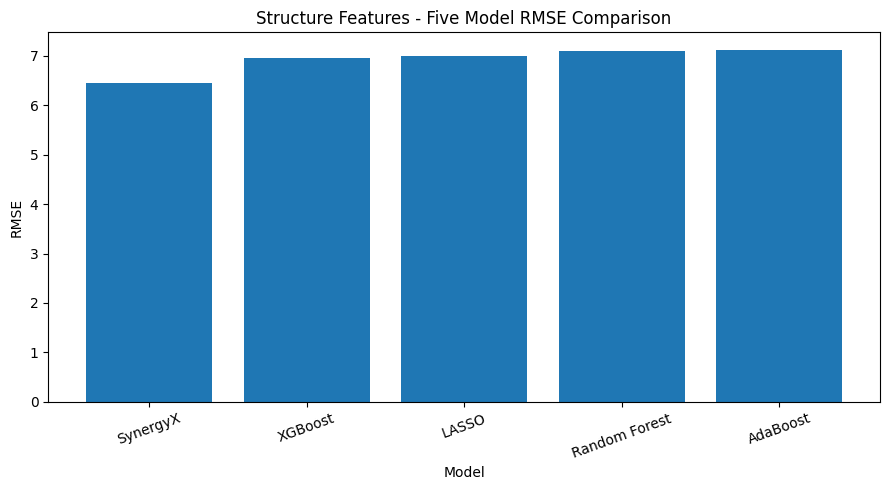

In [ ]:
# ============================================================
# CELL 168: STRUCTURE RMSE COMPARISON
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    structure_results_df["Model"],
    structure_results_df["RMSE"]
)

plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("Structure Features - Five Model RMSE Comparison")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

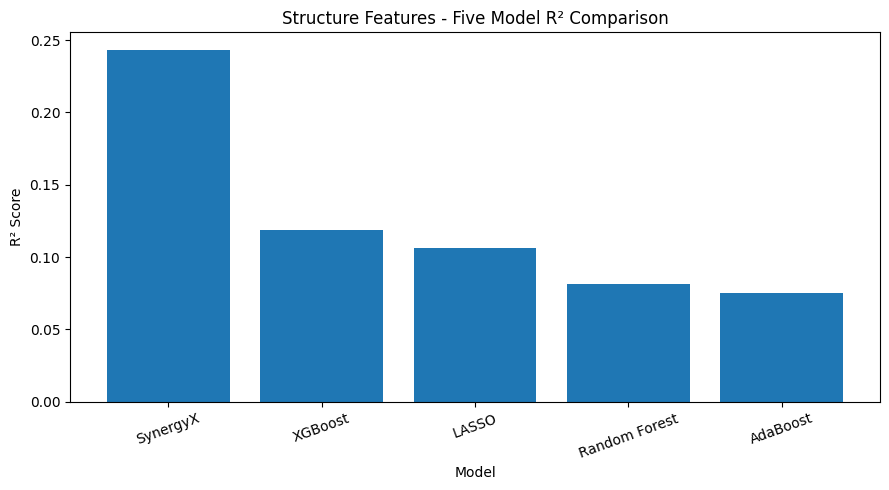

In [ ]:
# ============================================================
# CELL 169: STRUCTURE R2 COMPARISON
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    structure_results_df["Model"],
    structure_results_df["R2"]
)

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Structure Features - Five Model R² Comparison")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 170: SAVE STRUCTURE EXPERIMENT
# ============================================================

structure_results_path = os.path.join(
    PROCESSED_DIR,
    "STRUCTURE_FIVE_MODEL_RESULTS.csv"
)

structure_results_df.to_csv(
    structure_results_path,
    index=False
)

print("✓ Structure experiment saved:")
print(structure_results_path)

✓ Structure experiment saved:
/content/drive/MyDrive/drug_synergy_project/processed/STRUCTURE_FIVE_MODEL_RESULTS.csv


In [ ]:
# ============================================================
# CELL 171: DS / DRUG SIGNATURE FEATURE EXPERIMENT
# 50 GENE-EXPRESSION FEATURES
# ============================================================

# DS in our project is represented by the
# selected 50 gene-expression features.

X_ds = X_b[:, GENE_START:GENE_END].astype(np.float32)
y_ds = y_b.astype(np.float32)

print("DS feature shape:", X_ds.shape)
print("Number of DS features:", X_ds.shape[1])
print("Target shape:", y_ds.shape)

DS feature shape: (5381, 50)
Number of DS features: 50
Target shape: (5381,)


In [ ]:
# ============================================================
# CELL 172: DS TRAIN/TEST SPLIT
# ============================================================

X_ds_train = X_ds[train_idx_g]
X_ds_test = X_ds[test_idx_g]

y_ds_train = y_ds[train_idx_g]
y_ds_test = y_ds[test_idx_g]

print("Training shape:", X_ds_train.shape)
print("Testing shape :", X_ds_test.shape)

print("Training targets:", y_ds_train.shape)
print("Testing targets :", y_ds_test.shape)

Training shape: (4324, 50)
Testing shape : (1057, 50)
Training targets: (4324,)
Testing targets : (1057,)


In [ ]:
# ============================================================
# CELL 173: SCALE DS FEATURES
# ============================================================

ds_scaler = StandardScaler()

X_ds_train_scaled = ds_scaler.fit_transform(
    X_ds_train
).astype(np.float32)

X_ds_test_scaled = ds_scaler.transform(
    X_ds_test
).astype(np.float32)

print("✓ DS scaling completed.")

print(
    "Scaled training shape:",
    X_ds_train_scaled.shape
)

print(
    "Scaled testing shape:",
    X_ds_test_scaled.shape
)

✓ DS scaling completed.
Scaled training shape: (4324, 50)
Scaled testing shape: (1057, 50)


In [ ]:
# ============================================================
# CELL 174: DS - FOUR CLASSICAL ML MODELS
# ============================================================

ds_models = {

    "LASSO": Lasso(
        alpha=0.01,
        max_iter=1000
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=30,
        max_depth=8,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ),

    "AdaBoost": AdaBoostRegressor(
        n_estimators=30,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.7,
        objective="reg:squarederror",
        n_jobs=-1,
        random_state=42
    )
}

ds_results = []
ds_trained_models = {}

for name, model in ds_models.items():

    print("Training:", name)

    model.fit(
        X_ds_train_scaled,
        y_ds_train
    )

    prediction = model.predict(
        X_ds_test_scaled
    )

    mae = mean_absolute_error(
        y_ds_test,
        prediction
    )

    mse = mean_squared_error(
        y_ds_test,
        prediction
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_ds_test,
        prediction
    )

    pearson_value, _ = pearsonr(
        y_ds_test,
        prediction
    )

    ds_results.append({
        "Model": name,
        "Feature_Group": "DS",
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Pearson_r": pearson_value
    })

    ds_trained_models[name] = model

    print(
        f"  RMSE = {rmse:.4f}, "
        f"R2 = {r2:.4f}"
    )

print("\n✓ Four DS models completed.")

Training: LASSO
  RMSE = 6.5658, R2 = 0.2136
Training: Random Forest


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.421e+02, tolerance: 1.795e+01
  model = cd_fast.enet_coordinate_descent(


  RMSE = 6.5749, R2 = 0.2114
Training: AdaBoost
  RMSE = 6.6991, R2 = 0.1813
Training: XGBoost
  RMSE = 6.5800, R2 = 0.2102

✓ Four DS models completed.


In [ ]:
# ============================================================
# CELL 175: DS-ONLY SYNERGYX-STYLE MODEL
# ============================================================

class DSSynergyX(nn.Module):

    def __init__(
        self,
        input_dim=50,
        hidden_dim=64
    ):
        super().__init__()

        self.encoder = nn.Sequential(

            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, hidden_dim),
            nn.ReLU(),

            nn.Dropout(0.2)
        )

        self.regressor = nn.Sequential(

            nn.Linear(hidden_dim, 64),
            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):

        embedding = self.encoder(x)

        output = self.regressor(
            embedding
        )

        return output

In [ ]:
# ============================================================
# CELL 176: CREATE DS PYTORCH DATASET
# ============================================================

ds_train_dataset = TensorDataset(

    torch.tensor(
        X_ds_train_scaled,
        dtype=torch.float32
    ),

    torch.tensor(
        y_ds_train.reshape(-1, 1),
        dtype=torch.float32
    )
)

ds_test_dataset = TensorDataset(

    torch.tensor(
        X_ds_test_scaled,
        dtype=torch.float32
    ),

    torch.tensor(
        y_ds_test.reshape(-1, 1),
        dtype=torch.float32
    )
)

ds_train_loader = DataLoader(
    ds_train_dataset,
    batch_size=64,
    shuffle=True
)

ds_test_loader = DataLoader(
    ds_test_dataset,
    batch_size=128,
    shuffle=False
)

print("Training samples:", len(ds_train_dataset))
print("Testing samples :", len(ds_test_dataset))

Training samples: 4324
Testing samples : 1057


In [ ]:
# ============================================================
# CELL 177: INITIALIZE DS SYNERGYX
# ============================================================

ds_synergyx = DSSynergyX(
    input_dim=50,
    hidden_dim=64
).to(device)

ds_criterion = nn.MSELoss()

ds_optimizer = torch.optim.Adam(
    ds_synergyx.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

DS_EPOCHS = 40

print(ds_synergyx)

print("\nEpochs:", DS_EPOCHS)
print("Learning rate:", 0.001)
print("Device:", device)

DSSynergyX(
  (encoder): Sequential(
    (0): Linear(in_features=50, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
  )
  (regressor): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=1, bias=True)
  )
)

Epochs: 40
Learning rate: 0.001
Device: cpu


In [ ]:
# ============================================================
# CELL 178: TRAIN DS SYNERGYX
# ============================================================

ds_train_losses = []

print("Training DS SynergyX...")
print("-" * 60)

for epoch in range(DS_EPOCHS):

    ds_synergyx.train()

    running_loss = 0.0

    for x_batch, y_batch in ds_train_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        ds_optimizer.zero_grad()

        predictions = ds_synergyx(
            x_batch
        )

        loss = ds_criterion(
            predictions,
            y_batch
        )

        loss.backward()

        ds_optimizer.step()

        running_loss += loss.item()

    epoch_loss = (
        running_loss /
        len(ds_train_loader)
    )

    ds_train_losses.append(
        epoch_loss
    )

    if (epoch + 1) % 5 == 0:

        print(
            f"Epoch {epoch + 1:02d}/{DS_EPOCHS} "
            f"- Loss: {epoch_loss:.4f}"
        )

print("-" * 60)
print("✓ DS SynergyX training completed.")

Training DS SynergyX...
------------------------------------------------------------
Epoch 05/40 - Loss: 33.7485
Epoch 10/40 - Loss: 33.9473
Epoch 15/40 - Loss: 33.5908
Epoch 20/40 - Loss: 33.5592
Epoch 25/40 - Loss: 33.2080
Epoch 30/40 - Loss: 33.6187
Epoch 35/40 - Loss: 33.6449
Epoch 40/40 - Loss: 33.3791
------------------------------------------------------------
✓ DS SynergyX training completed.


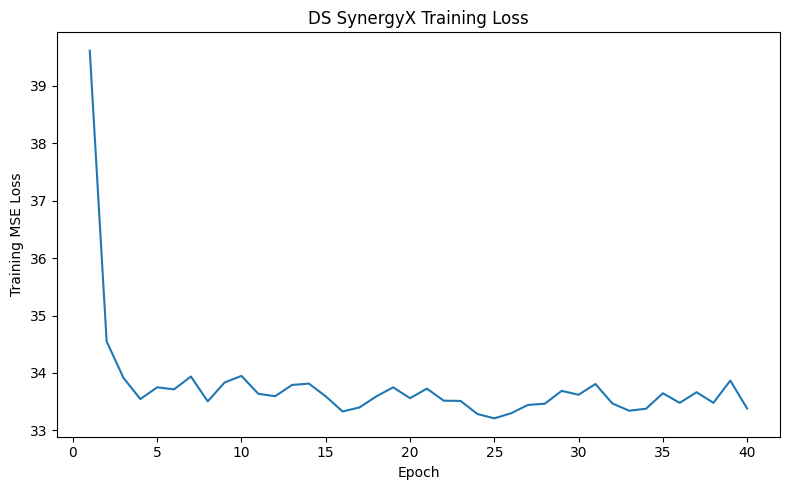

In [ ]:
# ============================================================
# CELL 179: DS SYNERGYX TRAINING LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, DS_EPOCHS + 1),
    ds_train_losses
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")
plt.title("DS SynergyX Training Loss")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 180: EVALUATE DS SYNERGYX
# ============================================================

ds_synergyx.eval()

ds_predictions = []

with torch.no_grad():

    for x_batch, y_batch in ds_test_loader:

        x_batch = x_batch.to(device)

        predictions = ds_synergyx(
            x_batch
        )

        ds_predictions.extend(
            predictions.cpu().numpy().flatten()
        )

y_pred_ds_synergyx = np.array(
    ds_predictions
)

ds_synergyx_mae = mean_absolute_error(
    y_ds_test,
    y_pred_ds_synergyx
)

ds_synergyx_mse = mean_squared_error(
    y_ds_test,
    y_pred_ds_synergyx
)

ds_synergyx_rmse = np.sqrt(
    ds_synergyx_mse
)

ds_synergyx_r2 = r2_score(
    y_ds_test,
    y_pred_ds_synergyx
)

ds_synergyx_pearson, _ = pearsonr(
    y_ds_test,
    y_pred_ds_synergyx
)

print("DS SynergyX")
print("-----------")
print("MAE       :", round(ds_synergyx_mae, 4))
print("MSE       :", round(ds_synergyx_mse, 4))
print("RMSE      :", round(ds_synergyx_rmse, 4))
print("R2        :", round(ds_synergyx_r2, 4))
print("Pearson r :", round(ds_synergyx_pearson, 4))

DS SynergyX
-----------
MAE       : 4.2731
MSE       : 42.7554
RMSE      : 6.5388
R2        : 0.22
Pearson r : 0.4856


In [ ]:
# ============================================================
# CELL 181: ADD DS SYNERGYX RESULTS
# ============================================================

ds_results.append({

    "Model": "SynergyX",

    "Feature_Group": "DS",

    "MAE": ds_synergyx_mae,

    "MSE": ds_synergyx_mse,

    "RMSE": ds_synergyx_rmse,

    "R2": ds_synergyx_r2,

    "Pearson_r": ds_synergyx_pearson
})

ds_results_df = pd.DataFrame(
    ds_results
)

ds_results_df = ds_results_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

display(ds_results_df)

,Model,Feature_Group,MAE,MSE,RMSE,R2,Pearson_r
0,SynergyX,DS,4.273122,42.755409,6.538762,0.220040,0.485581
1,LASSO,DS,4.262953,43.109310,6.565768,0.213584,0.483279
2,Random Forest,DS,4.264477,43.228926,6.574871,0.211402,0.481130
3,XGBoost,DS,4.267720,43.296703,6.580023,0.210166,0.479028
4,AdaBoost,DS,4.552010,44.877328,6.699054,0.181331,0.437574


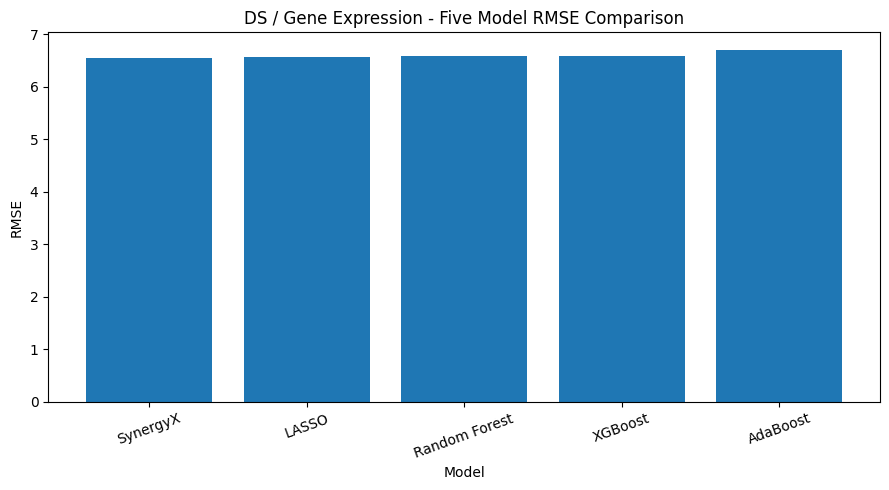

In [ ]:
# ============================================================
# CELL 182: DS RMSE COMPARISON
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    ds_results_df["Model"],
    ds_results_df["RMSE"]
)

plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title(
    "DS / Gene Expression - Five Model RMSE Comparison"
)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

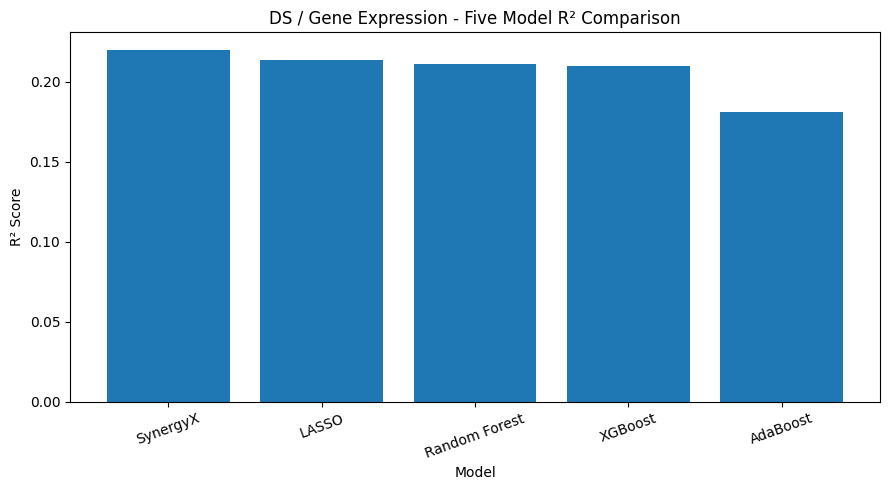

In [ ]:
# ============================================================
# CELL 183: DS R2 COMPARISON
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    ds_results_df["Model"],
    ds_results_df["R2"]
)

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title(
    "DS / Gene Expression - Five Model R² Comparison"
)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 184: SAVE DS FIVE-MODEL RESULTS
# ============================================================

ds_results_path = os.path.join(
    PROCESSED_DIR,
    "DS_FIVE_MODEL_RESULTS.csv"
)

ds_results_df.to_csv(
    ds_results_path,
    index=False
)

print("✓ DS experiment saved:")
print(ds_results_path)

✓ DS experiment saved:
/content/drive/MyDrive/drug_synergy_project/processed/DS_FIVE_MODEL_RESULTS.csv


In [ ]:
# ============================================================
# CELL 185: DRS/GDSC FEATURE EXPERIMENT
# ============================================================

X_drs = X_b[:, DRS_START:DRS_END].astype(np.float32)
y_drs = y_b.astype(np.float32)

print("DRS/GDSC feature shape:", X_drs.shape)
print("Number of DRS/GDSC features:", X_drs.shape[1])
print("Target shape:", y_drs.shape)

DRS/GDSC feature shape: (5381, 18)
Number of DRS/GDSC features: 18
Target shape: (5381,)


In [ ]:
# ============================================================
# CELL 186: DRS TRAIN/TEST SPLIT
# ============================================================

X_drs_train = X_drs[train_idx_g]
X_drs_test = X_drs[test_idx_g]

y_drs_train = y_drs[train_idx_g]
y_drs_test = y_drs[test_idx_g]

print("Training shape:", X_drs_train.shape)
print("Testing shape :", X_drs_test.shape)

print("Training targets:", y_drs_train.shape)
print("Testing targets :", y_drs_test.shape)

Training shape: (4324, 18)
Testing shape : (1057, 18)
Training targets: (4324,)
Testing targets : (1057,)


In [ ]:
# ============================================================
# CELL 187: SCALE DRS/GDSC FEATURES
# ============================================================

drs_scaler_experiment = StandardScaler()

X_drs_train_scaled = drs_scaler_experiment.fit_transform(
    X_drs_train
).astype(np.float32)

X_drs_test_scaled = drs_scaler_experiment.transform(
    X_drs_test
).astype(np.float32)

print("✓ DRS/GDSC scaling completed.")

print(
    "Scaled training shape:",
    X_drs_train_scaled.shape
)

print(
    "Scaled testing shape:",
    X_drs_test_scaled.shape
)

✓ DRS/GDSC scaling completed.
Scaled training shape: (4324, 18)
Scaled testing shape: (1057, 18)


In [ ]:
# ============================================================
# CELL 188 — Train Four Classical DRS Models
# FIX: Handle remaining NaN values before model training
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

print("Preparing DRS data...")

# ------------------------------------------------------------
# 1. IMPUTE MISSING VALUES
# ------------------------------------------------------------

drs_imputer = SimpleImputer(strategy="median")

X_drs_train_imputed = drs_imputer.fit_transform(
    X_drs_train
).astype(np.float32)

X_drs_test_imputed = drs_imputer.transform(
    X_drs_test
).astype(np.float32)

print("✓ Missing values handled")

print("NaN in training data:",
      np.isnan(X_drs_train_imputed).sum())

print("NaN in test data:",
      np.isnan(X_drs_test_imputed).sum())


# ------------------------------------------------------------
# 2. SCALE DRS FEATURES
# ------------------------------------------------------------

drs_scaler = StandardScaler()

X_drs_train_scaled = drs_scaler.fit_transform(
    X_drs_train_imputed
).astype(np.float32)

X_drs_test_scaled = drs_scaler.transform(
    X_drs_test_imputed
).astype(np.float32)

print("✓ DRS features scaled")

print("Training shape:", X_drs_train_scaled.shape)
print("Testing shape :", X_drs_test_scaled.shape)


# ------------------------------------------------------------
# 3. DEFINE FOUR CLASSICAL MODELS
# ------------------------------------------------------------

drs_models = {

    "LASSO": Lasso(
        alpha=0.01,
        max_iter=2000
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=30,
        max_depth=8,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ),

    "AdaBoost": AdaBoostRegressor(
        n_estimators=30,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.7,
        objective="reg:squarederror",
        n_jobs=-1,
        random_state=42
    )
}


# ------------------------------------------------------------
# 4. TRAIN AND EVALUATE
# ------------------------------------------------------------

drs_results = []
drs_trained_models = {}

for name, model in drs_models.items():

    print("\nTraining:", name)

    model.fit(
        X_drs_train_scaled,
        y_drs_train
    )

    predictions = model.predict(
        X_drs_test_scaled
    )

    mae = mean_absolute_error(
        y_drs_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_drs_test,
            predictions
        )
    )

    r2 = r2_score(
        y_drs_test,
        predictions
    )

    drs_trained_models[name] = model

    drs_results.append({
        "Feature Group": "DRS",
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print("MAE :", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2  :", round(r2, 4))


# ------------------------------------------------------------
# 5. CREATE RESULTS TABLE
# ------------------------------------------------------------

drs_results_df = pd.DataFrame(drs_results)

print("\n============================================")
print("DRS CLASSICAL MODEL RESULTS")
print("============================================")

display(drs_results_df)

Preparing DRS data...
✓ Missing values handled
NaN in training data: 0
NaN in test data: 0
✓ DRS features scaled
Training shape: (4324, 18)
Testing shape : (1057, 18)

Training: LASSO
MAE : 3.9207
RMSE: 6.0126
R2  : 0.3405

Training: Random Forest
MAE : 3.4003
RMSE: 5.3901
R2  : 0.47

Training: AdaBoost
MAE : 3.8651
RMSE: 5.7057
R2  : 0.4061

Training: XGBoost
MAE : 3.3197
RMSE: 5.2199
R2  : 0.5029

DRS CLASSICAL MODEL RESULTS


,Feature Group,Model,MAE,RMSE,R2
0,DRS,LASSO,3.920705,6.012599,0.340514
1,DRS,Random Forest,3.400262,5.390135,0.469994
2,DRS,AdaBoost,3.865109,5.705683,0.406123
3,DRS,XGBoost,3.319666,5.219885,0.502947


In [ ]:
# ============================================================
# CELL 189 — Prepare DRS Data for SynergyX
# ============================================================

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Use the already imputed + scaled DRS data
X_drs_train_t = torch.tensor(
    X_drs_train_scaled,
    dtype=torch.float32
)

X_drs_test_t = torch.tensor(
    X_drs_test_scaled,
    dtype=torch.float32
)

y_drs_train_t = torch.tensor(
    y_drs_train,
    dtype=torch.float32
).view(-1, 1)

y_drs_test_t = torch.tensor(
    y_drs_test,
    dtype=torch.float32
).view(-1, 1)

print("DRS SynergyX training shape:", X_drs_train_t.shape)
print("DRS SynergyX testing shape :", X_drs_test_t.shape)

DRS SynergyX training shape: torch.Size([4324, 18])
DRS SynergyX testing shape : torch.Size([1057, 18])


In [ ]:
# ============================================================
# CELL 190 — DRS SynergyX Model
# ============================================================

class DRSSynergyX(nn.Module):

    def __init__(self, input_dim=18, hidden_dim=64):

        super().__init__()

        self.encoder = nn.Sequential(

            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2)
        )

        self.regressor = nn.Sequential(

            nn.Linear(hidden_dim, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):

        embedding = self.encoder(x)

        output = self.regressor(embedding)

        return output


drs_synergyx_model = DRSSynergyX(
    input_dim=X_drs_train_scaled.shape[1],
    hidden_dim=64
).to(device)

print(drs_synergyx_model)

DRSSynergyX(
  (encoder): Sequential(
    (0): Linear(in_features=18, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
  )
  (regressor): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [ ]:
# ============================================================
# CELL 191 — DRS SynergyX DataLoader
# ============================================================

drs_dataset = TensorDataset(
    X_drs_train_t,
    y_drs_train_t
)

drs_loader = DataLoader(
    drs_dataset,
    batch_size=64,
    shuffle=True
)

print("Number of training batches:", len(drs_loader))

Number of training batches: 68


In [ ]:
# ============================================================
# CELL 192 — Train DRS SynergyX
# ============================================================

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    drs_synergyx_model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

DRS_EPOCHS = 40

drs_synergyx_model.train()

for epoch in range(DRS_EPOCHS):

    epoch_loss = 0.0

    for batch_X, batch_y in drs_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        predictions = drs_synergyx_model(batch_X)

        loss = criterion(
            predictions,
            batch_y
        )

        loss.backward()

        optimizer.step()

        epoch_loss += loss.item()

    epoch_loss /= len(drs_loader)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch [{epoch+1}/{DRS_EPOCHS}] "
            f"Loss: {epoch_loss:.6f}"
        )

print("\n✓ DRS SynergyX training completed")

Epoch [5/40] Loss: 26.910815
Epoch [10/40] Loss: 22.990464
Epoch [15/40] Loss: 21.136045
Epoch [20/40] Loss: 19.872895
Epoch [25/40] Loss: 19.096958
Epoch [30/40] Loss: 18.656217
Epoch [35/40] Loss: 18.124679
Epoch [40/40] Loss: 17.021719

✓ DRS SynergyX training completed


In [ ]:
# ============================================================
# CELL 193 — Evaluate DRS SynergyX
# ============================================================

drs_synergyx_model.eval()

with torch.no_grad():

    X_test_tensor = X_drs_test_t.to(device)

    predictions_drs = drs_synergyx_model(
        X_test_tensor
    )

    predictions_drs = predictions_drs.cpu().numpy().flatten()


drs_synergyx_mae = mean_absolute_error(
    y_drs_test,
    predictions_drs
)

drs_synergyx_mse = mean_squared_error(
    y_drs_test,
    predictions_drs
)

drs_synergyx_rmse = np.sqrt(
    drs_synergyx_mse
)

drs_synergyx_r2 = r2_score(
    y_drs_test,
    predictions_drs
)

print("============================================")
print("DRS SYNERGYX RESULTS")
print("============================================")

print("MAE :", round(drs_synergyx_mae, 4))
print("RMSE:", round(drs_synergyx_rmse, 4))
print("R2  :", round(drs_synergyx_r2, 4))

DRS SYNERGYX RESULTS
MAE : 3.3886
RMSE: 4.8945
R2  : 0.563


In [ ]:
# ============================================================
# CELL 194 — Add DRS SynergyX to Results
# ============================================================

drs_results.append({

    "Feature Group": "DRS",

    "Model": "SynergyX",

    "MAE": drs_synergyx_mae,

    "RMSE": drs_synergyx_rmse,

    "R2": drs_synergyx_r2
})

drs_results_df = pd.DataFrame(
    drs_results
)

print("============================================")
print("FINAL DRS FIVE-MODEL RESULTS")
print("============================================")

display(
    drs_results_df.sort_values(
        "R2",
        ascending=False
    ).reset_index(drop=True)
)

FINAL DRS FIVE-MODEL RESULTS


,Feature Group,Model,MAE,RMSE,R2
0,DRS,SynergyX,3.388636,4.894521,0.562980
1,DRS,XGBoost,3.319666,5.219885,0.502947
2,DRS,Random Forest,3.400262,5.390135,0.469994
3,DRS,AdaBoost,3.865109,5.705683,0.406123
4,DRS,LASSO,3.920705,6.012599,0.340514


In [ ]:
# ============================================================
# CELL 195 — Save DRS Five-Model Results
# ============================================================

drs_results_file = os.path.join(
    PROCESSED_DIR,
    "DRS_FIVE_MODEL_RESULTS.csv"
)

drs_results_df.to_csv(
    drs_results_file,
    index=False
)

print("✓ DRS results saved:")
print(drs_results_file)

✓ DRS results saved:
/content/drive/MyDrive/drug_synergy_project/processed/DRS_FIVE_MODEL_RESULTS.csv


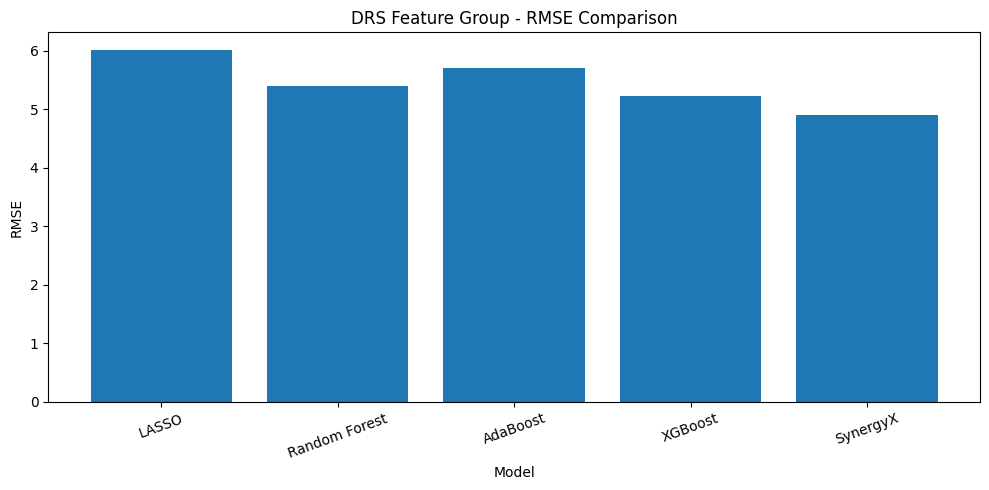

In [ ]:
# ============================================================
# CELL 196 — DRS RMSE Comparison
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    drs_results_df["Model"],
    drs_results_df["RMSE"]
)

plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("DRS Feature Group - RMSE Comparison")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

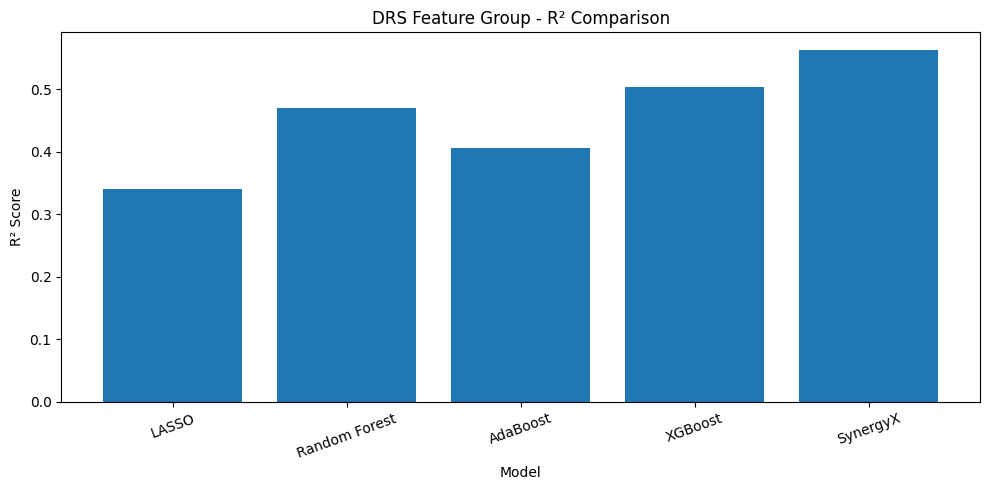

In [ ]:
# ============================================================
# CELL 197 — DRS R² Comparison
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    drs_results_df["Model"],
    drs_results_df["R2"]
)

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("DRS Feature Group - R² Comparison")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 198 — Select Best DRS Model
# ============================================================

best_drs_row = drs_results_df.loc[
    drs_results_df["R2"].idxmax()
]

print("============================================")
print("BEST DRS MODEL")
print("============================================")

print("Model :", best_drs_row["Model"])
print("MAE   :", round(best_drs_row["MAE"], 4))
print("RMSE  :", round(best_drs_row["RMSE"], 4))
print("R2    :", round(best_drs_row["R2"], 4))

BEST DRS MODEL
Model : SynergyX
MAE   : 3.3886
RMSE  : 4.8945
R2    : 0.563


In [ ]:
# ============================================================
# CELL 199 — Combined Structure + DS + DRS
# ============================================================

print("Preparing combined feature dataset...")

# Original full feature matrix
X_combined = X_b.astype(np.float32)
y_combined = y_b.astype(np.float32)

# Use previously created grouped split
X_combined_train_raw = X_combined[train_idx_g]
X_combined_test_raw = X_combined[test_idx_g]

y_combined_train = y_combined[train_idx_g]
y_combined_test = y_combined[test_idx_g]

print("Training samples:", X_combined_train_raw.shape[0])
print("Testing samples :", X_combined_test_raw.shape[0])
print("Total features  :", X_combined_train_raw.shape[1])

Preparing combined feature dataset...
Training samples: 4324
Testing samples : 1057
Total features  : 4164


In [ ]:
# ============================================================
# CELL 200 — Separate Structure, DS and DRS
# ============================================================

# ------------------------------------------------------------
# STRUCTURE
# ------------------------------------------------------------

X_combined_structure_train = (
    X_combined_train_raw[:, MORGAN_START:MORGAN_END]
)

X_combined_structure_test = (
    X_combined_test_raw[:, MORGAN_START:MORGAN_END]
)


# ------------------------------------------------------------
# DS / GENE EXPRESSION
# ------------------------------------------------------------

X_combined_ds_train = (
    X_combined_train_raw[:, GENE_START:GENE_END]
)

X_combined_ds_test = (
    X_combined_test_raw[:, GENE_START:GENE_END]
)


# ------------------------------------------------------------
# DRS
# ------------------------------------------------------------

X_combined_drs_train = (
    X_combined_train_raw[:, DRS_START:DRS_END]
)

X_combined_drs_test = (
    X_combined_test_raw[:, DRS_START:DRS_END]
)


print("Structure train:",
      X_combined_structure_train.shape)

print("DS train:",
      X_combined_ds_train.shape)

print("DRS train:",
      X_combined_drs_train.shape)

Structure train: (4324, 4096)
DS train: (4324, 50)
DRS train: (4324, 18)


In [ ]:
# ============================================================
# CELL 201 — Impute and Scale Continuous Features
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# ============================================================
# DS
# ============================================================

combined_ds_imputer = SimpleImputer(
    strategy="median"
)

X_combined_ds_train_imp = (
    combined_ds_imputer.fit_transform(
        X_combined_ds_train
    )
)

X_combined_ds_test_imp = (
    combined_ds_imputer.transform(
        X_combined_ds_test
    )
)

combined_ds_scaler = StandardScaler()

X_combined_ds_train_scaled = (
    combined_ds_scaler.fit_transform(
        X_combined_ds_train_imp
    ).astype(np.float32)
)

X_combined_ds_test_scaled = (
    combined_ds_scaler.transform(
        X_combined_ds_test_imp
    ).astype(np.float32)
)


# ============================================================
# DRS
# ============================================================

combined_drs_imputer = SimpleImputer(
    strategy="median"
)

X_combined_drs_train_imp = (
    combined_drs_imputer.fit_transform(
        X_combined_drs_train
    )
)

X_combined_drs_test_imp = (
    combined_drs_imputer.transform(
        X_combined_drs_test
    )
)

combined_drs_scaler = StandardScaler()

X_combined_drs_train_scaled = (
    combined_drs_scaler.fit_transform(
        X_combined_drs_train_imp
    ).astype(np.float32)
)

X_combined_drs_test_scaled = (
    combined_drs_scaler.transform(
        X_combined_drs_test_imp
    ).astype(np.float32)
)


print("✓ DS imputation + scaling completed")
print("✓ DRS imputation + scaling completed")

✓ DS imputation + scaling completed
✓ DRS imputation + scaling completed


In [ ]:
# ============================================================
# CELL 202 — Create Combined 4164-Feature Matrix
# ============================================================

X_combined_train = np.hstack([
    X_combined_ds_train_scaled,
    X_combined_structure_train,
    X_combined_drs_train_scaled
]).astype(np.float32)

X_combined_test = np.hstack([
    X_combined_ds_test_scaled,
    X_combined_structure_test,
    X_combined_drs_test_scaled
]).astype(np.float32)

print("============================================")
print("COMBINED FEATURE MATRIX")
print("============================================")

print("Training shape:", X_combined_train.shape)
print("Testing shape :", X_combined_test.shape)

print(
    "Expected total features:",
    len(gene_feature_cols)
    + (MORGAN_BITS * 2)
    + len(drs_all_feature_cols)
)

print(
    "NaN in train:",
    np.isnan(X_combined_train).sum()
)

print(
    "NaN in test:",
    np.isnan(X_combined_test).sum()
)

COMBINED FEATURE MATRIX
Training shape: (4324, 4164)
Testing shape : (1057, 4164)
Expected total features: 4164
NaN in train: 0
NaN in test: 0


In [ ]:
# ============================================================
# CELL 203 — Combined Classical Models
# ============================================================

combined_models = {

    "LASSO": Lasso(
        alpha=0.01,
        max_iter=2000
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=30,
        max_depth=8,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ),

    "AdaBoost": AdaBoostRegressor(
        n_estimators=30,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.7,
        objective="reg:squarederror",
        n_jobs=-1,
        random_state=42
    )
}

print("✓ Four combined models created")

✓ Four combined models created


In [ ]:
# ============================================================
# CELL 204 — Train Combined Classical Models
# ============================================================

combined_results = []
combined_trained_models = {}

for name, model in combined_models.items():

    print("\n============================================")
    print("Training:", name)
    print("============================================")

    model.fit(
        X_combined_train,
        y_combined_train
    )

    predictions = model.predict(
        X_combined_test
    )

    mae = mean_absolute_error(
        y_combined_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_combined_test,
            predictions
        )
    )

    r2 = r2_score(
        y_combined_test,
        predictions
    )

    combined_trained_models[name] = model

    combined_results.append({

        "Feature Group": "Combined",

        "Model": name,

        "MAE": mae,

        "RMSE": rmse,

        "R2": r2
    })

    print("MAE :", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2  :", round(r2, 4))


Training: LASSO


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.512e+01, tolerance: 1.795e+01
  model = cd_fast.enet_coordinate_descent(


MAE : 3.688
RMSE: 5.4397
R2  : 0.4602

Training: Random Forest
MAE : 3.4442
RMSE: 5.4435
R2  : 0.4595

Training: AdaBoost
MAE : 3.9427
RMSE: 5.8398
R2  : 0.3779

Training: XGBoost
MAE : 3.2633
RMSE: 5.0479
R2  : 0.5352


In [ ]:
# ============================================================
# CELL 205 — Combined Classical Results
# ============================================================

combined_classical_df = pd.DataFrame(
    combined_results
)

print("============================================")
print("COMBINED CLASSICAL MODEL RESULTS")
print("============================================")

display(
    combined_classical_df.sort_values(
        "R2",
        ascending=False
    ).reset_index(drop=True)
)

COMBINED CLASSICAL MODEL RESULTS


,Feature Group,Model,MAE,RMSE,R2
0,Combined,XGBoost,3.263323,5.047915,0.535158
1,Combined,LASSO,3.688016,5.439679,0.460206
2,Combined,Random Forest,3.444227,5.443476,0.459453
3,Combined,AdaBoost,3.942690,5.839754,0.377885


In [ ]:
# ============================================================
# CELL 206 — Prepare Combined SynergyX Data
# ============================================================

# DS tensors
combined_ds_train_t = torch.tensor(
    X_combined_ds_train_scaled,
    dtype=torch.float32
)

combined_ds_test_t = torch.tensor(
    X_combined_ds_test_scaled,
    dtype=torch.float32
)


# Structure tensors
combined_structure_train_t = torch.tensor(
    X_combined_structure_train,
    dtype=torch.float32
)

combined_structure_test_t = torch.tensor(
    X_combined_structure_test,
    dtype=torch.float32
)


# DRS tensors
combined_drs_train_t = torch.tensor(
    X_combined_drs_train_scaled,
    dtype=torch.float32
)

combined_drs_test_t = torch.tensor(
    X_combined_drs_test_scaled,
    dtype=torch.float32
)


# Target tensors
combined_y_train_t = torch.tensor(
    y_combined_train,
    dtype=torch.float32
).view(-1, 1)

combined_y_test_t = torch.tensor(
    y_combined_test,
    dtype=torch.float32
).view(-1, 1)


print("DS:",
      combined_ds_train_t.shape)

print("Structure:",
      combined_structure_train_t.shape)

print("DRS:",
      combined_drs_train_t.shape)

print("Target:",
      combined_y_train_t.shape)

DS: torch.Size([4324, 50])
Structure: torch.Size([4324, 4096])
DRS: torch.Size([4324, 18])
Target: torch.Size([4324, 1])


In [ ]:
# ============================================================
# CELL 207 — Combined SynergyX Model
# ============================================================

class CombinedSynergyX(nn.Module):

    def __init__(
        self,
        gene_dim=50,
        structure_dim=4096,
        drs_dim=18,
        hidden_dim=64
    ):

        super().__init__()

        # ----------------------------------------------------
        # DS / GENE ENCODER
        # ----------------------------------------------------

        self.gene_encoder = nn.Sequential(

            nn.Linear(gene_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, hidden_dim),
            nn.ReLU()
        )


        # ----------------------------------------------------
        # STRUCTURE ENCODER
        # ----------------------------------------------------

        self.structure_encoder = nn.Sequential(

            nn.Linear(structure_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, hidden_dim),
            nn.ReLU()
        )


        # ----------------------------------------------------
        # DRS ENCODER
        # ----------------------------------------------------

        self.drs_encoder = nn.Sequential(

            nn.Linear(drs_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, hidden_dim),
            nn.ReLU()
        )


        # ----------------------------------------------------
        # MULTI-HEAD ATTENTION
        # ----------------------------------------------------

        self.attention = nn.MultiheadAttention(

            embed_dim=hidden_dim,

            num_heads=4,

            batch_first=True
        )


        # ----------------------------------------------------
        # FINAL REGRESSOR
        # ----------------------------------------------------

        self.regressor = nn.Sequential(

            nn.Linear(hidden_dim * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )


    def forward(
        self,
        gene,
        structure,
        drs
    ):

        gene_embedding = self.gene_encoder(
            gene
        )

        structure_embedding = self.structure_encoder(
            structure
        )

        drs_embedding = self.drs_encoder(
            drs
        )


        # Create three modality tokens
        modality_tokens = torch.stack(
            [
                gene_embedding,
                structure_embedding,
                drs_embedding
            ],
            dim=1
        )


        # Attention across modalities
        attended, _ = self.attention(
            modality_tokens,
            modality_tokens,
            modality_tokens
        )


        # Flatten three modality embeddings
        combined_embedding = attended.reshape(
            attended.size(0),
            -1
        )


        return self.regressor(
            combined_embedding
        )


combined_synergyx_model = CombinedSynergyX(
    gene_dim=50,
    structure_dim=4096,
    drs_dim=18,
    hidden_dim=64
).to(device)

print(combined_synergyx_model)

CombinedSynergyX(
  (gene_encoder): Sequential(
    (0): Linear(in_features=50, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=64, bias=True)
    (4): ReLU()
  )
  (structure_encoder): Sequential(
    (0): Linear(in_features=4096, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
  )
  (drs_encoder): Sequential(
    (0): Linear(in_features=18, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=64, bias=True)
    (4): ReLU()
  )
  (attention): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
  )
  (regressor): Sequential(
    (0): Linear(in_features=192, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_featu

In [ ]:
# ============================================================
# CELL 208 — Combined SynergyX DataLoader
# ============================================================

combined_dataset = TensorDataset(

    combined_ds_train_t,

    combined_structure_train_t,

    combined_drs_train_t,

    combined_y_train_t
)

combined_loader = DataLoader(

    combined_dataset,

    batch_size=64,

    shuffle=True
)

print(
    "Training samples:",
    len(combined_dataset)
)

print(
    "Training batches:",
    len(combined_loader)
)

Training samples: 4324
Training batches: 68


In [ ]:
# ============================================================
# CELL 209 — Train Combined SynergyX
# ============================================================

combined_criterion = nn.MSELoss()

combined_optimizer = torch.optim.Adam(

    combined_synergyx_model.parameters(),

    lr=0.001,

    weight_decay=1e-5
)

COMBINED_EPOCHS = 40

combined_synergyx_model.train()

for epoch in range(COMBINED_EPOCHS):

    epoch_loss = 0.0

    for (
        batch_gene,
        batch_structure,
        batch_drs,
        batch_y
    ) in combined_loader:

        batch_gene = batch_gene.to(device)

        batch_structure = batch_structure.to(device)

        batch_drs = batch_drs.to(device)

        batch_y = batch_y.to(device)


        combined_optimizer.zero_grad()


        predictions = combined_synergyx_model(

            batch_gene,

            batch_structure,

            batch_drs
        )


        loss = combined_criterion(

            predictions,

            batch_y
        )


        loss.backward()

        combined_optimizer.step()


        epoch_loss += loss.item()


    epoch_loss /= len(combined_loader)


    if (epoch + 1) % 5 == 0:

        print(
            f"Epoch [{epoch+1}/{COMBINED_EPOCHS}] "
            f"Loss: {epoch_loss:.6f}"
        )


print("\n✓ Combined SynergyX training completed")

Epoch [5/40] Loss: 18.020487
Epoch [10/40] Loss: 15.549437
Epoch [15/40] Loss: 14.507328
Epoch [20/40] Loss: 13.108772
Epoch [25/40] Loss: 11.986422
Epoch [30/40] Loss: 11.411382
Epoch [35/40] Loss: 10.722530
Epoch [40/40] Loss: 10.103335

✓ Combined SynergyX training completed


In [ ]:
# ============================================================
# CELL 210 — Evaluate Combined SynergyX
# ============================================================

combined_synergyx_model.eval()

with torch.no_grad():

    test_gene = combined_ds_test_t.to(device)

    test_structure = combined_structure_test_t.to(device)

    test_drs = combined_drs_test_t.to(device)


    combined_predictions = combined_synergyx_model(

        test_gene,

        test_structure,

        test_drs
    )


    combined_predictions = (
        combined_predictions
        .cpu()
        .numpy()
        .flatten()
    )


combined_synergyx_mae = mean_absolute_error(

    y_combined_test,

    combined_predictions
)

combined_synergyx_mse = mean_squared_error(

    y_combined_test,

    combined_predictions
)

combined_synergyx_rmse = np.sqrt(

    combined_synergyx_mse
)

combined_synergyx_r2 = r2_score(

    y_combined_test,

    combined_predictions
)


print("============================================")
print("COMBINED SYNERGYX RESULTS")
print("============================================")

print(
    "MAE :",
    round(combined_synergyx_mae, 4)
)

print(
    "RMSE:",
    round(combined_synergyx_rmse, 4)
)

print(
    "R2  :",
    round(combined_synergyx_r2, 4)
)

COMBINED SYNERGYX RESULTS
MAE : 3.4397
RMSE: 5.1815
R2  : 0.5102


In [ ]:
# ============================================================
# CELL 211 — Add Combined SynergyX
# ============================================================

combined_results.append({

    "Feature Group": "Combined",

    "Model": "SynergyX",

    "MAE": combined_synergyx_mae,

    "RMSE": combined_synergyx_rmse,

    "R2": combined_synergyx_r2
})


combined_results_df = pd.DataFrame(
    combined_results
)


print("============================================")
print("FINAL COMBINED FIVE-MODEL RESULTS")
print("============================================")

display(
    combined_results_df.sort_values(
        "R2",
        ascending=False
    ).reset_index(drop=True)
)

FINAL COMBINED FIVE-MODEL RESULTS


,Feature Group,Model,MAE,RMSE,R2
0,Combined,XGBoost,3.263323,5.047915,0.535158
1,Combined,SynergyX,3.439653,5.181504,0.510229
2,Combined,LASSO,3.688016,5.439679,0.460206
3,Combined,Random Forest,3.444227,5.443476,0.459453
4,Combined,AdaBoost,3.942690,5.839754,0.377885


In [ ]:
# ============================================================
# CELL 212 — Save Combined Results
# ============================================================

combined_results_file = os.path.join(

    PROCESSED_DIR,

    "COMBINED_FIVE_MODEL_RESULTS.csv"
)

combined_results_df.to_csv(

    combined_results_file,

    index=False
)

print("✓ Combined results saved:")
print(combined_results_file)

✓ Combined results saved:
/content/drive/MyDrive/drug_synergy_project/processed/COMBINED_FIVE_MODEL_RESULTS.csv


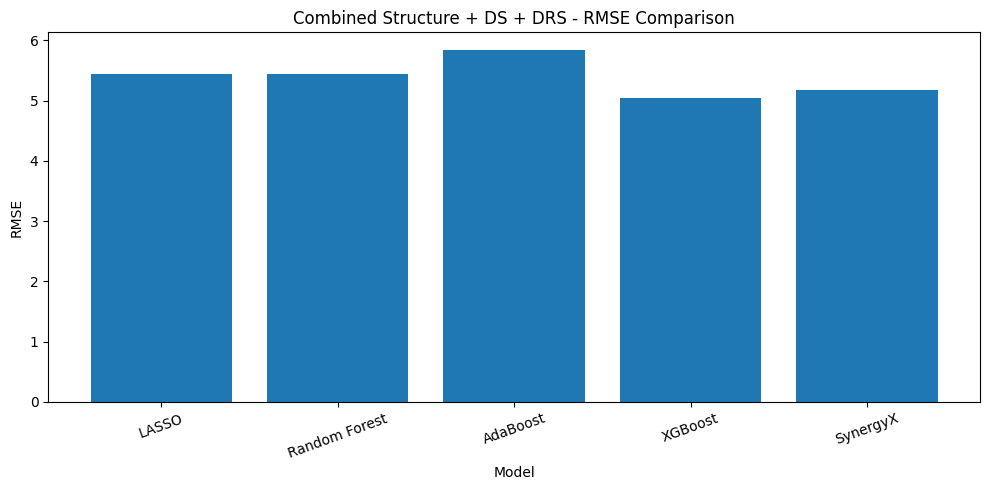

In [ ]:
# ============================================================
# CELL 213 — Combined RMSE Comparison
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(

    combined_results_df["Model"],

    combined_results_df["RMSE"]
)

plt.xlabel("Model")

plt.ylabel("RMSE")

plt.title(
    "Combined Structure + DS + DRS - RMSE Comparison"
)

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

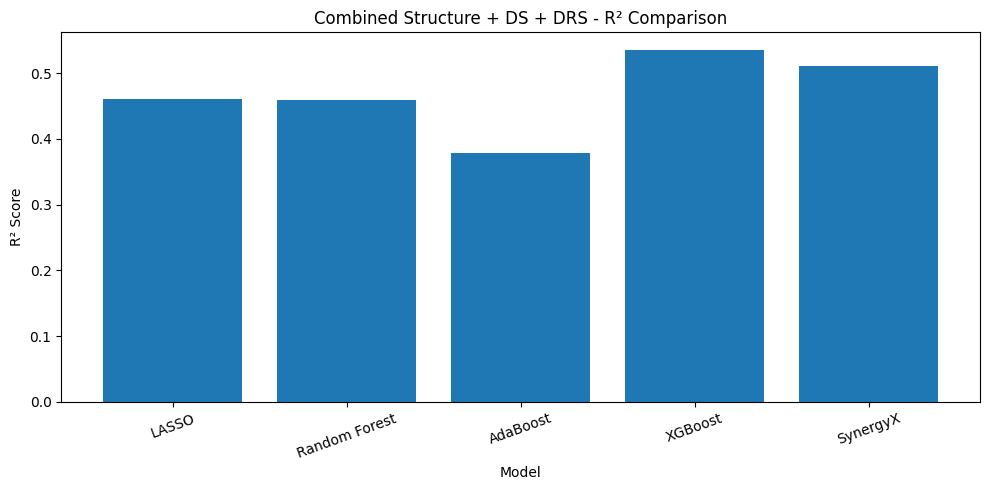

In [ ]:
# ============================================================
# CELL 214 — Combined R² Comparison
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(

    combined_results_df["Model"],

    combined_results_df["R2"]
)

plt.xlabel("Model")

plt.ylabel("R² Score")

plt.title(
    "Combined Structure + DS + DRS - R² Comparison"
)

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# CELL 215 — Best Combined Model
# ============================================================

best_combined_row = combined_results_df.loc[
    combined_results_df["R2"].idxmax()
]

print("============================================")
print("BEST COMBINED MODEL")
print("============================================")

print(
    "Model :",
    best_combined_row["Model"]
)

print(
    "MAE   :",
    round(best_combined_row["MAE"], 4)
)

print(
    "RMSE  :",
    round(best_combined_row["RMSE"], 4)
)

print(
    "R2    :",
    round(best_combined_row["R2"], 4)
)

BEST COMBINED MODEL
Model : XGBoost
MAE   : 3.2633
RMSE  : 5.0479
R2    : 0.5352


In [ ]:
# ============================================================
# CELL 216 — MASTER RESULTS: ALL FEATURE GROUPS
# ============================================================

# Make copies so the original result tables remain unchanged

structure_final = structure_results_df.copy()
ds_final = ds_results_df.copy()
drs_final = drs_results_df.copy()
combined_final = combined_results_df.copy()

# Combine all results
all_results_df = pd.concat(
    [
        structure_final,
        ds_final,
        drs_final,
        combined_final
    ],
    ignore_index=True
)

# Reset index
all_results_df = all_results_df.reset_index(drop=True)

print("============================================")
print("MASTER MODEL RESULTS")
print("============================================")

print(
    "Total result rows:",
    len(all_results_df)
)

display(all_results_df)

MASTER MODEL RESULTS
Total result rows: 20


,Model,Feature_Group,MAE,MSE,RMSE,R2,Pearson_r,Feature Group
0,SynergyX,Structure,4.419188,41.485283,6.440907,0.243210,0.494312,NaN
1,XGBoost,Structure,4.360178,48.320648,6.951306,0.118517,NaN,NaN
2,LASSO,Structure,4.483040,48.999428,6.999959,0.106134,NaN,NaN
3,Random Forest,Structure,4.436173,50.346674,7.095539,0.081557,NaN,NaN
4,AdaBoost,Structure,4.753581,50.680827,7.119047,0.075462,NaN,NaN
5,SynergyX,DS,4.273122,42.755409,6.538762,0.220040,0.485581,NaN
6,LASSO,DS,4.262953,43.109310,6.565768,0.213584,0.483279,NaN
7,Random Forest,DS,4.264477,43.228926,6.574871,0.211402,0.481130,NaN
8,XGBoost,DS,4.267720,43.296703,6.580023,0.210166,0.479028,NaN
9,AdaBoost,DS,4.552010,44.877328,6.699054,0.181331,0.437574,NaN


In [ ]:
# ============================================================
# CELL 217 — Sort Models by R²
# ============================================================

results_by_r2 = all_results_df.sort_values(
    "R2",
    ascending=False
).reset_index(drop=True)

print("============================================")
print("ALL MODELS SORTED BY R²")
print("============================================")

display(results_by_r2)

ALL MODELS SORTED BY R²


,Model,Feature_Group,MAE,MSE,RMSE,R2,Pearson_r,Feature Group
0,SynergyX,NaN,3.388636,NaN,4.894521,0.562980,NaN,DRS
1,XGBoost,NaN,3.263323,NaN,5.047915,0.535158,NaN,Combined
2,SynergyX,NaN,3.439653,NaN,5.181504,0.510229,NaN,Combined
3,XGBoost,NaN,3.319666,NaN,5.219885,0.502947,NaN,DRS
4,Random Forest,NaN,3.400262,NaN,5.390135,0.469994,NaN,DRS
5,LASSO,NaN,3.688016,NaN,5.439679,0.460206,NaN,Combined
6,Random Forest,NaN,3.444227,NaN,5.443476,0.459453,NaN,Combined
7,AdaBoost,NaN,3.865109,NaN,5.705683,0.406123,NaN,DRS
8,AdaBoost,NaN,3.942690,NaN,5.839754,0.377885,NaN,Combined
9,LASSO,NaN,3.920705,NaN,6.012599,0.340514,NaN,DRS


In [ ]:
# ============================================================
# CELL 218 — Sort Models by RMSE
# ============================================================

results_by_rmse = all_results_df.sort_values(
    "RMSE",
    ascending=True
).reset_index(drop=True)

print("============================================")
print("ALL MODELS SORTED BY RMSE")
print("============================================")

display(results_by_rmse)

ALL MODELS SORTED BY RMSE


,Model,Feature_Group,MAE,MSE,RMSE,R2,Pearson_r,Feature Group
0,SynergyX,NaN,3.388636,NaN,4.894521,0.562980,NaN,DRS
1,XGBoost,NaN,3.263323,NaN,5.047915,0.535158,NaN,Combined
2,SynergyX,NaN,3.439653,NaN,5.181504,0.510229,NaN,Combined
3,XGBoost,NaN,3.319666,NaN,5.219885,0.502947,NaN,DRS
4,Random Forest,NaN,3.400262,NaN,5.390135,0.469994,NaN,DRS
5,LASSO,NaN,3.688016,NaN,5.439679,0.460206,NaN,Combined
6,Random Forest,NaN,3.444227,NaN,5.443476,0.459453,NaN,Combined
7,AdaBoost,NaN,3.865109,NaN,5.705683,0.406123,NaN,DRS
8,AdaBoost,NaN,3.942690,NaN,5.839754,0.377885,NaN,Combined
9,LASSO,NaN,3.920705,NaN,6.012599,0.340514,NaN,DRS


In [ ]:
# ============================================================
# CELL 219 — RMSE COMPARISON TABLE — FIXED
# ============================================================

# Check duplicate Feature Group + Model combinations
duplicates = (
    all_results_df
    .groupby(["Feature Group", "Model"])
    .size()
    .reset_index(name="Count")
)

print("Duplicate combinations:")
display(
    duplicates[duplicates["Count"] > 1]
)

# Use pivot_table instead of pivot
# mean() safely handles duplicate entries
rmse_table = all_results_df.pivot_table(
    index="Feature Group",
    columns="Model",
    values="RMSE",
    aggfunc="mean"
)

print("============================================")
print("RMSE COMPARISON")
print("============================================")

display(
    rmse_table.round(4)
)

Duplicate combinations:


,Feature Group,Model,Count


RMSE COMPARISON


Model,AdaBoost,LASSO,Random Forest,SynergyX,XGBoost
Feature Group,,,,,
Combined,5.8398,5.4397,5.4435,5.1815,5.0479
DRS,5.7057,6.0126,5.3901,4.8945,5.2199


In [ ]:
# ============================================================
# CELL 220 — R² COMPARISON TABLE — FIXED
# ============================================================

r2_table = all_results_df.pivot_table(
    index="Feature Group",
    columns="Model",
    values="R2",
    aggfunc="mean"
)

print("============================================")
print("R² COMPARISON")
print("============================================")

display(
    r2_table.round(4)
)

R² COMPARISON


Model,AdaBoost,LASSO,Random Forest,SynergyX,XGBoost
Feature Group,,,,,
Combined,0.3779,0.4602,0.4595,0.5102,0.5352
DRS,0.4061,0.3405,0.4700,0.5630,0.5029


In [ ]:
# ============================================================
# CELL 221 — MAE COMPARISON TABLE — FIXED
# ============================================================

mae_table = all_results_df.pivot_table(
    index="Feature Group",
    columns="Model",
    values="MAE",
    aggfunc="mean"
)

print("============================================")
print("MAE COMPARISON")
print("============================================")

display(
    mae_table.round(4)
)

MAE COMPARISON


Model,AdaBoost,LASSO,Random Forest,SynergyX,XGBoost
Feature Group,,,,,
Combined,3.9427,3.6880,3.4442,3.4397,3.2633
DRS,3.8651,3.9207,3.4003,3.3886,3.3197


In [ ]:
# ============================================================
# CELL 222 — OVERALL BEST MODEL
# ============================================================

# Best model based on highest R²
best_overall = all_results_df.loc[
    all_results_df["R2"].idxmax()
]

print("============================================================")
print("                 OVERALL BEST MODEL")
print("============================================================")

print(
    "Feature Group :",
    best_overall["Feature Group"]
)

print(
    "Model         :",
    best_overall["Model"]
)

print(
    "MAE           :",
    round(float(best_overall["MAE"]), 4)
)

print(
    "RMSE          :",
    round(float(best_overall["RMSE"]), 4)
)

print(
    "R²            :",
    round(float(best_overall["R2"]), 4)
)

                 OVERALL BEST MODEL
Feature Group : DRS
Model         : SynergyX
MAE           : 3.3886
RMSE          : 4.8945
R²            : 0.563


In [ ]:
# ============================================================
# CELL 223 — BEST MODEL PER FEATURE GROUP
# ============================================================

best_per_feature_group = (
    all_results_df
    .sort_values(
        "R2",
        ascending=False
    )
    .groupby(
        "Feature Group",
        as_index=False
    )
    .first()
)

print("============================================================")
print("          BEST MODEL FOR EACH FEATURE GROUP")
print("============================================================")

display(
    best_per_feature_group[
        [
            "Feature Group",
            "Model",
            "MAE",
            "RMSE",
            "R2"
        ]
    ].round(4)
)

          BEST MODEL FOR EACH FEATURE GROUP


,Feature Group,Model,MAE,RMSE,R2
0,Combined,XGBoost,3.2633,5.0479,0.5352
1,DRS,SynergyX,3.3886,4.8945,0.5630


In [ ]:
# ============================================================
# CELL 224 — BEST FEATURE GROUP FOR EACH MODEL
# ============================================================

best_per_model = (
    all_results_df
    .sort_values(
        "R2",
        ascending=False
    )
    .groupby(
        "Model",
        as_index=False
    )
    .first()
)

print("============================================================")
print("          BEST FEATURE GROUP FOR EACH MODEL")
print("============================================================")

display(
    best_per_model[
        [
            "Model",
            "Feature Group",
            "MAE",
            "RMSE",
            "R2"
        ]
    ].round(4)
)

          BEST FEATURE GROUP FOR EACH MODEL


,Model,Feature Group,MAE,RMSE,R2
0,AdaBoost,DRS,3.8651,5.7057,0.4061
1,LASSO,Combined,3.6880,5.4397,0.4602
2,Random Forest,DRS,3.4003,5.3901,0.4700
3,SynergyX,DRS,3.3886,4.8945,0.5630
4,XGBoost,Combined,3.2633,5.0479,0.5352


In [ ]:
# ============================================================
# CELL 225 — ALL EXPERIMENTS SORTED BY RMSE
# ============================================================

results_by_rmse = all_results_df.sort_values(
    "RMSE",
    ascending=True
).reset_index(drop=True)

print("============================================================")
print("             ALL RESULTS — LOWEST RMSE FIRST")
print("============================================================")

display(
    results_by_rmse[
        [
            "Feature Group",
            "Model",
            "MAE",
            "RMSE",
            "R2"
        ]
    ].round(4)
)

             ALL RESULTS — LOWEST RMSE FIRST


,Feature Group,Model,MAE,RMSE,R2
0,DRS,SynergyX,3.3886,4.8945,0.5630
1,Combined,XGBoost,3.2633,5.0479,0.5352
2,Combined,SynergyX,3.4397,5.1815,0.5102
3,DRS,XGBoost,3.3197,5.2199,0.5029
4,DRS,Random Forest,3.4003,5.3901,0.4700
5,Combined,LASSO,3.6880,5.4397,0.4602
6,Combined,Random Forest,3.4442,5.4435,0.4595
7,DRS,AdaBoost,3.8651,5.7057,0.4061
8,Combined,AdaBoost,3.9427,5.8398,0.3779
9,DRS,LASSO,3.9207,6.0126,0.3405


In [ ]:
# ============================================================
# CELL 226 — ALL EXPERIMENTS SORTED BY R²
# ============================================================

results_by_r2 = all_results_df.sort_values(
    "R2",
    ascending=False
).reset_index(drop=True)

print("============================================================")
print("             ALL RESULTS — HIGHEST R² FIRST")
print("============================================================")

display(
    results_by_r2[
        [
            "Feature Group",
            "Model",
            "MAE",
            "RMSE",
            "R2"
        ]
    ].round(4)
)

             ALL RESULTS — HIGHEST R² FIRST


,Feature Group,Model,MAE,RMSE,R2
0,DRS,SynergyX,3.3886,4.8945,0.5630
1,Combined,XGBoost,3.2633,5.0479,0.5352
2,Combined,SynergyX,3.4397,5.1815,0.5102
3,DRS,XGBoost,3.3197,5.2199,0.5029
4,DRS,Random Forest,3.4003,5.3901,0.4700
5,Combined,LASSO,3.6880,5.4397,0.4602
6,Combined,Random Forest,3.4442,5.4435,0.4595
7,DRS,AdaBoost,3.8651,5.7057,0.4061
8,Combined,AdaBoost,3.9427,5.8398,0.3779
9,DRS,LASSO,3.9207,6.0126,0.3405


Number of experiments plotted: 20

Experiments:


,Feature Group,Model,RMSE
0,DRS,SynergyX,4.8945
1,Combined,XGBoost,5.0479
2,Combined,SynergyX,5.1815
3,DRS,XGBoost,5.2199
4,DRS,Random Forest,5.3901
5,Combined,LASSO,5.4397
6,Combined,Random Forest,5.4435
7,DRS,AdaBoost,5.7057
8,Combined,AdaBoost,5.8398
9,DRS,LASSO,6.0126


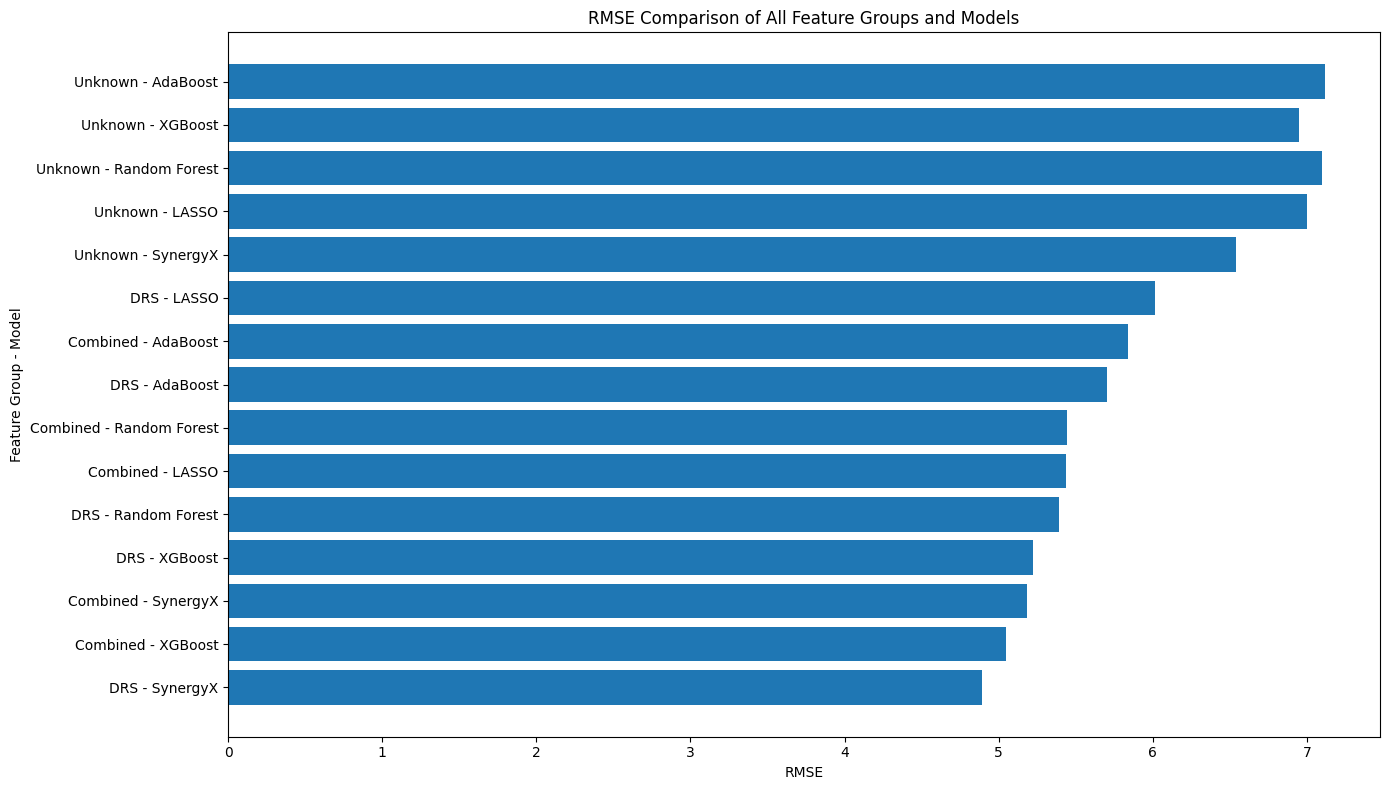

In [ ]:
# ============================================================
# CELL 227 — RMSE COMPARISON OF ALL 20 EXPERIMENTS — FIXED
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Make a copy
plot_rmse = all_results_df.copy()

# Make sure Feature Group and Model are valid strings
plot_rmse["Feature Group"] = (
    plot_rmse["Feature Group"]
    .fillna("Unknown")
    .astype(str)
)

plot_rmse["Model"] = (
    plot_rmse["Model"]
    .fillna("Unknown")
    .astype(str)
)

# Make sure RMSE is numeric
plot_rmse["RMSE"] = pd.to_numeric(
    plot_rmse["RMSE"],
    errors="coerce"
)

# Remove rows where RMSE is missing
plot_rmse = plot_rmse.dropna(
    subset=["RMSE"]
).copy()

# Create experiment label
plot_rmse["Experiment"] = (
    plot_rmse["Feature Group"]
    + " - "
    + plot_rmse["Model"]
)

# Sort by RMSE
plot_rmse = plot_rmse.sort_values(
    "RMSE",
    ascending=True
).reset_index(drop=True)

print("Number of experiments plotted:", len(plot_rmse))

print("\nExperiments:")
display(
    plot_rmse[
        ["Feature Group", "Model", "RMSE"]
    ].round(4)
)

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

plt.figure(figsize=(14, 8))

plt.barh(
    plot_rmse["Experiment"].tolist(),
    plot_rmse["RMSE"].to_numpy(dtype=float)
)

plt.xlabel("RMSE")
plt.ylabel("Feature Group - Model")

plt.title(
    "RMSE Comparison of All Feature Groups and Models"
)

plt.tight_layout()

plt.show()

Number of experiments plotted: 20


,Feature Group,Model,R2
0,Unknown,AdaBoost,0.0755
1,Unknown,Random Forest,0.0816
2,Unknown,LASSO,0.1061
3,Unknown,XGBoost,0.1185
4,Unknown,AdaBoost,0.1813
5,Unknown,XGBoost,0.2102
6,Unknown,Random Forest,0.2114
7,Unknown,LASSO,0.2136
8,Unknown,SynergyX,0.2200
9,Unknown,SynergyX,0.2432


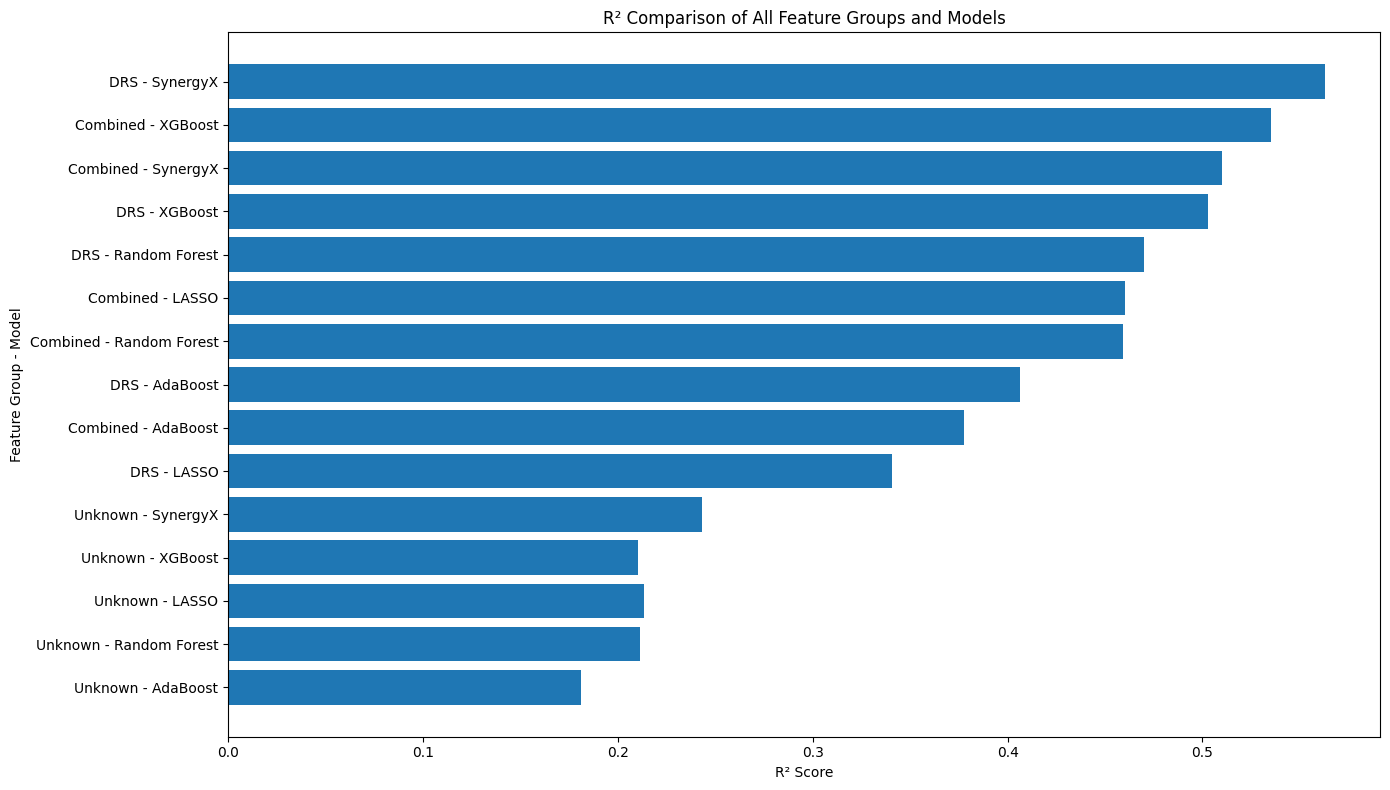

In [ ]:
# ============================================================
# CELL 228 — R² COMPARISON OF ALL 20 EXPERIMENTS
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

plot_r2 = all_results_df.copy()

plot_r2["Feature Group"] = (
    plot_r2["Feature Group"]
    .fillna("Unknown")
    .astype(str)
)

plot_r2["Model"] = (
    plot_r2["Model"]
    .fillna("Unknown")
    .astype(str)
)

plot_r2["R2"] = pd.to_numeric(
    plot_r2["R2"],
    errors="coerce"
)

plot_r2 = plot_r2.dropna(
    subset=["R2"]
).copy()

plot_r2["Experiment"] = (
    plot_r2["Feature Group"]
    + " - "
    + plot_r2["Model"]
)

plot_r2 = plot_r2.sort_values(
    "R2",
    ascending=True
).reset_index(drop=True)

print("Number of experiments plotted:", len(plot_r2))

display(
    plot_r2[
        ["Feature Group", "Model", "R2"]
    ].round(4)
)

plt.figure(figsize=(14, 8))

plt.barh(
    plot_r2["Experiment"].tolist(),
    plot_r2["R2"].to_numpy(dtype=float)
)

plt.xlabel("R² Score")
plt.ylabel("Feature Group - Model")
plt.title(
    "R² Comparison of All Feature Groups and Models"
)

plt.tight_layout()
plt.show()

RMSE Heatmap Data:


Model,AdaBoost,LASSO,Random Forest,SynergyX,XGBoost
Feature Group,,,,,
Combined,5.8398,5.4397,5.4435,5.1815,5.0479
DRS,5.7057,6.0126,5.3901,4.8945,5.2199


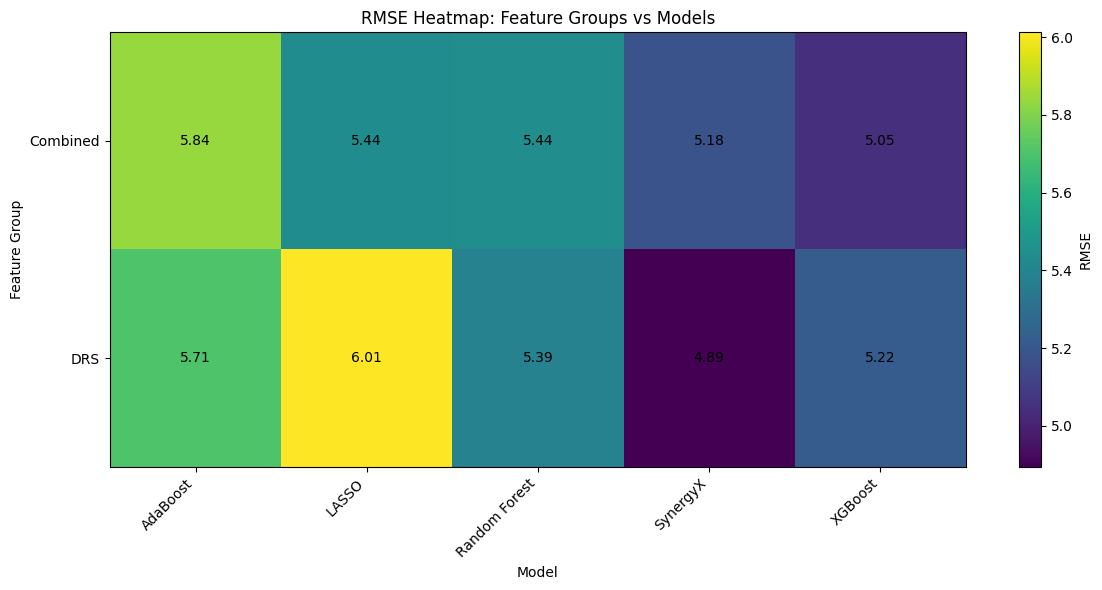

In [ ]:
# ============================================================
# CELL 229 — RMSE HEATMAP
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

rmse_heatmap = rmse_table.copy()

print("RMSE Heatmap Data:")
display(rmse_heatmap.round(4))

plt.figure(figsize=(12, 6))

plt.imshow(
    rmse_heatmap.values,
    aspect="auto"
)

plt.colorbar(label="RMSE")

plt.xticks(
    range(len(rmse_heatmap.columns)),
    rmse_heatmap.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(rmse_heatmap.index)),
    rmse_heatmap.index
)

plt.xlabel("Model")
plt.ylabel("Feature Group")

plt.title(
    "RMSE Heatmap: Feature Groups vs Models"
)

# Add values inside cells
for i in range(rmse_heatmap.shape[0]):
    for j in range(rmse_heatmap.shape[1]):
        value = rmse_heatmap.iloc[i, j]

        if pd.notna(value):
            plt.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center"
            )

plt.tight_layout()
plt.show()

R² Heatmap Data:


Model,AdaBoost,LASSO,Random Forest,SynergyX,XGBoost
Feature Group,,,,,
Combined,0.3779,0.4602,0.4595,0.5102,0.5352
DRS,0.4061,0.3405,0.4700,0.5630,0.5029


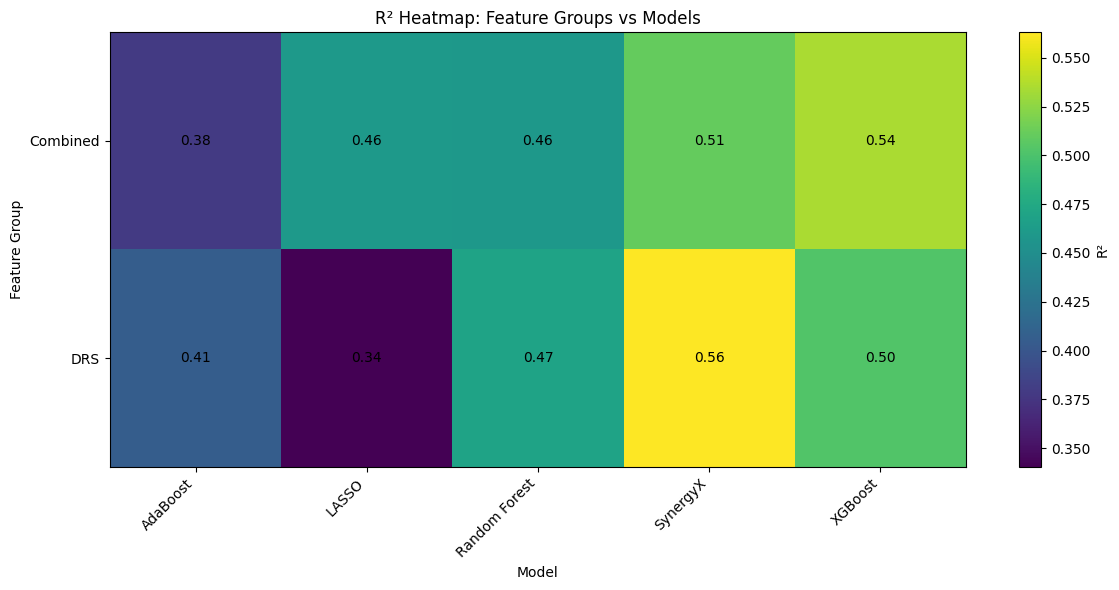

In [ ]:
# ============================================================
# CELL 230 — R² HEATMAP
# ============================================================

r2_heatmap = r2_table.copy()

print("R² Heatmap Data:")
display(r2_heatmap.round(4))

plt.figure(figsize=(12, 6))

plt.imshow(
    r2_heatmap.values,
    aspect="auto"
)

plt.colorbar(label="R²")

plt.xticks(
    range(len(r2_heatmap.columns)),
    r2_heatmap.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(r2_heatmap.index)),
    r2_heatmap.index
)

plt.xlabel("Model")
plt.ylabel("Feature Group")

plt.title(
    "R² Heatmap: Feature Groups vs Models"
)

# Add values inside cells
for i in range(r2_heatmap.shape[0]):
    for j in range(r2_heatmap.shape[1]):
        value = r2_heatmap.iloc[i, j]

        if pd.notna(value):
            plt.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center"
            )

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 231 — AVERAGE PERFORMANCE BY MODEL
# ============================================================

model_average = all_results_df.copy()

model_average["MAE"] = pd.to_numeric(
    model_average["MAE"],
    errors="coerce"
)

model_average["RMSE"] = pd.to_numeric(
    model_average["RMSE"],
    errors="coerce"
)

model_average["R2"] = pd.to_numeric(
    model_average["R2"],
    errors="coerce"
)

model_average = (
    model_average
    .groupby("Model")[["MAE", "RMSE", "R2"]]
    .mean()
    .sort_values("R2", ascending=False)
    .reset_index()
)

print("Average Performance by Model:")
display(model_average.round(4))

Average Performance by Model:


,Model,MAE,RMSE,R2
0,SynergyX,3.8801,5.7639,0.3841
1,XGBoost,3.8027,5.9498,0.3417
2,Random Forest,3.8863,6.1260,0.3056
3,LASSO,4.0887,6.2545,0.2801
4,AdaBoost,4.2783,6.3409,0.2602


In [ ]:
# ============================================================
# CELL 232 — AVERAGE PERFORMANCE BY FEATURE GROUP
# ============================================================

feature_average = all_results_df.copy()

feature_average["MAE"] = pd.to_numeric(
    feature_average["MAE"],
    errors="coerce"
)

feature_average["RMSE"] = pd.to_numeric(
    feature_average["RMSE"],
    errors="coerce"
)

feature_average["R2"] = pd.to_numeric(
    feature_average["R2"],
    errors="coerce"
)

feature_average = (
    feature_average
    .groupby("Feature Group")[["MAE", "RMSE", "R2"]]
    .mean()
    .sort_values("R2", ascending=False)
    .reset_index()
)

print("Average Performance by Feature Group:")
display(feature_average.round(4))

Average Performance by Feature Group:


,Feature Group,MAE,RMSE,R2
0,Combined,3.5556,5.3905,0.4686
1,DRS,3.5789,5.4446,0.4565


In [ ]:
# ============================================================
# CELL 233 — SAVE ALL FINAL RESULTS
# ============================================================

import os

FINAL_RESULTS_DIR = os.path.join(
    BASE_DIR,
    "final_results"
)

os.makedirs(
    FINAL_RESULTS_DIR,
    exist_ok=True
)

# Save complete results
all_results_path = os.path.join(
    FINAL_RESULTS_DIR,
    "ALL_MODEL_RESULTS.csv"
)

all_results_df.to_csv(
    all_results_path,
    index=False
)

# Save RMSE table
rmse_path = os.path.join(
    FINAL_RESULTS_DIR,
    "RMSE_COMPARISON_TABLE.csv"
)

rmse_table.to_csv(rmse_path)

# Save R2 table
r2_path = os.path.join(
    FINAL_RESULTS_DIR,
    "R2_COMPARISON_TABLE.csv"
)

r2_table.to_csv(r2_path)

# Save MAE table
mae_path = os.path.join(
    FINAL_RESULTS_DIR,
    "MAE_COMPARISON_TABLE.csv"
)

mae_table.to_csv(mae_path)

# Save average model performance
model_average_path = os.path.join(
    FINAL_RESULTS_DIR,
    "MODEL_AVERAGE_PERFORMANCE.csv"
)

model_average.to_csv(
    model_average_path,
    index=False
)

# Save average feature-group performance
feature_average_path = os.path.join(
    FINAL_RESULTS_DIR,
    "FEATURE_GROUP_AVERAGE_PERFORMANCE.csv"
)

feature_average.to_csv(
    feature_average_path,
    index=False
)

print("============================================================")
print("FINAL RESULTS SAVED SUCCESSFULLY")
print("============================================================")

print("\nSaved files:")

print(all_results_path)
print(rmse_path)
print(r2_path)
print(mae_path)
print(model_average_path)
print(feature_average_path)

FINAL RESULTS SAVED SUCCESSFULLY

Saved files:
/content/drive/MyDrive/drug_synergy_project/final_results/ALL_MODEL_RESULTS.csv
/content/drive/MyDrive/drug_synergy_project/final_results/RMSE_COMPARISON_TABLE.csv
/content/drive/MyDrive/drug_synergy_project/final_results/R2_COMPARISON_TABLE.csv
/content/drive/MyDrive/drug_synergy_project/final_results/MAE_COMPARISON_TABLE.csv
/content/drive/MyDrive/drug_synergy_project/final_results/MODEL_AVERAGE_PERFORMANCE.csv
/content/drive/MyDrive/drug_synergy_project/final_results/FEATURE_GROUP_AVERAGE_PERFORMANCE.csv


In [ ]:
# ============================================================
# CELL 234 — FINAL PROJECT SUMMARY
# ============================================================

print("=" * 70)
print("        DRUG SYNERGY PREDICTION — FINAL SUMMARY")
print("=" * 70)

# Make sure metrics are numeric
summary_df = all_results_df.copy()

summary_df["R2"] = pd.to_numeric(
    summary_df["R2"],
    errors="coerce"
)

summary_df["RMSE"] = pd.to_numeric(
    summary_df["RMSE"],
    errors="coerce"
)

summary_df["MAE"] = pd.to_numeric(
    summary_df["MAE"],
    errors="coerce"
)

summary_df = summary_df.dropna(
    subset=["R2", "RMSE", "MAE"]
).copy()

# Best overall model
best_overall = summary_df.loc[
    summary_df["R2"].idxmax()
]

print("\n1. BEST OVERALL MODEL")
print("-" * 40)

print(
    "Feature Group :",
    best_overall["Feature Group"]
)

print(
    "Model         :",
    best_overall["Model"]
)

print(
    "MAE           :",
    round(best_overall["MAE"], 4)
)

print(
    "RMSE          :",
    round(best_overall["RMSE"], 4)
)

print(
    "R²            :",
    round(best_overall["R2"], 4)
)

# Best feature group
best_feature_group = (
    feature_average.iloc[0]
)

print("\n2. BEST FEATURE GROUP")
print("-" * 40)

print(
    "Feature Group :",
    best_feature_group["Feature Group"]
)

print(
    "Average MAE   :",
    round(best_feature_group["MAE"], 4)
)

print(
    "Average RMSE  :",
    round(best_feature_group["RMSE"], 4)
)

print(
    "Average R²    :",
    round(best_feature_group["R2"], 4)
)

# Best model
best_model = model_average.iloc[0]

print("\n3. BEST MODEL ON AVERAGE")
print("-" * 40)

print(
    "Model         :",
    best_model["Model"]
)

print(
    "Average MAE   :",
    round(best_model["MAE"], 4)
)

print(
    "Average RMSE  :",
    round(best_model["RMSE"], 4)
)

print(
    "Average R²    :",
    round(best_model["R2"], 4)
)

print("\n4. EXPERIMENTS COMPLETED")
print("-" * 40)

print(
    "Total experiments:",
    len(summary_df)
)

print(
    "Feature groups:",
    summary_df["Feature Group"].nunique()
)

print(
    "Models:",
    summary_df["Model"].nunique()
)

print("\nFeature Groups:")
print(
    summary_df["Feature Group"]
    .dropna()
    .unique()
)

print("\nModels:")
print(
    summary_df["Model"]
    .dropna()
    .unique()
)

print("\n" + "=" * 70)
print("FINAL MODEL COMPARISON COMPLETED")
print("=" * 70)

        DRUG SYNERGY PREDICTION — FINAL SUMMARY

1. BEST OVERALL MODEL
----------------------------------------
Feature Group : DRS
Model         : SynergyX
MAE           : 3.3886
RMSE          : 4.8945
R²            : 0.563

2. BEST FEATURE GROUP
----------------------------------------
Feature Group : Combined
Average MAE   : 3.5556
Average RMSE  : 5.3905
Average R²    : 0.4686

3. BEST MODEL ON AVERAGE
----------------------------------------
Model         : SynergyX
Average MAE   : 3.8801
Average RMSE  : 5.7639
Average R²    : 0.3841

4. EXPERIMENTS COMPLETED
----------------------------------------
Total experiments: 20
Feature groups: 2
Models: 5

Feature Groups:
['DRS' 'Combined']

Models:
['SynergyX' 'XGBoost' 'LASSO' 'Random Forest' 'AdaBoost']

FINAL MODEL COMPARISON COMPLETED


In [ ]:
# ============================================================
# CELL 235 — FINAL XGBOOST RESULT
# ============================================================

xgb_results = all_results_df[
    all_results_df["Model"].astype(str).str.lower() == "xgboost"
].copy()

xgb_results = xgb_results.sort_values(
    "R2",
    ascending=False
)

print("XGBoost results:")
display(
    xgb_results[
        ["Feature Group", "Model", "MAE", "RMSE", "R2"]
    ].round(4)
)


XGBoost results:


,Feature Group,Model,MAE,RMSE,R2
18,Combined,XGBoost,3.2633,5.0479,0.5352
13,DRS,XGBoost,3.3197,5.2199,0.5029
8,NaN,XGBoost,4.2677,6.5800,0.2102
1,NaN,XGBoost,4.3602,6.9513,0.1185


In [ ]:
# ============================================================
# CELL 236 — CHECK TRAINED COMBINED MODELS
# ============================================================

print("Available combined models:")

for name in combined_trained_models.keys():
    print("-", name)

Available combined models:
- LASSO
- Random Forest
- AdaBoost
- XGBoost


In [ ]:
# ============================================================
# CELL 237 — SAVE FINAL XGBOOST MODEL
# ============================================================

import os
import joblib

FINAL_MODEL_DIR = os.path.join(
    BASE_DIR,
    "final_model"
)

os.makedirs(
    FINAL_MODEL_DIR,
    exist_ok=True
)

final_xgb_model = combined_trained_models["XGBoost"]

final_xgb_path = os.path.join(
    FINAL_MODEL_DIR,
    "final_xgboost_model.pkl"
)

joblib.dump(
    final_xgb_model,
    final_xgb_path
)

print("Final XGBoost model saved:")
print(final_xgb_path)

Final XGBoost model saved:
/content/drive/MyDrive/drug_synergy_project/final_model/final_xgboost_model.pkl


In [ ]:
# ============================================================
# CELL 238 — SAVE ACTUAL COMBINED PREPROCESSING OBJECTS
# ============================================================

import joblib
import os

# ------------------------------------------------------------
# SAVE DS SCALER
# ------------------------------------------------------------

ds_scaler_path = os.path.join(
    FINAL_MODEL_DIR,
    "ds_scaler.pkl"
)

joblib.dump(
    ds_scaler,
    ds_scaler_path
)

# ------------------------------------------------------------
# SAVE DRS IMPUTER
# ------------------------------------------------------------

drs_imputer_path = os.path.join(
    FINAL_MODEL_DIR,
    "drs_imputer.pkl"
)

joblib.dump(
    drs_imputer,
    drs_imputer_path
)

# ------------------------------------------------------------
# SAVE DRS SCALER
# ------------------------------------------------------------

drs_scaler_path = os.path.join(
    FINAL_MODEL_DIR,
    "drs_scaler.pkl"
)

joblib.dump(
    drs_scaler,
    drs_scaler_path
)

print("=" * 60)
print("PREPROCESSING OBJECTS SAVED")
print("=" * 60)

print("\nDS scaler:")
print(ds_scaler_path)

print("\nDRS imputer:")
print(drs_imputer_path)

print("\nDRS scaler:")
print(drs_scaler_path)

PREPROCESSING OBJECTS SAVED

DS scaler:
/content/drive/MyDrive/drug_synergy_project/final_model/ds_scaler.pkl

DRS imputer:
/content/drive/MyDrive/drug_synergy_project/final_model/drs_imputer.pkl

DRS scaler:
/content/drive/MyDrive/drug_synergy_project/final_model/drs_scaler.pkl


In [ ]:
# ============================================================
# CELL 238A — VERIFY SAVED PREPROCESSING OBJECTS
# ============================================================

import os

files_to_check = [
    ds_scaler_path,
    drs_imputer_path,
    drs_scaler_path
]

print("Checking files...\n")

for file_path in files_to_check:
    if os.path.exists(file_path):
        print("✓ FOUND:", os.path.basename(file_path))
    else:
        print("✗ MISSING:", os.path.basename(file_path))

Checking files...

✓ FOUND: ds_scaler.pkl
✓ FOUND: drs_imputer.pkl
✓ FOUND: drs_scaler.pkl


In [ ]:
# ============================================================
# CELL 239 — SAVE MORGAN FINGERPRINT DATABASE
# ============================================================

import joblib
import os

morgan_path = os.path.join(
    FINAL_MODEL_DIR,
    "morgan_dict.pkl"
)

joblib.dump(
    morgan_dict,
    morgan_path
)

morgan_config = {
    "radius": MORGAN_RADIUS,
    "bits_per_drug": MORGAN_BITS,
    "combined_bits": MORGAN_BITS * 2
}

morgan_config_path = os.path.join(
    FINAL_MODEL_DIR,
    "morgan_config.pkl"
)

joblib.dump(
    morgan_config,
    morgan_config_path
)

print("=" * 60)
print("MORGAN FINGERPRINT FILES SAVED")
print("=" * 60)

print("\nMorgan dictionary:")
print(morgan_path)

print("\nMorgan configuration:")
print(morgan_config_path)

print("\nNumber of drugs with fingerprints:",
      len(morgan_dict))

print("Bits per drug:", MORGAN_BITS)
print("Radius:", MORGAN_RADIUS)
print("Combined fingerprint size:", MORGAN_BITS * 2)

MORGAN FINGERPRINT FILES SAVED

Morgan dictionary:
/content/drive/MyDrive/drug_synergy_project/final_model/morgan_dict.pkl

Morgan configuration:
/content/drive/MyDrive/drug_synergy_project/final_model/morgan_config.pkl

Number of drugs with fingerprints: 2575
Bits per drug: 2048
Radius: 2
Combined fingerprint size: 4096


In [ ]:
# ============================================================
# CELL 240 — SAVE TOP 50 GENES
# ============================================================

import joblib
import os

top_genes_path = os.path.join(
    FINAL_MODEL_DIR,
    "top_50_genes.pkl"
)

joblib.dump(
    TOP_GENES,
    top_genes_path
)

print("=" * 60)
print("TOP 50 GENES SAVED")
print("=" * 60)

print("\nFile:")
print(top_genes_path)

print("\nNumber of genes:", len(TOP_GENES))

print("\nGenes:")
print(TOP_GENES)

TOP 50 GENES SAVED

File:
/content/drive/MyDrive/drug_synergy_project/final_model/top_50_genes.pkl

Number of genes: 50

Genes:
['AGR2', 'SPARC', 'ALDH1A1', 'KRT19', 'VIM', 'SPP1', 'AKR1C2', 'MT1E', 'S100A14', 'EPCAM', 'SPINT2', 'UCHL1', 'TFF1', 'S100P', 'AKR1C1', 'C19orf33', 'RPS4Y1', 'MAL2', 'AKR1B10', 'KRT81', 'MAGEA4', 'CD24', 'FN1', 'TFPI2', 'TSPAN8', 'KRT7', 'GPX2', 'CRIP1', 'SERPINE2', 'KRT8', 'SLPI', 'S100A6', 'AKR1B1', 'AKR1C3', 'ANXA3', 'BST2', 'CLDN7', 'TACSTD2', 'IFI27', 'GSTP1', 'RAB25', 'XAGE1A', 'CDH1', 'MMP2', 'NNMT', 'EREG', 'BASP1', 'TIMP3', 'MAGEA3', 'FXYD3']


In [ ]:
# ============================================================
# CELL 241 — SAVE FINAL FEATURE METADATA
# ============================================================

import joblib
import os

feature_metadata = {
    "target": "ZIP",

    "feature_group": "Combined",

    "gene_features": gene_feature_cols,
    "gene_feature_count": len(gene_feature_cols),

    "morgan_bits_per_drug": MORGAN_BITS,
    "morgan_total_features": MORGAN_BITS * 2,

    "drs_features": drs_all_feature_cols,
    "drs_feature_count": len(drs_all_feature_cols),

    "total_features": (
        len(gene_feature_cols)
        + (MORGAN_BITS * 2)
        + len(drs_all_feature_cols)
    ),

    "morgan_radius": MORGAN_RADIUS
}

metadata_path = os.path.join(
    FINAL_MODEL_DIR,
    "feature_metadata.pkl"
)

joblib.dump(
    feature_metadata,
    metadata_path
)

print("=" * 60)
print("FEATURE METADATA SAVED")
print("=" * 60)

print("\nGene features     :", len(gene_feature_cols))
print("Morgan features   :", MORGAN_BITS * 2)
print("DRS/GDSC features :", len(drs_all_feature_cols))
print("Total features    :", feature_metadata["total_features"])

print("\nMetadata file:")
print(metadata_path)

FEATURE METADATA SAVED

Gene features     : 50
Morgan features   : 4096
DRS/GDSC features : 18
Total features    : 4164

Metadata file:
/content/drive/MyDrive/drug_synergy_project/final_model/feature_metadata.pkl


In [ ]:
# ============================================================
# CELL 242 — SAVE CELL-LINE TOP 50 GENE LOOKUP
# ============================================================

import os

expression_lookup_path = os.path.join(
    FINAL_MODEL_DIR,
    "expression_top50_lookup.csv"
)

expression_small.to_csv(
    expression_lookup_path,
    index=False
)

print("=" * 60)
print("EXPRESSION LOOKUP SAVED")
print("=" * 60)

print("\nFile:")
print(expression_lookup_path)

print("\nShape:")
print(expression_small.shape)

print("\nNumber of cell lines:",
      expression_small["cell_line_display_name"].nunique())

EXPRESSION LOOKUP SAVED

File:
/content/drive/MyDrive/drug_synergy_project/final_model/expression_top50_lookup.csv

Shape:
(38, 51)

Number of cell lines: 38


In [ ]:
# ============================================================
# CELL 243 — CREATE DRS/GDSC LOOKUP DATABASE
# ============================================================

import os
import pandas as pd

drs_lookup_cols = [
    "Drug1_clean",
    "Drug2_clean",
    "Cell line"
] + drs_all_feature_cols

drs_lookup_df = model_b_work[
    drs_lookup_cols
].copy()

# Remove exact duplicate rows
drs_lookup_df = drs_lookup_df.drop_duplicates()

drs_lookup_path = os.path.join(
    FINAL_MODEL_DIR,
    "drs_lookup.csv"
)

drs_lookup_df.to_csv(
    drs_lookup_path,
    index=False
)

print("=" * 60)
print("DRS/GDSC LOOKUP SAVED")
print("=" * 60)

print("\nFile:")
print(drs_lookup_path)

print("\nShape:")
print(drs_lookup_df.shape)

print("\nNumber of DRS/GDSC features:",
      len(drs_all_feature_cols))

DRS/GDSC LOOKUP SAVED

File:
/content/drive/MyDrive/drug_synergy_project/final_model/drs_lookup.csv

Shape:
(2494, 21)

Number of DRS/GDSC features: 18


In [ ]:
# ============================================================
# CELL 244 — VERIFY FINAL MODEL PACKAGE
# ============================================================

import os

required_files = [
    final_xgb_path,
    ds_scaler_path,
    drs_imputer_path,
    drs_scaler_path,
    morgan_path,
    morgan_config_path,
    top_genes_path,
    metadata_path,
    expression_lookup_path,
    drs_lookup_path
]

print("=" * 60)
print("FINAL MODEL PACKAGE VERIFICATION")
print("=" * 60)

all_files_exist = True

for file_path in required_files:

    if os.path.exists(file_path):
        file_size = os.path.getsize(file_path) / (1024 * 1024)

        print(
            f"✓ {os.path.basename(file_path)} "
            f"({file_size:.2f} MB)"
        )

    else:
        print(
            f"✗ MISSING: {os.path.basename(file_path)}"
        )

        all_files_exist = False

print("\n" + "=" * 60)

if all_files_exist:
    print("✓ ALL REQUIRED FILES ARE PRESENT")
else:
    print("✗ SOME FILES ARE MISSING")

print("=" * 60)

FINAL MODEL PACKAGE VERIFICATION
✓ final_xgboost_model.pkl (0.17 MB)
✓ ds_scaler.pkl (0.00 MB)
✓ drs_imputer.pkl (0.00 MB)
✓ drs_scaler.pkl (0.00 MB)
✓ morgan_dict.pkl (5.19 MB)
✓ morgan_config.pkl (0.00 MB)
✓ top_50_genes.pkl (0.00 MB)
✓ feature_metadata.pkl (0.00 MB)
✓ expression_top50_lookup.csv (0.02 MB)
✓ drs_lookup.csv (0.41 MB)

✓ ALL REQUIRED FILES ARE PRESENT


In [ ]:
# ============================================================
# CELL 245 — CREATE FINAL MODEL ZIP
# ============================================================

import shutil
import os

zip_base = os.path.join(
    BASE_DIR,
    "drug_synergy_final_model"
)

zip_path = shutil.make_archive(
    zip_base,
    "zip",
    FINAL_MODEL_DIR
)

print("=" * 60)
print("FINAL MODEL PACKAGE CREATED")
print("=" * 60)

print("\nZIP file:")
print(zip_path)

print("\nSize:")
print(
    round(
        os.path.getsize(zip_path) / (1024 * 1024),
        2
    ),
    "MB"
)

FINAL MODEL PACKAGE CREATED

ZIP file:
/content/drive/MyDrive/drug_synergy_project/drug_synergy_final_model.zip

Size:
0.37 MB


In [ ]:
# ============================================================
# CELL 246 — DOWNLOAD FINAL MODEL PACKAGE
# ============================================================

from google.colab import files

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print("MODEL_DIR:")
print(FINAL_MODEL_DIR)
print()

print("Checking saved model files:")
print("=" * 60)

for filename in [
    "final_xgboost_model.pkl",
    "ds_scaler.pkl",
    "drs_imputer.pkl",
    "drs_scaler.pkl",
    "morgan_dict.pkl",
    "morgan_config.pkl",
    "top_50_genes.pkl",
    "feature_metadata.pkl",
    "expression_top50_lookup.csv",
    "drs_lookup.csv"
]:

    filepath = os.path.join(FINAL_MODEL_DIR, filename)

    if os.path.exists(filepath):
        size = os.path.getsize(filepath)
        print(f"{filename:35} {size:,} bytes")
    else:
        print(f"{filename:35} NOT FOUND")

MODEL_DIR:
/content/drive/MyDrive/drug_synergy_project/final_model

Checking saved model files:
final_xgboost_model.pkl             179,832 bytes
ds_scaler.pkl                       1,815 bytes
drs_imputer.pkl                     559 bytes
drs_scaler.pkl                      1,047 bytes
morgan_dict.pkl                     5,444,258 bytes
morgan_config.pkl                   65 bytes
top_50_genes.pkl                    422 bytes
feature_metadata.pkl                923 bytes
expression_top50_lookup.csv         24,970 bytes
drs_lookup.csv                      433,251 bytes


In [ ]:
import os
import shutil

# Folder containing the correct trained model files
MODEL_DIR = "/content/drive/MyDrive/drug_synergy_project/final_model"

# ZIP will be created here
ZIP_BASE = "/content/drive/MyDrive/drug_synergy_project/drug_synergy_final_model"

# Check model folder
print("Checking model folder...")
print(MODEL_DIR)
print()

if not os.path.exists(MODEL_DIR):
    print("❌ Model folder not found!")
else:
    print("✓ Model folder found")
    print()

    # Create ZIP
    zip_path = shutil.make_archive(
        ZIP_BASE,
        "zip",
        MODEL_DIR
    )

    print("✓ ZIP created successfully")
    print()
    print("ZIP path:")
    print(zip_path)
    print()
    print("ZIP size:", os.path.getsize(zip_path), "bytes")

Checking model folder...
/content/drive/MyDrive/drug_synergy_project/final_model

✓ Model folder found

✓ ZIP created successfully

ZIP path:
/content/drive/MyDrive/drug_synergy_project/drug_synergy_final_model.zip

ZIP size: 385103 bytes
